# F1 Podium Prediction — Milestone 1

**What are we trying to do?** For every driver in every Formula 1 race, predict one thing: *will this driver finish on the podium (1st, 2nd or 3rd)?*

**The catch:** the model may only use what is known **before the race starts**, meaning after qualifying is over and the starting grid is set. Anything that happens during or after the race (finishing position, laps completed, points, why someone retired) cannot be an input. Using it would be cheating: the model would look great in testing and be useless in real life. This mistake is called **leakage**.

**How the notebook is organised**

| Sections | What happens there |
|---|---|
| 1–2 | Setup, and loading the 14 raw CSV files |
| 3–9 | Getting to know the data: what's in it, what's missing, what's broken |
| 10 | Defining exactly which information counts as "before the race" |
| 11 | Cleaning the data (on copies, the original files are never touched) |
| 12 | Log of every decision we made and why |
| 13 | Three questions about F1 history, answered on the cleaned data (front row → podium, home advantage, car reliability) |
| 14–15 | Building the table the models learn from, and preparing the features |
| 16–17 | Training and comparing models: a simple baseline, logistic regression, random forest, a small neural network |

Run it top to bottom; every figure is recreated on each run. Longer write-ups are in `docs/` (decisions, leakage rules, method notes).

**Words that come up a lot**
- **Driver-race / entry**: one driver in one race. That's one row in our final table.
- **`\N`**: how this dataset writes "no value" instead of leaving the cell empty. We call placeholders like this *sentinels*.
- **Grid**: the slot a driver starts the race from (1 = pole position, at the very front). `grid = 0` means they did not start from a normal slot.
- **`positionOrder`**: the driver's final order in the race (1, 2, 3, …). Podium means `positionOrder <= 3`.
- **Gate 1.A, D3, M2, …**: labels for checkpoints and decisions in our plan, so they can be looked up in `docs/decisions.md` or in the decision log (§12). You can skip the label and just read the explanation next to it.

## 1. Setup

Install and import the libraries, fix the random seed so every run gives the same numbers, and work out where the data files are (on Kaggle or on our own machine).

In [1]:
!pip install -q shap lime missingno
%matplotlib inline

# --- Data handling and plotting ----------------------------------------------
import glob
import hashlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats  # used for the confidence intervals in §13 (comes with scikit-learn)
try:
    import missingno as msno
except ImportError:  # the !pip above sometimes installs into a different Python, so install it into this one
    import sys, subprocess
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "missingno"])
    import missingno as msno

# --- Classic machine learning; imported here so all versions print together
import sklearn
from sklearn.linear_model import LogisticRegression  # used for the Q2 home-advantage analysis

# --- Neural networks. Kaggle has TensorFlow; locally it may be missing, so don't crash
try:
    import tensorflow as tf
    from tensorflow import keras
    TF_OK = True
except Exception as _tf_err:
    tf = None
    TF_OK = False
    print(f"(tensorflow not available in this session: {_tf_err})")

# --- Explaining model predictions; installed by the !pip line at the top
import shap
import lime

# --- Fix the random seed so every run gives the same numbers -----------------
SEED = 42
RANDOM_STATE = SEED
np.random.seed(SEED)
if TF_OK:
    tf.random.set_seed(SEED)

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 170)
pd.set_option("display.max_rows", 300)
plt.rcParams["savefig.bbox"] = "tight"  # saved figures never crop titles, labels or legends

# --- Where is the data? (Kaggle or our own machine) --------------------------
# On Kaggle the 14 CSV files are somewhere under /kaggle/input, so we search for them.
# On our own machine they are in data/raw/. Nothing else differs between the two.
kaggle_hits = glob.glob("/kaggle/input/**/results.csv", recursive=True)
if kaggle_hits:
    RAW_DIR = Path(kaggle_hits[0]).parent
    ON_KAGGLE = True
else:
    HERE = Path.cwd().resolve()       # if we're running inside notebooks/, step up to the project folder
    ROOT = HERE.parent if HERE.name == "notebooks" else HERE
    RAW_DIR = ROOT / "data" / "raw"
    ON_KAGGLE = False

# --- Where to save figures (they are recreated on every run) ----------------
WORKING = Path("/kaggle/working") if ON_KAGGLE else (ROOT / "notebooks" / "_working_local")
FIG_DIR = WORKING / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

print(f"ON_KAGGLE = {ON_KAGGLE}")
print(f"RAW_DIR   = {RAW_DIR} ({len(list(RAW_DIR.glob('*.csv')))} CSVs, read-only)")
print(f"FIG_DIR   = {FIG_DIR}")
print(f"SEED      = {SEED}")
# Print library versions so others can reproduce our exact setup
import matplotlib
from importlib.metadata import version as _pkgv
print(f"pandas={pd.__version__} numpy={np.__version__} sklearn={sklearn.__version__} "
      f"matplotlib={matplotlib.__version__} seaborn={sns.__version__} missingno={msno.__version__}")
print(f"shap={shap.__version__} lime={_pkgv('lime')} "
      f"tensorflow={(tf.__version__ if TF_OK else 'not installed in this session')}")

I0000 00:00:1791749903.096540  105723 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791749903.577414  105723 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1791749905.063740  105723 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


ON_KAGGLE = False
RAW_DIR   = /home/nour/CSEN903/data/raw (14 CSVs, read-only)
FIG_DIR   = /home/nour/CSEN903/notebooks/_working_local/figures
SEED      = 42
pandas=3.0.6 numpy=2.5.4 sklearn=1.9.1 matplotlib=3.11.2 seaborn=0.13.2 missingno=0.5.2
shap=0.53.0 lime=0.2.0.1 tensorflow=2.21.0


/tmp/claude-1000/-home-nour-CSEN903/a947f7a7-7ed9-4686-b5fb-9ad5982be7be/scratchpad/tfenv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Load the raw data

Read all 14 CSV files into a dictionary called `data` (for example `data["results"]`). Everything is read **as plain text, on purpose**, so the `\N` placeholders stay visible and pandas doesn't convert anything quietly. The real cleaning happens later in §11, on copies.

We also take a fingerprint (SHA-256 checksum) of every file. The very last cell of the notebook checks them again to prove the original files were never changed.

The second table shows how big each table is and how many `\N` placeholders it contains.

In [2]:
# The 14 tables in the dataset, one CSV file each
TABLES = [
    "circuits", "constructors", "constructor_results", "constructor_standings",
    "drivers", "driver_standings", "races", "results", "qualifying",
    "lap_times", "pit_stops", "seasons", "sprint_results", "status",
]

csv_paths = {t: RAW_DIR / f"{t}.csv" for t in TABLES}
# Stop right away if any file is missing
missing = [str(v) for v in csv_paths.values() if not v.exists()]
assert not missing, f"missing CSVs: {missing} (RAW_DIR={RAW_DIR})"

# Read everything as plain text and don't let pandas guess what counts as missing,
# so the dataset's "\N" placeholders stay exactly as they are in the file.
data = {t: pd.read_csv(csv_paths[t], dtype=str, keep_default_na=False) for t in TABLES}

assert sorted(data) == sorted(TABLES), "expected all 14 tables"

# Take a fingerprint (SHA-256 hash) of every raw file. The last cell of the notebook
# recomputes them to prove we never changed the original data.
import hashlib
checksums = {}
for t in TABLES:
    h = hashlib.sha256()
    with open(csv_paths[t], "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    checksums[t] = h.hexdigest()
RAW_CHECKSUMS = pd.Series(checksums, name="sha256")
display(RAW_CHECKSUMS.to_frame())

# Overview per table: rows, columns, memory used, and how many \N placeholders it has
inventory = pd.DataFrame({
    "rows":        {t: len(df) for t, df in data.items()},
    "cols":        {t: df.shape[1] for t, df in data.items()},
    "memory_MB":   {t: round(df.memory_usage(deep=True).sum() / 1e6, 2) for t, df in data.items()},
    "sentinels":   {t: int(df.map(lambda v: v == r"\N").sum().sum()) for t, df in data.items()},
})
inventory["sentinels_per_row"] = (inventory["sentinels"] / inventory["rows"]).round(2)
display(inventory.sort_values("rows", ascending=False))

,sha256
circuits,8a2ac67a0946ac238ddeaa4a212a1f3969f0108527b021...
constructors,ae423f6f2d6cd74d5cd594eac0bdec7e1e9be2cda3097e...
constructor_results,8f1ebc0ce822bc02326b9bf13616f22a81514a6d35e5b7...
constructor_standings,9f07b1b9f235625165f62c6fcd6b1938cd7daa6f7e4a58...
drivers,6a894569cb031dd65fb5f113f57b235100966653eaedd9...
driver_standings,58397ed38d29f71316ba272a2ffd5bd00b6174774d919c...
races,4839d035abc603fa88fa08fa976a86d76cff35f3e94cb7...
results,a2392658044286800a0a946138067d9823f39e59147eee...
qualifying,49c4ff9ae0be93d5f850f56c553d5e264914c7ba0c4d58...
lap_times,70a772924f67682701acf1a6f26e8225ffd1b9f50844b2...


,rows,cols,memory_MB,sentinels,sentinels_per_row
lap_times,589081,6,41.19,0,0.00
driver_standings,34863,7,2.52,0,0.00
results,26759,18,4.99,122887,4.59
constructor_standings,13391,7,0.95,0,0.00
constructor_results,12625,5,0.66,12608,1.00
pit_stops,11371,7,0.96,0,0.00
qualifying,10494,9,1.09,11600,1.11
races,1125,18,0.30,11349,10.09
drivers,861,9,0.14,1559,1.81
sprint_results,360,16,0.06,73,0.20


### 2.1 How the tables connect

The data is spread over many tables that point to each other through ID columns. For example, `results` has a `driverId`, and you look that ID up in `drivers` to get the driver's name. Here we join six tables (results, races, circuits, drivers, constructors = teams, status) to show a readable sample from 2024: race, circuit, driver, team, starting slot, finishing order and how the race ended.

In [3]:
# Join results with races, circuits, drivers, teams (constructors) and status so the
# ID numbers become readable names, then show a small sample from 2024.
preview = (
    data["results"][["raceId", "driverId", "constructorId", "grid", "positionOrder", "statusId"]]
    .merge(data["races"][["raceId", "year", "round", "name", "circuitId"]], on="raceId")
    .merge(data["circuits"][["circuitId", "name"]].rename(columns={"name": "circuit"}), on="circuitId")
    .merge(data["drivers"][["driverId", "forename", "surname"]], on="driverId")
    .merge(data["constructors"][["constructorId", "name"]].rename(columns={"name": "constructor"}), on="constructorId")
    .merge(data["status"][["statusId", "status"]], on="statusId")
)
preview["driver"] = preview["forename"] + " " + preview["surname"]
preview = preview.rename(columns={"name": "race"})[["year", "round", "race", "circuit", "driver", "constructor", "grid", "positionOrder", "status"]]
preview["year"] = preview["year"].astype(int)
preview = preview[preview["year"] == 2024].sort_values(["round", "positionOrder"]).head(12)
display(preview.reset_index(drop=True))

,year,round,race,circuit,driver,constructor,grid,positionOrder,status
0,2024,1,Bahrain Grand Prix,Bahrain International Circuit,Max Verstappen,Red Bull,1,1,Finished
1,2024,1,Bahrain Grand Prix,Bahrain International Circuit,Lance Stroll,Aston Martin,12,10,Finished
2,2024,1,Bahrain Grand Prix,Bahrain International Circuit,Guanyu Zhou,Sauber,17,11,+1 Lap
3,2024,1,Bahrain Grand Prix,Bahrain International Circuit,Kevin Magnussen,Haas F1 Team,15,12,+1 Lap
4,2024,1,Bahrain Grand Prix,Bahrain International Circuit,Daniel Ricciardo,RB F1 Team,14,13,+1 Lap
5,2024,1,Bahrain Grand Prix,Bahrain International Circuit,Yuki Tsunoda,RB F1 Team,11,14,+1 Lap
6,2024,1,Bahrain Grand Prix,Bahrain International Circuit,Alexander Albon,Williams,13,15,+1 Lap
7,2024,1,Bahrain Grand Prix,Bahrain International Circuit,Nico Hülkenberg,Haas F1 Team,10,16,+1 Lap
8,2024,1,Bahrain Grand Prix,Bahrain International Circuit,Esteban Ocon,Alpine F1 Team,19,17,+1 Lap
9,2024,1,Bahrain Grand Prix,Bahrain International Circuit,Pierre Gasly,Alpine F1 Team,20,18,+1 Lap


## 3. First look at the raw data

The standard first-look routine, one step per cell: the size of each table, the first few rows, the column types, summary statistics, missing values, and counts of the values in category columns. We focus on the three most important tables: `results`, `races` and `qualifying`.

In [4]:
# Step 1: how many rows and columns does each table have?
shapes = pd.DataFrame({
    "rows": {t: len(df) for t, df in data.items()},
    "cols": {t: df.shape[1] for t, df in data.items()},
})
display(shapes.sort_values("rows", ascending=False))

,rows,cols
lap_times,589081,6
driver_standings,34863,7
results,26759,18
constructor_standings,13391,7
constructor_results,12625,5
pit_stops,11371,7
qualifying,10494,9
races,1125,18
drivers,861,9
sprint_results,360,16


In [5]:
# Step 2: the first 3 rows of the main tables (what does a raw record look like?)
for t in ["results", "races", "qualifying"]:
    print(f"--- {t}.head() ---")
    display(data[t].head(3))

--- results.head() ---


,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId
0,1,18,1,1,22,1,1,1,1,10,58,1:34:50.616,5690616,39,2,1:27.452,218.300,1
1,2,18,2,2,3,5,2,2,2,8,58,+5.478,5696094,41,3,1:27.739,217.586,1
2,3,18,3,3,7,7,3,3,3,6,58,+8.163,5698779,41,5,1:28.090,216.719,1


--- races.head() ---


,raceId,year,round,circuitId,name,date,time,url,fp1_date,fp1_time,fp2_date,fp2_time,fp3_date,fp3_time,quali_date,quali_time,sprint_date,sprint_time
0,1,2009,1,1,Australian Grand Prix,2009-03-29,06:00:00,http://en.wikipedia.org/wiki/2009_Australian_G...,\N,\N,\N,\N,\N,\N,\N,\N,\N,\N
1,2,2009,2,2,Malaysian Grand Prix,2009-04-05,09:00:00,http://en.wikipedia.org/wiki/2009_Malaysian_Gr...,\N,\N,\N,\N,\N,\N,\N,\N,\N,\N
2,3,2009,3,17,Chinese Grand Prix,2009-04-19,07:00:00,http://en.wikipedia.org/wiki/2009_Chinese_Gran...,\N,\N,\N,\N,\N,\N,\N,\N,\N,\N


--- qualifying.head() ---


,qualifyId,raceId,driverId,constructorId,number,position,q1,q2,q3
0,1,18,1,1,22,1,1:26.572,1:25.187,1:26.714
1,2,18,9,2,4,2,1:26.103,1:25.315,1:26.869
2,3,18,5,1,23,3,1:25.664,1:25.452,1:27.079


In [6]:
# Step 3: column types and non-empty counts (everything is text for now, because we loaded it that way)
for t in ["results", "races", "qualifying"]:
    print(f"===== {t}.info() =====")
    data[t].info()

===== results.info() =====
<class 'pandas.DataFrame'>
RangeIndex: 26759 entries, 0 to 26758
Data columns (total 18 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   resultId         26759 non-null  str  
 1   raceId           26759 non-null  str  
 2   driverId         26759 non-null  str  
 3   constructorId    26759 non-null  str  
 4   number           26759 non-null  str  
 5   grid             26759 non-null  str  
 6   position         26759 non-null  str  
 7   positionText     26759 non-null  str  
 8   positionOrder    26759 non-null  str  
 9   points           26759 non-null  str  
 10  laps             26759 non-null  str  
 11  time             26759 non-null  str  
 12  milliseconds     26759 non-null  str  
 13  fastestLap       26759 non-null  str  
 14  rank             26759 non-null  str  
 15  fastestLapTime   26759 non-null  str  
 16  fastestLapSpeed  26759 non-null  str  
 17  statusId         26759 non-null  s

In [7]:
# Step 4: summary statistics. Since everything is text, we get: count, number of distinct
# values (unique), the most common value (top) and how often it appears (freq)
for t in ["results", "races", "qualifying"]:
    print(f"===== {t}.describe(include='all').T =====")
    display(data[t].describe(include="all").T)

===== results.describe(include='all').T =====


,count,unique,top,freq
resultId,26759,26759,1,1
raceId,26759,1125,800,55
driverId,26759,861,4,404
constructorId,26759,211,6,2439
number,26759,130,4,1019
grid,26759,35,0,1638
position,26759,34,\N,10953
positionText,26759,39,R,8897
positionOrder,26759,39,3,1135
points,26759,39,0,18589


===== races.describe(include='all').T =====


,count,unique,top,freq
raceId,1125,1125,1,1
year,1125,75,2024,24
round,1125,24,1,75
circuitId,1125,77,14,74
name,1125,54,British Grand Prix,75
date,1125,1125,2009-03-29,1
time,1125,35,\N,731
url,1125,1125,http://en.wikipedia.org/wiki/2009_Australian_G...,1
fp1_date,1125,91,\N,1035
fp1_time,1125,21,\N,1057


===== qualifying.describe(include='all').T =====


,count,unique,top,freq
qualifyId,10494,10494,1,1
raceId,10494,494,259,28
driverId,10494,172,4,387
constructorId,10494,47,6,988
number,10494,58,11,478
position,10494,28,1,494
q1,10494,9147,\N,156
q2,10494,5475,\N,4625
q3,10494,3472,\N,6819


In [8]:
# Step 5: missing values. pandas' isnull() finds (almost) nothing, because missing values
# are written as the text "\N" instead of being truly empty. Compare the columns below.
for t in ["results", "qualifying", "races"]:
    df = data[t]
    check = pd.DataFrame({
        "isnull": df.isnull().sum(),
        "backslash_N": (df == r"\N").sum(),
        "empty": (df == "").sum(),
    })
    print(f"===== {t}: isnull vs sentinel =====")
    display(check[check.sum(axis=1) > 0].sort_values("backslash_N", ascending=False))

===== results: isnull vs sentinel =====


,isnull,backslash_N,empty
milliseconds,0,19079,0
time,0,19079,0
fastestLapTime,0,18507,0
fastestLap,0,18507,0
fastestLapSpeed,0,18507,0
rank,0,18249,0
position,0,10953,0
number,0,6,0


===== qualifying: isnull vs sentinel =====


,isnull,backslash_N,empty
q3,0,6819,46
q2,0,4625,22
q1,0,156,0


===== races: isnull vs sentinel =====


,isnull,backslash_N,empty
sprint_time,0,1110,0
sprint_date,0,1107,0
fp3_time,0,1072,0
quali_time,0,1057,0
fp2_time,0,1057,0
fp1_time,0,1057,0
fp3_date,0,1053,0
fp2_date,0,1035,0
fp1_date,0,1035,0
quali_date,0,1035,0


In [9]:
# Step 6: count the values in category columns to spot inconsistent spellings
# (e.g. the same nationality written in two different ways)
# Note: we count how often each status happens in real races, not in the 139-row status list itself.
print("status at race entries (top 10):")
display(data["results"].merge(data["status"], on="statusId")["status"].value_counts().head(10))
print("driver nationality (top 10 - demonyms like British, not countries):")
display(data["drivers"]["nationality"].value_counts().head(10))
print("circuit country (all - spot USA vs United States, UK aliases):")
display(data["circuits"]["country"].value_counts())

status at race entries (top 10):


status
Finished           7674
+1 Lap             4037
Engine             2026
+2 Laps            1613
Accident           1062
Did not qualify    1025
Collision           854
Gearbox             810
Spun off            795
+3 Laps             731
Name: count, dtype: int64

driver nationality (top 10 - demonyms like British, not countries):


nationality
British          166
American         158
Italian           99
French            73
German            50
Brazilian         32
Argentine         24
Swiss             23
Belgian           23
South African     23
Name: count, dtype: int64

circuit country (all - spot USA vs United States, UK aliases):


country
USA              11
France            7
Spain             6
UK                4
Italy             4
Portugal          4
Canada            3
Germany           3
Belgium           3
Japan             3
Australia         2
Brazil            2
South Africa      2
Austria           2
Malaysia          1
Bahrain           1
Turkey            1
Monaco            1
Hungary           1
Singapore         1
China             1
United States     1
UAE               1
Argentina         1
Mexico            1
Korea             1
Netherlands       1
Sweden            1
Morocco           1
Switzerland       1
India             1
Russia            1
Azerbaijan        1
Saudi Arabia      1
Qatar             1
Name: count, dtype: int64

## 4. Where are the missing values?

First we count the `\N` placeholders in every column of every table, biggest first. This is the **before** picture that we compare with after cleaning.

Then come `missingno` plots. Each one draws a table as a block where every row is a thin horizontal line: dark means a value is there, white means it is missing. You can see at a glance which columns are mostly empty.

In [10]:
# Count the \N placeholders in every column of every table
rows = []
for t, df in data.items():
    for c in df.columns:
        n = int(df[c].astype(str).eq(r"\N").sum())
        if n:
            rows.append({"table": t, "column": c, "sentinels": n, "share": n / len(df)})

sentinels = (pd.DataFrame(rows)
             .sort_values("sentinels", ascending=False)
             .reset_index(drop=True))
display(sentinels.assign(share=sentinels["share"].map("{:.1%}".format)).head(25).reset_index(drop=True))
print(f"total sentinel cells across all tables: {sentinels['sentinels'].sum():,}")

,table,column,sentinels,share
0,results,time,19079,71.3%
1,results,milliseconds,19079,71.3%
2,results,fastestLap,18507,69.2%
3,results,fastestLapTime,18507,69.2%
4,results,fastestLapSpeed,18507,69.2%
5,results,rank,18249,68.2%
6,constructor_results,status,12608,99.9%
7,results,position,10953,40.9%
8,qualifying,q3,6819,65.0%
9,qualifying,q2,4625,44.1%


total sentinel cells across all tables: 160,076


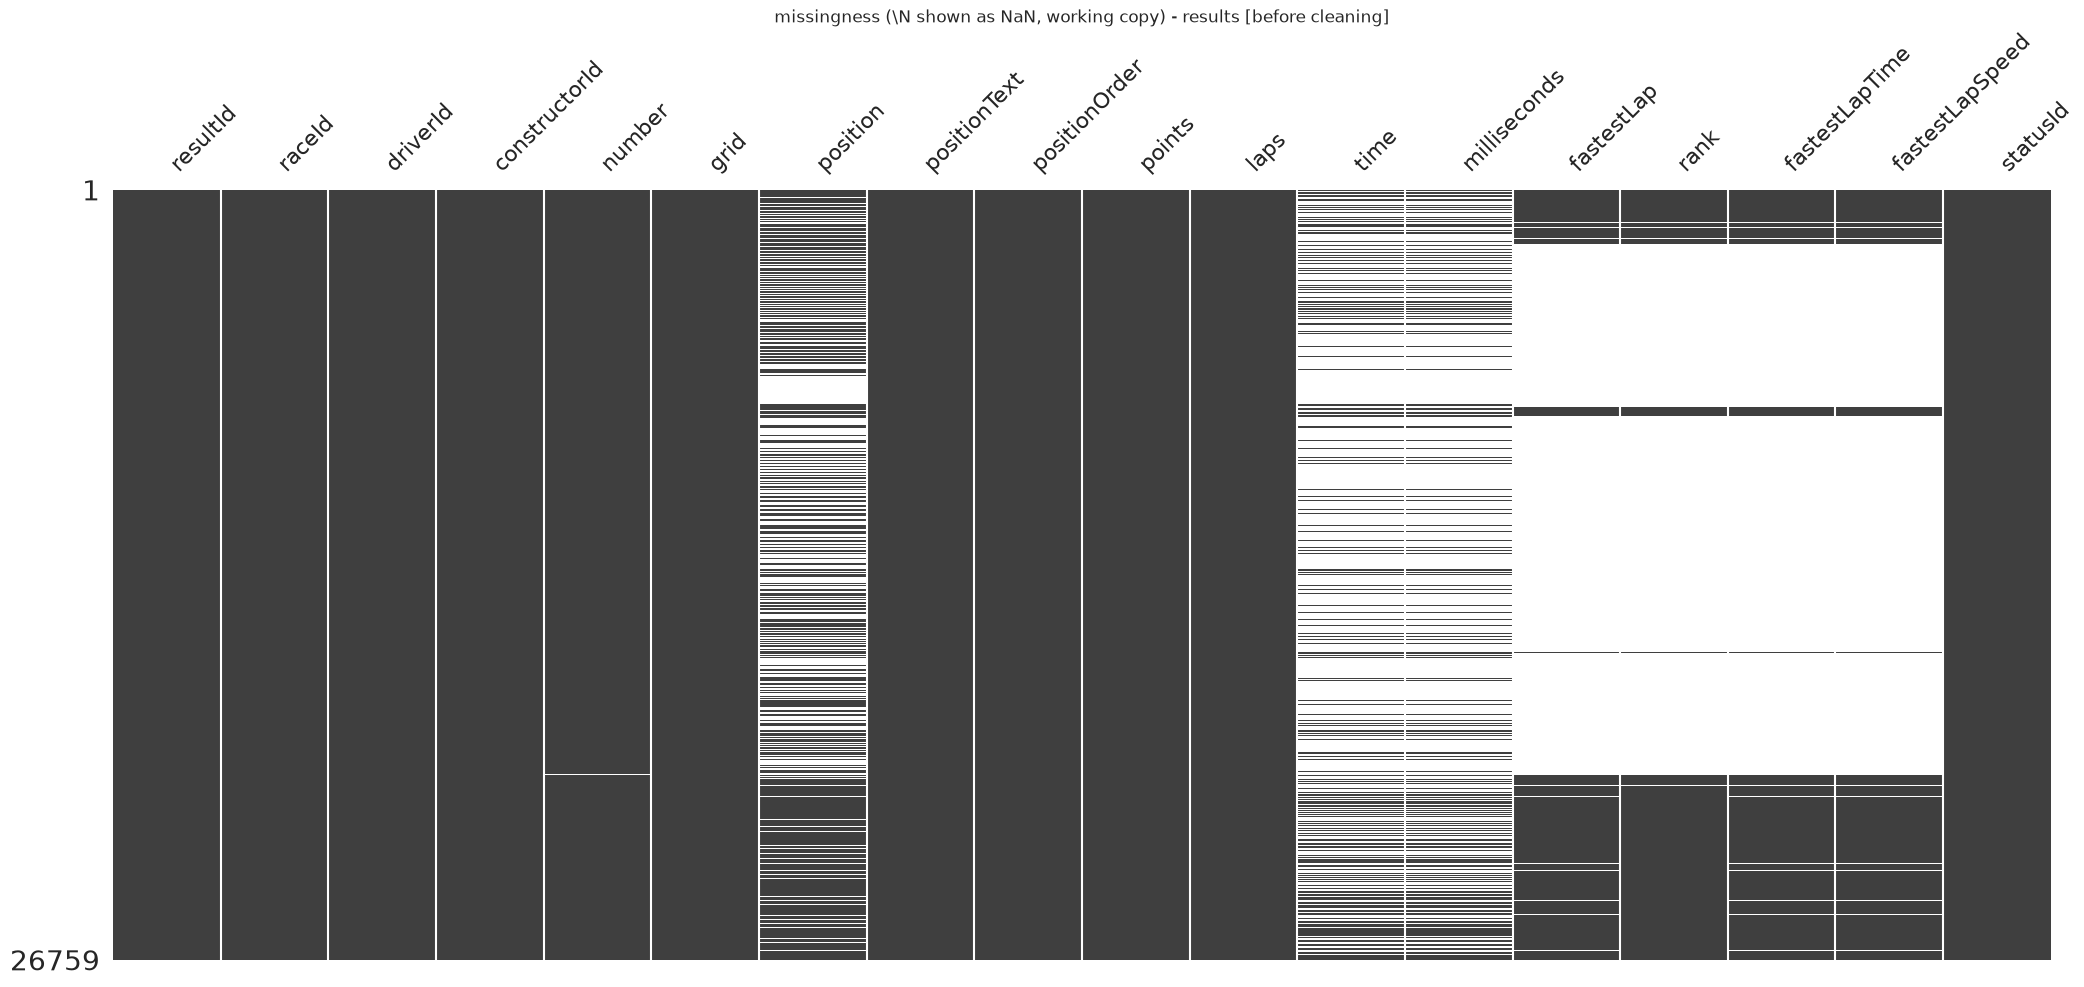

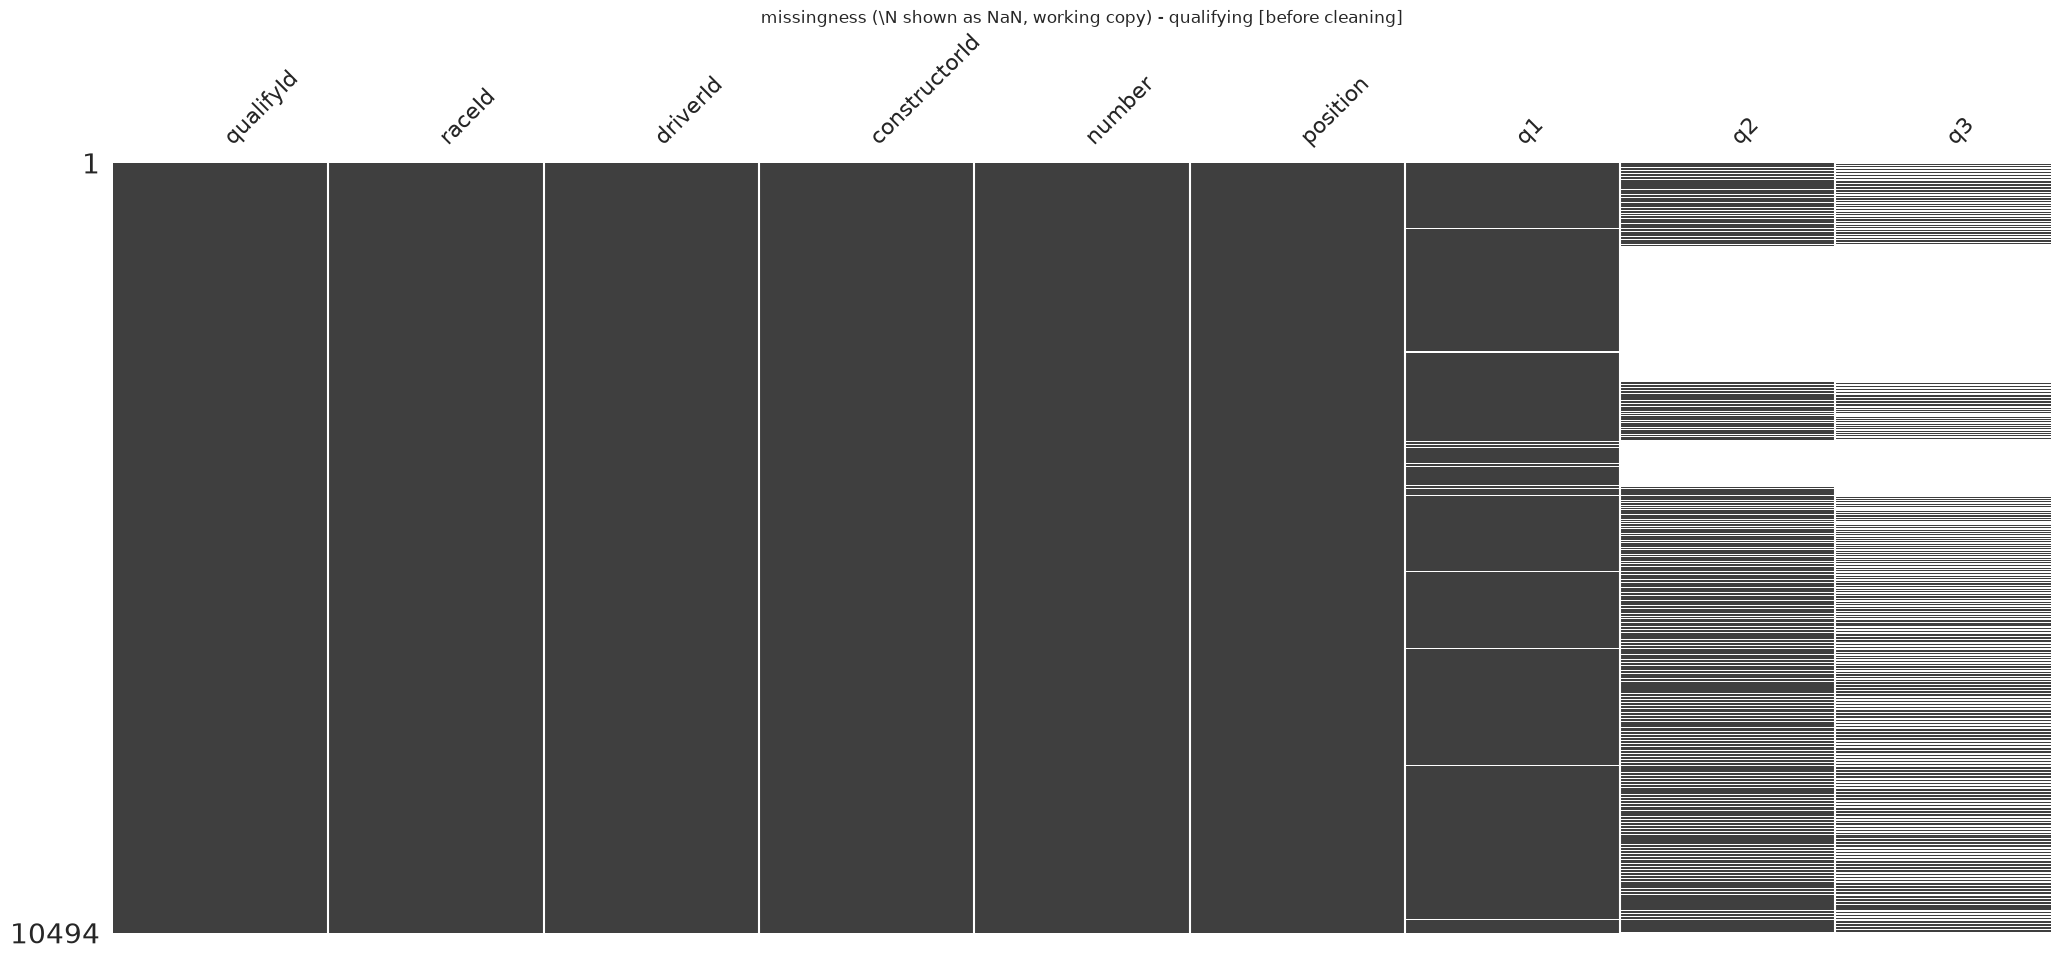

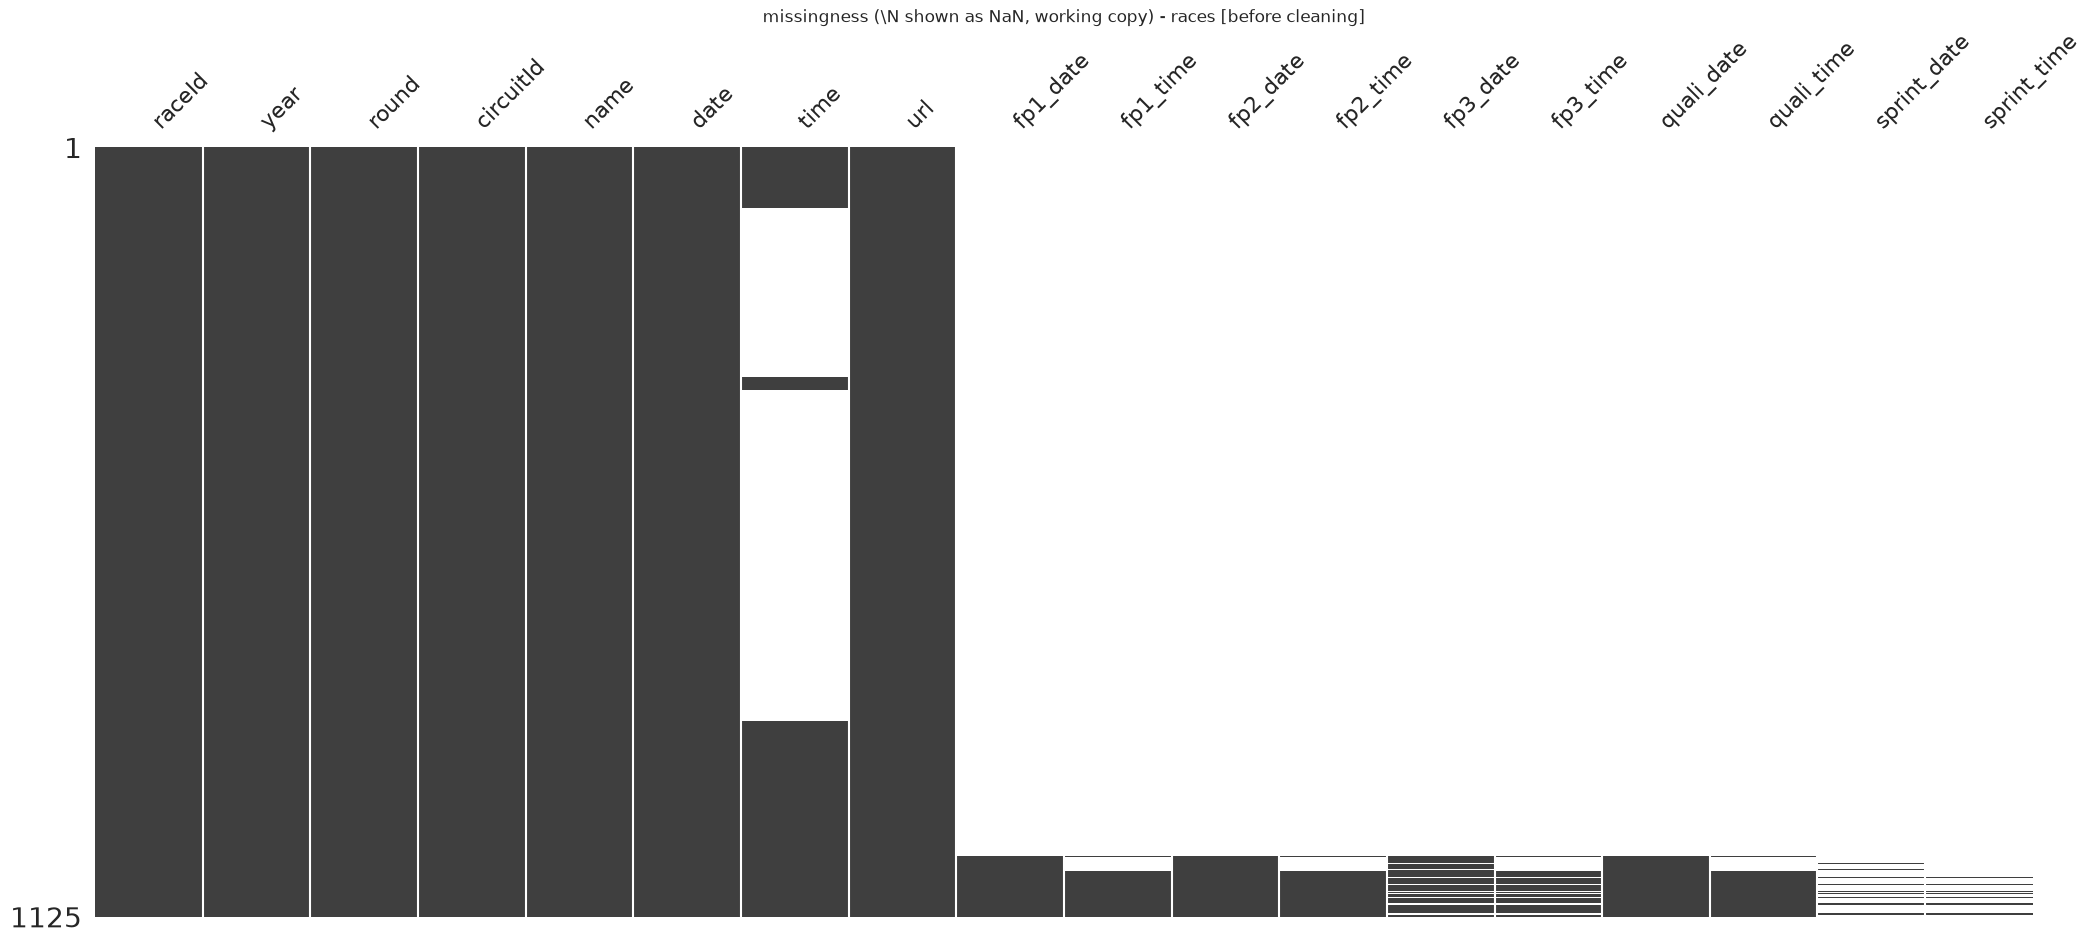

In [11]:
# Missing-value picture: on a temporary copy, turn \N into real NaN so missingno
# can draw it. White gaps = missing values. This is the 'before cleaning' view.
for t in ["results", "qualifying", "races"]:
    tmp = data[t].replace(r"\N", np.nan)
    msno.matrix(tmp, sparkline=False)
    plt.title(f"missingness (\\N shown as NaN, working copy) - {t} [before cleaning]")
    plt.savefig(FIG_DIR / f"fig_01_msno_{t}.png", dpi=150, bbox_inches="tight")
    plt.show()

### Gate 1.A: Is this the dataset version we expect?

Our plan assumes 14 tables covering the seasons 1950–2024. If the copy on Kaggle has been updated with newer seasons, we only keep `year <= 2024` so our numbers stay comparable.

In [12]:
# Which seasons does our copy of the dataset cover?
races_y = data["races"]["year"].astype(int)
print(f"seasons: {races_y.min()}-{races_y.max()} ({data['seasons'].shape[0]} rows in seasons.csv)")
print(f"races  : {len(data['races']):,}  | results rows: {len(data['results']):,}")
print(f"tables : {len(data)} (expected 14)")
yr_max = int(races_y.max())
# If the dataset has newer seasons than our plan, we will ignore them
if yr_max > 2024:
    print(f"NOTE: dataset extends to {yr_max} > 2024 -> analysis will pin to year <= 2024 (Gate 1.A rule).")
else:
    print("Gate 1.A: version matches the plan (1950-2024). Proceed.")
display(data["races"].assign(year=races_y).groupby("year").size().rename("races").tail(8).to_frame().T)

seasons: 1950-2024 (75 rows in seasons.csv)
races  : 1,125  | results rows: 26,759
tables : 14 (expected 14)
Gate 1.A: version matches the plan (1950-2024). Proceed.


year,2017,2018,2019,2020,2021,2022,2023,2024
races,20,21,21,17,22,22,22,24


### Gate 1.B: Other ways "missing" can be hidden

`\N` isn't the only way the data says "nothing here". It can also be an empty text `''`, the text `NA`, `-1`, or a `0` that really means "none". This cell looks for all of them. The important finds are:
- `grid = 0`: the driver didn't start from a normal grid slot (sorted out in Gate 2.D, §11).
- empty `q2` / `q3` qualifying times: the driver didn't take part in that part of qualifying.

The rules for each placeholder are written down in `docs/method-notes.md`.

In [13]:
# Look for other placeholders that mean "no value": empty text, "NA", "-1"
extra = []
for t, df in data.items():
    for c in df.columns:
        s = df[c].astype(str)
        n_empty = int((df[c] == "").sum())
        n_na = int(s.eq("NA").sum())
        n_neg1 = int(s.eq("-1").sum())
        if n_empty: extra.append((t, c, '""', n_empty))
        if n_na: extra.append((t, c, '"NA"', n_na))
        if n_neg1: extra.append((t, c, '"-1"', n_neg1))
extra_rep = pd.DataFrame(extra, columns=["table", "column", "sentinel", "n"]) if extra else pd.DataFrame(columns=["table","column","sentinel","n"])
print("non-\\N placeholders found:")
display(extra_rep.sort_values("n", ascending=False).head(20) if len(extra_rep) else extra_rep)

# Zeros that really mean 'nothing' (Gate 2.D). grid = 0 can mean a pit-lane start OR that
# the driver never started at all; we separate the two in §11.
r = data["results"]
print(f"results.grid == '0'      : {(r['grid'] == '0').sum():,} rows (pit-lane starts vs DNQ -> Gate 2.D)")
print(f"results.position == '0'  : {(r['position'] == '0').sum():,} rows")
print(f"results.number == ''     : {(r['number'] == '').sum():,} rows")
cir = data["circuits"]
print(f"circuits lat==0 & lng==0 : {((cir['lat'] == '0') & (cir['lng'] == '0')).sum()} rows")
q = data["qualifying"]
for c in ["q1", "q2", "q3"]:
    print(f"qualifying.{c} == ''   : {(q[c] == '').sum():,} rows")
print("Gate 1.B registry set (rules: docs/method-notes.md).")

non-\N placeholders found:


,table,column,sentinel,n
1,qualifying,q3,"""""",46
0,qualifying,q2,"""""",22


results.grid == '0'      : 1,638 rows (pit-lane starts vs DNQ -> Gate 2.D)
results.position == '0'  : 0 rows
results.number == ''     : 0 rows
circuits lat==0 & lng==0 : 0 rows
qualifying.q1 == ''   : 0 rows
qualifying.q2 == ''   : 22 rows
qualifying.q3 == ''   : 46 rows
Gate 1.B registry set (rules: docs/method-notes.md).


### Plots before cleaning

- A heatmap of how often key columns are missing, season by season. It shows that detailed timing data only exists for recent years.
- Races per season, and cars entered per race by decade.
- How starting positions and laps completed are distributed (useful for spotting odd values).

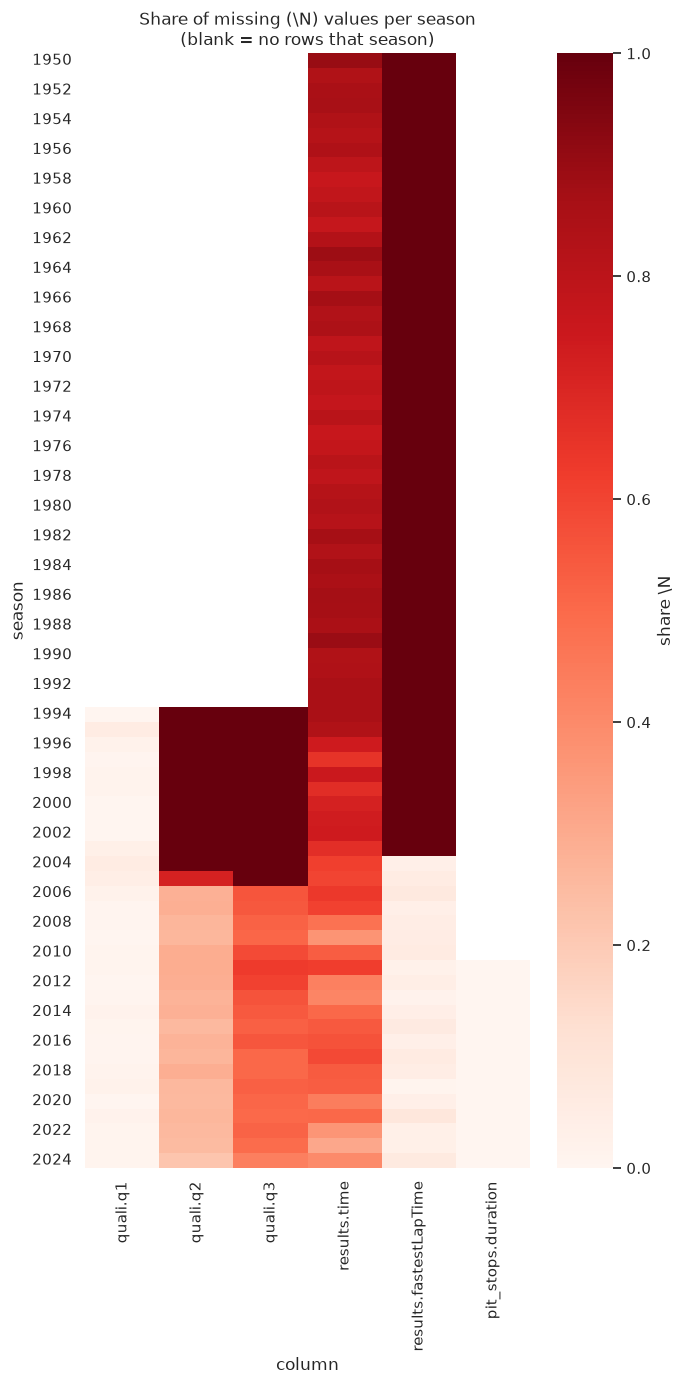

metric,quali.q1,quali.q2,quali.q3,results.time,results.fastestLapTime,pit_stops.duration
year,,,,,,
1994,0.003,1.000,1.000,0.858,1.000,NaN
2001,0.000,1.000,1.000,0.735,1.000,NaN
2003,0.034,1.000,1.000,0.669,1.000,NaN
2014,0.017,0.281,0.546,0.506,0.039,0.0
2024,0.008,0.217,0.434,0.399,0.067,0.0


In [14]:
# Share of missing (\N) values per season for a few key columns, drawn as a heatmap.
# Darker red = more missing. It shows how record-keeping improved over the years.
ry = data["races"][["raceId", "year"]].copy()
ry["year"] = ry["year"].astype(int)
q = data["qualifying"].merge(ry, on="raceId")
r = data["results"].merge(ry, on="raceId")
ps = data["pit_stops"].merge(ry, on="raceId")

# Build one long table: one row per value, with its season, column name and missing yes/no
parts = []
for col, label in [("q1", "quali.q1"), ("q2", "quali.q2"), ("q3", "quali.q3")]:
    parts.append(pd.DataFrame({"year": q["year"], "metric": label, "missing": q[col].eq(r"\N").astype(int)}))
for col, label in [("time", "results.time"), ("fastestLapTime", "results.fastestLapTime")]:
    parts.append(pd.DataFrame({"year": r["year"], "metric": label, "missing": r[col].eq(r"\N").astype(int)}))
parts.append(pd.DataFrame({"year": ps["year"], "metric": "pit_stops.duration",
                            "missing": ps["duration"].eq(r"\N").astype(int)}))
long = pd.concat(parts, ignore_index=True)
nrate = pd.pivot_table(long, index="year", columns="metric", values="missing", aggfunc="mean")
nrate = nrate[["quali.q1", "quali.q2", "quali.q3", "results.time", "results.fastestLapTime", "pit_stops.duration"]]

fig, ax = plt.subplots(figsize=(7, 14))
sns.heatmap(nrate, cmap="Reds", cbar_kws={"label": "share \\N"}, ax=ax)
ax.set_title("Share of missing (\\N) values per season\n(blank = no rows that season)")
ax.grid(False)
ax.set_xlabel("column")
ax.set_ylabel("season")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig_02_nrate_heatmap.png", dpi=150)
plt.show()
display(nrate.loc[[1994, 2001, 2003, 2014, 2024]].round(3))

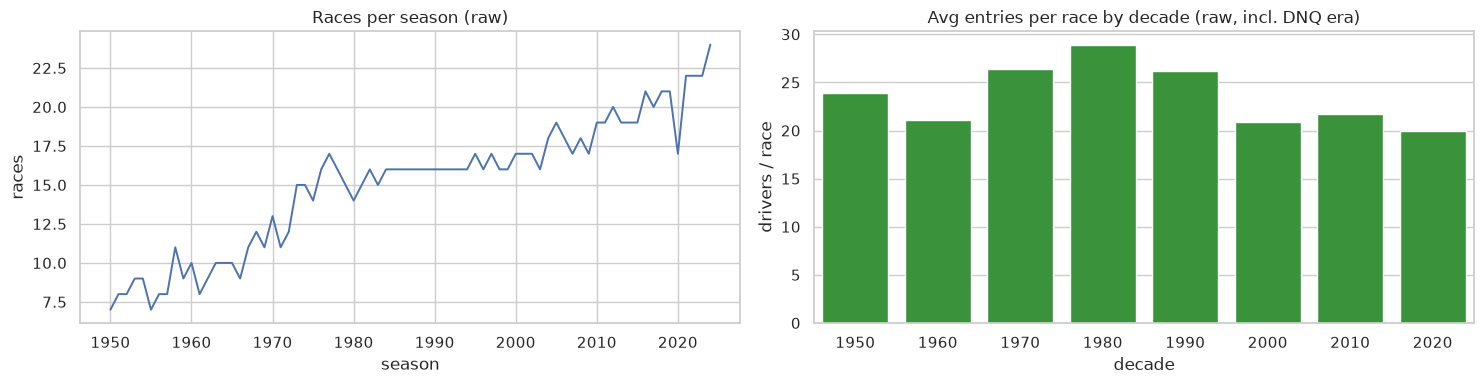

seasons 1950-2024, total races 1,125, avg entries/race 23.8


In [15]:
# Left: number of races per season. Right: average number of cars entered per race, per decade
# (older decades include drivers who failed to qualify, so the numbers are higher).
ry = data["races"][["raceId", "year"]].copy()
ry["year"] = ry["year"].astype(int)
n_races = ry.groupby("year").size()
entries = data["results"].merge(ry, on="raceId")
entries["decade"] = (entries["year"] // 10) * 10
dec_races = ry.groupby((ry["year"] // 10) * 10).size().rename("races")
dec_entries = entries.groupby("decade").size() / dec_races

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
axes[0].plot(n_races.index, n_races.values, lw=1.4)
axes[0].set_title("Races per season (raw)")
axes[0].set_xlabel("season")
axes[0].set_ylabel("races")
sns.barplot(x=dec_entries.index.astype(str), y=dec_entries.values, ax=axes[1], color="#2ca02c")
axes[1].set_title("Avg entries per race by decade (raw, incl. DNQ era)")
axes[1].set_xlabel("decade")
axes[1].set_ylabel("drivers / race")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig_03_seasons.png", dpi=150)
plt.show()
print(f"seasons {int(n_races.index.min())}-{int(n_races.index.max())}, "
      f"total races {len(ry):,}, avg entries/race {len(entries) / len(ry):.1f}")

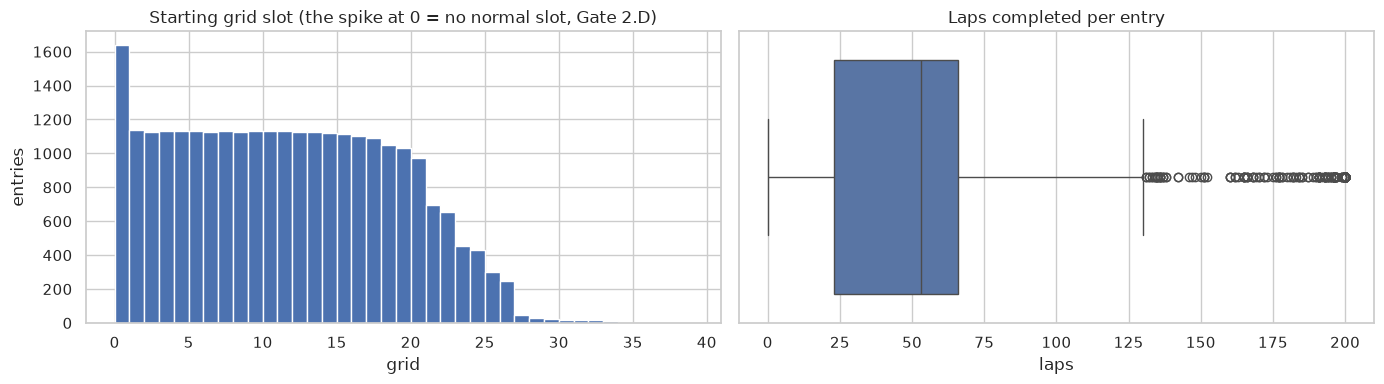

,grid,laps,points,positionOrder
count,26759.00,26759.0,26759.00,26759.00
mean,11.13,46.3,1.99,12.79
std,7.20,29.5,4.35,7.67
min,0.00,0.0,0.00,1.00
25%,5.00,23.0,0.00,6.00
50%,11.00,53.0,0.00,12.00
75%,17.00,66.0,2.00,18.00
max,34.00,200.0,50.00,39.00


In [16]:
# Distributions of a few number columns, to spot odd values. A copy is converted to numbers
# first (\N becomes NaN). Note the spike at grid = 0 on the left.
res_num = pd.DataFrame({
    "grid": pd.to_numeric(data["results"]["grid"].replace(r"\N", np.nan), errors="coerce"),
    "laps": pd.to_numeric(data["results"]["laps"].replace(r"\N", np.nan), errors="coerce"),
    "points": pd.to_numeric(data["results"]["points"].replace(r"\N", np.nan), errors="coerce"),
    "positionOrder": pd.to_numeric(data["results"]["positionOrder"].replace(r"\N", np.nan), errors="coerce"),
})
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(res_num["grid"].dropna(), bins=range(0, 40))
axes[0].set_title("Starting grid slot (the spike at 0 = no normal slot, Gate 2.D)")
axes[0].set_xlabel("grid")
axes[0].set_ylabel("entries")
sns.boxplot(x=res_num["laps"], ax=axes[1])
axes[1].set_title("Laps completed per entry")
axes[1].set_xlabel("laps")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig_04_numeric_dist.png", dpi=150)
plt.show()
display(res_num.describe().round(2))

**What these plots tell us**
- A missing finishing `position` means the driver **didn't finish** (retired, crashed, …). That's real information, not a gap, so we never fill it in with a guess.
- Missing `q2` / `q3` times mostly mean those qualifying sessions **didn't exist yet** in that era.
- The big spike at `grid = 0` is drivers who didn't start from a normal slot. We split those into "started from the pit lane" and "never started" in Gate 2.D (§11).

More detail: `docs/method-notes.md`.

## 5. Do the IDs line up? (primary and foreign key checks)

- A **primary key** is the column (or columns) that uniquely identifies a row, e.g. each `raceId` appears exactly once in `races`. For every table we check: no duplicates, no blanks, no `\N`.
- A **foreign key** is a column that points to another table, e.g. `results.driverId` → `drivers.driverId`. We check there are no **orphans**, i.e. IDs that point to something that doesn't exist.

If any check fails, the cell stops with an error so we never carry on with broken data.

In [17]:
# The column(s) that should uniquely identify a row in each table
PRIMARY_KEYS = {
    "circuits": ["circuitId"], "constructors": ["constructorId"],
    "constructor_results": ["constructorResultsId"],
    "constructor_standings": ["constructorStandingsId"],
    "drivers": ["driverId"], "driver_standings": ["driverStandingsId"],
    "races": ["raceId"], "results": ["resultId"], "qualifying": ["qualifyId"],
    "lap_times": ["raceId", "driverId", "lap"],
    "pit_stops": ["raceId", "driverId", "stop"],
    "seasons": ["year"], "sprint_results": ["resultId"], "status": ["statusId"],
}

# For each table: is the key unique? Any blanks? Any \N?
pk_report = []
for t, cols in PRIMARY_KEYS.items():
    df = data[t]
    pk_report.append({
        "table": t,
        "pk": " + ".join(cols),
        "rows": len(df),
        "unique": df.drop_duplicates(cols).shape[0] == len(df),
        "nulls": int(df[cols].isna().sum().sum()),
        "sentinels": int(df[cols].astype(str).eq(r"\N").sum().sum()),
    })
pk_report = pd.DataFrame(pk_report)
display(pk_report)

# Stop the notebook if any check fails
assert pk_report["unique"].all(),  "duplicate primary keys found"
assert pk_report["nulls"].eq(0).all(),   "null primary keys found"
assert pk_report["sentinels"].eq(0).all(), "sentinel in primary key found"
print("all 14 primary keys unique, non-null and sentinel-free")

,table,pk,rows,unique,nulls,sentinels
0,circuits,circuitId,77,True,0,0
1,constructors,constructorId,212,True,0,0
2,constructor_results,constructorResultsId,12625,True,0,0
3,constructor_standings,constructorStandingsId,13391,True,0,0
4,drivers,driverId,861,True,0,0
5,driver_standings,driverStandingsId,34863,True,0,0
6,races,raceId,1125,True,0,0
7,results,resultId,26759,True,0,0
8,qualifying,qualifyId,10494,True,0,0
9,lap_times,raceId + driverId + lap,589081,True,0,0


all 14 primary keys unique, non-null and sentinel-free


In [18]:
# Each entry: (column in this table, table it points to, column in that table)
FOREIGN_KEYS = {
    "constructor_results": [("raceId", "races", "raceId"), ("constructorId", "constructors", "constructorId")],
    "constructor_standings": [("raceId", "races", "raceId"), ("constructorId", "constructors", "constructorId")],
    "driver_standings": [("raceId", "races", "raceId"), ("driverId", "drivers", "driverId")],
    "races": [("circuitId", "circuits", "circuitId")],
    "results": [("raceId", "races", "raceId"), ("driverId", "drivers", "driverId"),
                ("constructorId", "constructors", "constructorId"), ("statusId", "status", "statusId")],
    "qualifying": [("raceId", "races", "raceId"), ("driverId", "drivers", "driverId"),
                   ("constructorId", "constructors", "constructorId")],
    "lap_times": [("raceId", "races", "raceId"), ("driverId", "drivers", "driverId")],
    "pit_stops": [("raceId", "races", "raceId"), ("driverId", "drivers", "driverId")],
    "sprint_results": [("raceId", "races", "raceId"), ("driverId", "drivers", "driverId"),
                       ("constructorId", "constructors", "constructorId"), ("statusId", "status", "statusId")],
}

# Count 'orphans': IDs that point to a row that doesn't exist
fk_report = []
for t, fks in FOREIGN_KEYS.items():
    for col, ref_t, ref_c in fks:
        orphans = int((~data[t][col].isin(data[ref_t][ref_c])).sum())
        fk_report.append({"table": t, "fk": col, "references": f"{ref_t}.{ref_c}",
                          "rows": len(data[t]), "orphans": orphans})
fk_report = pd.DataFrame(fk_report)
display(fk_report)

assert fk_report["orphans"].eq(0).all(), "foreign key violations found"
print(f"all {len(fk_report)} foreign keys reconcile - 0 orphans")

,table,fk,references,rows,orphans
0,constructor_results,raceId,races.raceId,12625,0
1,constructor_results,constructorId,constructors.constructorId,12625,0
2,constructor_standings,raceId,races.raceId,13391,0
3,constructor_standings,constructorId,constructors.constructorId,13391,0
4,driver_standings,raceId,races.raceId,34863,0
5,driver_standings,driverId,drivers.driverId,34863,0
6,races,circuitId,circuits.circuitId,1125,0
7,results,raceId,races.raceId,26759,0
8,results,driverId,drivers.driverId,26759,0
9,results,constructorId,constructors.constructorId,26759,0


all 22 foreign keys reconcile - 0 orphans


## 6. One row per driver per race

The model makes one prediction per driver per race, so `results` needs exactly one row for each (race, driver) pair. It doesn't quite have that: in the 1950s–70s drivers sometimes **shared a car or switched cars** during a race, which gives them two rows in the same race. This cell counts those duplicates and shows some examples. How we resolve them is decision D3 in `docs/decisions.md`.

In [19]:
# Find (race, driver) pairs that appear more than once in results
res = data["results"]
KEY = ["raceId", "driverId"]

dup_mask = res.duplicated(KEY, keep=False)
dups = res[dup_mask].sort_values(KEY)
n_pairs = dups.groupby(KEY).ngroups
n_unique = res.drop_duplicates(KEY).shape[0]

print(f"results rows              : {len(res):,}")
print(f"unique (raceId, driverId) : {n_unique:,}")
print(f"duplicated pairs           : {n_pairs}   (rows involved: {int(dup_mask.sum())})")
print(f"rows to remove for grain   : {len(res) - n_unique}")

# Do the two rows of a pair give different finishing positions? (If so, the choice of rule matters.)
disagree = dups.groupby(KEY)["positionOrder"].nunique().gt(1).sum()
print(f"pairs with conflicting positionOrder: {disagree} of {n_pairs}")

# Add race and driver names so the examples are readable
ctx = (dups.merge(data["races"][["raceId", "year", "name"]], on="raceId")
           .merge(data["drivers"][["driverId", "forename", "surname"]], on="driverId"))
show = ["year", "name", "forename", "surname", "grid", "laps", "position", "positionOrder", "points"]
display(ctx[show].head(12))

print("\nduplicated pairs per season:")
display(ctx.drop_duplicates(KEY).groupby("year").size().rename("pairs").to_frame().T)

results rows              : 26,759
unique (raceId, driverId) : 26,668
duplicated pairs           : 85   (rows involved: 176)
rows to remove for grain   : 91
pairs with conflicting positionOrder: 85 of 85


,year,name,forename,surname,grid,laps,position,positionOrder,points
0,1978,Italian Grand Prix,Harald,Ertl,0,0,\N,26,0
1,1978,Italian Grand Prix,Harald,Ertl,0,0,\N,29,0
2,1964,United States Grand Prix,Jim,Clark,1,102,7,7,0
3,1964,United States Grand Prix,Jim,Clark,1,54,\N,12,0
4,1962,British Grand Prix,Keith,Greene,0,0,\N,22,0
5,1962,British Grand Prix,Keith,Greene,0,0,\N,25,0
6,1961,British Grand Prix,Stirling,Moss,20,56,\N,19,0
7,1961,British Grand Prix,Stirling,Moss,5,44,\N,21,0
8,1961,United States Grand Prix,Masten,Gregory,11,23,\N,17,0
9,1961,United States Grand Prix,Masten,Gregory,15,92,11,11,0



duplicated pairs per season:


year,1950,1951,1952,1953,1954,1955,1956,1957,1958,1960,1961,1962,1964,1978
pairs,4,4,3,14,16,15,12,8,3,1,2,1,1,1


**How we pick one row out of a duplicate pair**

We compared two rules:
- **R1** (the code below, for comparison only): keep the row with the best finishing position.
- **R2** (the rule we actually use, applied in §11): keep the car the driver **started** the race in (the lowest non-zero grid slot; if that's a tie, the first row). This fits our "before the race" view: at the start you know which car someone is in, but not how the race ends for them.

Only races before 1979 are affected, so the difference between the two is tiny. Reasoning: `docs/decisions.md`.

In [20]:
DEDUPE_RULE = "best_positionOrder_then_laps"


def dedupe_results(df: pd.DataFrame) -> pd.DataFrame:
    '''Rule R1: keep the row with the best finishing position (then the most laps).
    Only used here for comparison; the rule we actually apply is R2, in §11.'''
    tmp = df.copy()
    tmp["_pos"] = pd.to_numeric(tmp["positionOrder"].replace(r"\N", np.nan), errors="coerce")
    tmp["_laps"] = pd.to_numeric(tmp["laps"].replace(r"\N", np.nan), errors="coerce")
    ordered = tmp.sort_values(["_pos", "_laps"], ascending=[True, False], na_position="last").drop(columns=["_pos", "_laps"])
    out = ordered.drop_duplicates(KEY, keep="first")
    return out.sort_index()


modeling_grain = dedupe_results(res)
dropped = len(res) - len(modeling_grain)
assert not modeling_grain.duplicated(KEY).any()
assert len(modeling_grain) == n_unique
print(f"rule '{DEDUPE_RULE}': dropped {dropped} rows, grain now unique "
      f"({len(modeling_grain):,} rows)")

# For each duplicated pair, show which row R1 kept
kept_for_dupes = modeling_grain.index.isin(dups.index)
kept_ctx = (modeling_grain.loc[kept_for_dupes]
            .merge(data["races"][["raceId", "year", "name"]], on="raceId")
            .merge(data["drivers"][["driverId", "forename", "surname"]], on="driverId"))
display(kept_ctx.sort_values(["year", "raceId", "positionOrder"])[show].head(8))

rule 'best_positionOrder_then_laps': dropped 91 rows, grain now unique (26,668 rows)


,year,name,forename,surname,grid,laps,position,positionOrder,points
17,1950,Indianapolis 500,Tony,Bettenhausen,9,136,5,5,1
18,1950,French Grand Prix,Louis,Rosier,15,56,6,6,0
20,1950,Italian Grand Prix,Juan,Fangio,7,34,\N,13,0
19,1950,Italian Grand Prix,Alberto,Ascari,6,80,2,2,3
15,1951,French Grand Prix,Luigi,Fagioli,7,77,1,1,4
21,1951,French Grand Prix,Juan,Fangio,7,77,1,1,5
16,1951,French Grand Prix,Alberto,Ascari,6,77,2,2,3
22,1951,Italian Grand Prix,Nino,Farina,7,79,3,3,3


## 7. What format are the dates and times in?

Every column is still text. Here we look at some example values to see how dates, lap times and durations are written (e.g. `1:27.274` = 1 minute 27.274 seconds). Then we write a helper, `time_to_seconds`, that turns all these formats into a plain number of seconds. It's used during cleaning in §11.

In [21]:
# Helper: the first n real (non-\N) values of a column
def sample_values(table, column, n=3):
    s = data[table][column]
    vals = [v for v in pd.unique(s)
            if not (isinstance(v, str) and v == r"\N") and pd.notna(v)]
    return list(vals[:n])


# How is each date/time column written?
format_samples = pd.DataFrame([
    ("races.date", "calendar date", sample_values("races", "date")),
    ("races.time", "clock time (UTC)", sample_values("races", "time")),
    ("races.quali_date", "calendar date", sample_values("races", "quali_date")),
    ("drivers.dob", "calendar date", sample_values("drivers", "dob")),
    ("qualifying.q1", "lap time m:s.ms", sample_values("qualifying", "q1")),
    ("lap_times.time", "lap time m:s.ms", sample_values("lap_times", "time")),
    ("results.time", "race time h:m:s.ms", sample_values("results", "time")),
    ("results.fastestLapTime", "lap time m:s.ms", sample_values("results", "fastestLapTime")),
    ("pit_stops.duration", "duration seconds", sample_values("pit_stops", "duration")),
    ("pit_stops.time", "clock time (UTC)", sample_values("pit_stops", "time")),
], columns=["column", "semantic type", "raw examples"])
display(format_samples)

,column,semantic type,raw examples
0,races.date,calendar date,"[2009-03-29, 2009-04-05, 2009-04-19]"
1,races.time,clock time (UTC),"[06:00:00, 09:00:00, 07:00:00]"
2,races.quali_date,calendar date,"[2021-04-17, 2022-03-19, 2021-03-27]"
3,drivers.dob,calendar date,"[1985-01-07, 1977-05-10, 1985-06-27]"
4,qualifying.q1,lap time m:s.ms,"[1:26.572, 1:26.103, 1:25.664]"
5,lap_times.time,lap time m:s.ms,"[1:38.109, 1:33.006, 1:32.713]"
6,results.time,race time h:m:s.ms,"[1:34:50.616, +5.478, +8.163]"
7,results.fastestLapTime,lap time m:s.ms,"[1:27.452, 1:27.739, 1:28.090]"
8,pit_stops.duration,duration seconds,"[26.898, 25.021, 23.426]"
9,pit_stops.time,clock time (UTC),"[17:05:23, 17:05:52, 17:20:48]"


In [22]:
def time_to_seconds(v):
    '''Turn a time written as text into a number of seconds.
    Handles '22.450', '1:27.274' (m:ss), '34:50.711' and '1:34:50.711' (h:mm:ss).
    Missing values (\\N, empty, NaN) become NaN.'''
    if v is None or pd.isna(v):
        return np.nan
    if isinstance(v, str):
        v = v.strip()
        if v in (r"\N", ""):
            return np.nan
    try:
        # each part before a ':' is worth 60x the next one, e.g. '1:27.274' -> 1*60 + 27.274
        secs = 0.0
        for part in str(v).split(":"):
            secs = secs * 60 + float(part)
        return secs
    except ValueError:
        return np.nan


# Try it on a few lap times
demo = data["lap_times"].head(5)[["raceId", "driverId", "lap", "time"]].copy()
demo["seconds"] = demo["time"].map(time_to_seconds)
display(demo)

# Check that every real value can be parsed (0 failures expected)
lt_ok = data["lap_times"]["time"].map(time_to_seconds)
rt = data["results"]["time"]
rt_non_sentinel = ~rt.isin([r"\N"])
print(f"lap_times.time  : {int(lt_ok.isna().sum())} parse failures / {len(lt_ok):,} rows")
print(f"results.time    : {int(rt[rt_non_sentinel].map(time_to_seconds).isna().sum())} parse failures "
      f"/ {int(rt_non_sentinel.sum()):,} non-sentinel rows")

parsed_dates = pd.to_datetime(data["races"]["date"], errors="coerce")
print(f"races.date      : {int(parsed_dates.isna().sum())} parse failures / {len(parsed_dates)} rows")
display(pd.DataFrame({"raw": data["races"]["date"].head(3),
                      "typed": parsed_dates.head(3).dt.date.values}))

,raceId,driverId,lap,time,seconds
0,841,20,1,1:38.109,98.109
1,841,20,2,1:33.006,93.006
2,841,20,3,1:32.713,92.713
3,841,20,4,1:32.803,92.803
4,841,20,5,1:32.342,92.342


lap_times.time  : 0 parse failures / 589,081 rows
results.time    : 0 parse failures / 7,680 non-sentinel rows
races.date      : 0 parse failures / 1125 rows


,raw,typed
0,2009-03-29,2009-03-29
1,2009-04-05,2009-04-05
2,2009-04-19,2009-04-19


## 8. Which data exists in which era?

F1 record-keeping changed a lot over 75 years. These charts show, season by season, what share of entries is missing qualifying times (Q1 / Q2 / Q3) and some results fields. The main takeaway: **detailed qualifying data is missing for most older seasons**. That's why our first plan used only 2003 onwards, and why the final model (§14) doesn't use qualifying times at all.

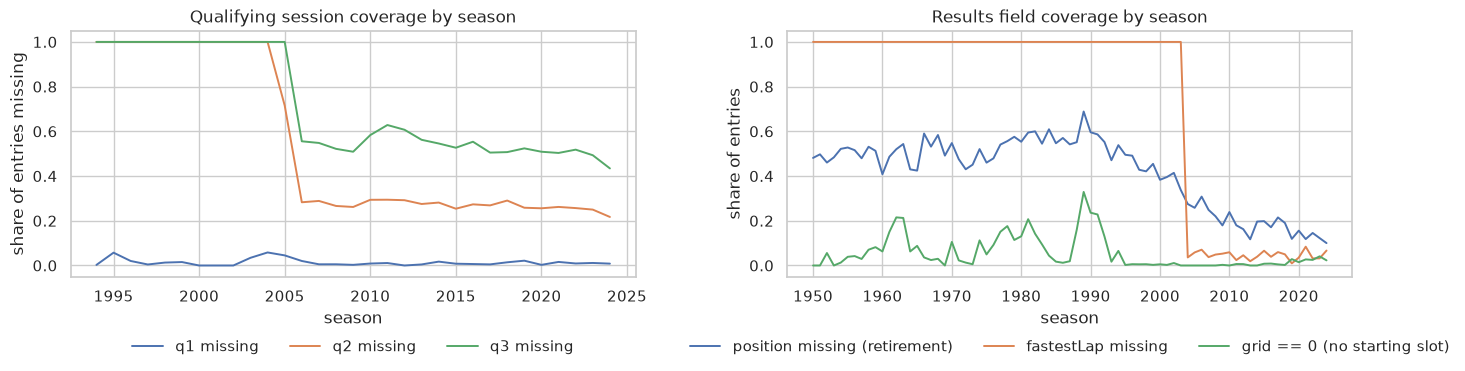

,q1 missing,q2 missing,q3 missing
era,,,
pre-2003,0.021,1.000,1.000
2003-2013,0.017,0.433,0.673
2014+,0.011,0.260,0.510


In [23]:
# Share of entries missing each qualifying session time, per season
q = data["qualifying"].merge(data["races"][["raceId", "year"]], on="raceId")
q_cov = pd.DataFrame({
    "q1 missing": q["q1"].eq(r"\N"),
    "q2 missing": q["q2"].eq(r"\N"),
    "q3 missing": q["q3"].eq(r"\N"),
})
q_cov["year"] = q["year"].astype(int).values
by_year = q_cov.groupby("year").mean()

# Same idea for some results fields
r = data["results"].merge(data["races"][["raceId", "year"]], on="raceId")
r_cov = pd.DataFrame({
    "position missing (retirement)": r["position"].eq(r"\N"),
    "fastestLap missing": r["fastestLap"].eq(r"\N"),
    "grid == 0 (no starting slot)": r["grid"].eq("0"),
})
r_cov["year"] = r["year"].astype(int).values
r_by_year = r_cov.groupby("year").mean()

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
by_year.plot(ax=axes[0], lw=1.4)
axes[0].set_title("Qualifying session coverage by season")
axes[0].set_ylabel("share of entries missing")
axes[0].set_xlabel("season")
axes[0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=3, frameon=False)

r_by_year.plot(ax=axes[1], lw=1.4)
axes[1].set_title("Results field coverage by season")
axes[1].set_ylabel("share of entries")
axes[1].set_xlabel("season")
axes[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=3, frameon=False)
plt.tight_layout()
plt.show()

# Summary table: share missing per era
q_cov["era"] = pd.cut(q["year"].astype(int), [1949, 2002, 2013, 2025],
                      labels=["pre-2003", "2003-2013", "2014+"])
display(q_cov.groupby("era", observed=True)[["q1 missing", "q2 missing", "q3 missing"]]
        .mean().round(3))

These findings decide which seasons we can use and how we treat `grid = 0` (Gate 2.D). Details: `docs/method-notes.md`.

## 9. What we're predicting (the target)

`podium = 1` if the driver finished in the top 3 (`positionOrder <= 3`), otherwise `0`.

The charts show what share of driver-races ends on the podium, per decade and per season. The share changes over time mostly because the number of cars per race changed: with 30+ cars in a race, any one driver is less likely to be top 3 than with 20.

rows (unique driver-races): 26,668
podium finishes            : 3,395  (12.7%)
non-podium                 : 23,273  (87.3%)


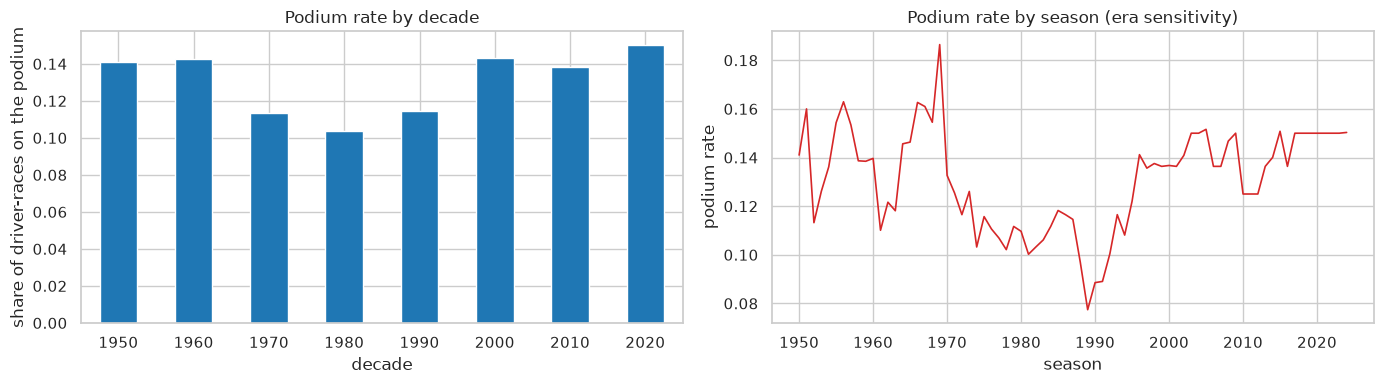

In [24]:
# The target: 1 if the driver finished 1st-3rd, else 0 (quick look, using the R1 rows)
tgt = dedupe_results(res).merge(data["races"][["raceId", "year"]], on="raceId")
tgt["pos_num"] = pd.to_numeric(tgt["positionOrder"].replace(r"\N", np.nan), errors="coerce")
tgt["podium"] = (tgt["pos_num"] <= 3).astype(int)

print(f"rows (unique driver-races): {len(tgt):,}")
print(f"podium finishes            : {tgt['podium'].sum():,}  ({tgt['podium'].mean():.1%})")
print(f"non-podium                 : {(1 - tgt['podium']).sum():,}  ({1 - tgt['podium'].mean():.1%})")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

by_decade = tgt.assign(year_n=tgt["year"].astype(int), decade=(tgt["year"].astype(int) // 10) * 10).groupby("decade")["podium"].mean()
by_decade.plot(kind="bar", ax=axes[0], color="#1f77b4")
axes[0].set_title("Podium rate by decade")
axes[0].set_ylabel("share of driver-races on the podium")
axes[0].set_xlabel("decade")
axes[0].tick_params(axis="x", rotation=0)

tgt.assign(year_n=tgt["year"].astype(int)).groupby("year_n")["podium"].mean().plot(ax=axes[1], lw=1.2, color="#d62728")
axes[1].set_title("Podium rate by season (era sensitivity)")
axes[1].set_ylabel("podium rate")
axes[1].set_xlabel("season")
plt.tight_layout()
plt.show()

**Why this matters for the rest of the project**
- Only about **1 in 8** entries is a podium (12.7%). With so few positives, **accuracy is misleading**: a model that always says "no podium" would be ~87% accurate and completely useless.
- So our main score is **PR-AUC** (area under the precision–recall curve). It measures how well the model ranks the real podium finishers above everyone else, and it focuses on the rare "podium" class.
- Because the podium rate changes over the years, we split the data into train / validation / test **by season** (learn from older years, test on the newest), never randomly.

Details: `docs/method-notes.md`.

## 10. The cutoff: what is the model allowed to know?

We imagine making each prediction **after qualifying, just before the race starts**. Every column that describes the race itself (finishing position, points, laps, time, fastest lap, reason for retiring) is only known afterwards, so using it as an input would be leakage.

The table below labels every column of `results` as allowed or forbidden. The check at the bottom fails if the labels and the forbidden list ever disagree.

> The full written leakage rules are in `docs/leakage.md`.

In [25]:
# The results columns we ARE allowed to use (known before the race), and what they are
RESULTS_ROLES = {
    "resultId": "identifier", "raceId": "identifier", "driverId": "identifier",
    "constructorId": "pre-race", "number": "pre-race (car number)",
    "grid": "pre-race (set after qualifying + penalties)",
    "podium": "TARGET (derived from positionOrder <= 3)",
}
# Columns only known after the race: must never be model inputs (leakage)
FORBIDDEN = [
    "position", "positionText", "positionOrder", "points", "laps", "time", "milliseconds",
    "fastestLap", "rank", "fastestLapTime", "fastestLapSpeed", "statusId",
]

# Label every column, then check the labels agree with the FORBIDDEN list
audit = pd.DataFrame({"column": list(data["results"].columns) + ["podium"]})
audit["role_at_cutoff"] = audit["column"].map(RESULTS_ROLES).fillna("LEAKAGE - post-race")
display(audit)

assert set(FORBIDDEN) <= set(audit["column"]), "unexpected column name in FORBIDDEN"
assert (audit["role_at_cutoff"].str.startswith("LEAKAGE") ==
        audit["column"].isin(FORBIDDEN)).all(), "leakage audit inconsistent"
print(f"{int(audit['role_at_cutoff'].str.startswith('LEAKAGE').sum())} post-race columns "
      f"excluded from the feature set; target = podium")

,column,role_at_cutoff
0,resultId,identifier
1,raceId,identifier
2,driverId,identifier
3,constructorId,pre-race
4,number,pre-race (car number)
5,grid,pre-race (set after qualifying + penalties)
6,position,LEAKAGE - post-race
7,positionText,LEAKAGE - post-race
8,positionOrder,LEAKAGE - post-race
9,points,LEAKAGE - post-race


12 post-race columns excluded from the feature set; target = podium


## 11. Cleaning the data (on copies)

The original files are never changed; we clean a copy called `clean`. One cell per step:
1. Turn `\N` into real empty values (NaN) and trim stray spaces.
2. Convert text into proper types: dates → dates, lap times → seconds, numbers → numbers.
3. Give every category exactly one spelling (e.g. "United States" vs "USA", "Argentinian" vs "Argentine"), and give each driver a home country in the same spelling the circuits use.
4. Drop columns nobody needs (web links, practice session times).
5. Re-run the ID checks from §5 on the cleaned data.
6. Apply rule R2 so there's one row per driver per race.
7. Add yes/no flags: drivers who never started, pit-lane starts, the Indy 500.
8. Group the reasons a race ended into a few classes.
9. Before/after comparison plots, and a summary of what changed.

We **don't fill in missing values here**. That happens in §15, using values learned from the training data only, so the test data can't influence it.

In [26]:
# Step 1: copy every table and turn the \N placeholders into real empty values (NaN).
# In qualifying, empty q2/q3 text also means 'no time', so it becomes NaN too.
clean = {t: df.copy() for t, df in data.items()}
n_sentinel = 0
for t, df in clean.items():
    n = int((df == r"\N").sum().sum())
    n_sentinel += n
    clean[t] = df.replace(r"\N", np.nan)
n_empty = int((clean["qualifying"][["q2", "q3"]] == "").sum().sum())  # found in Gate 1.B
clean["qualifying"][["q2", "q3"]] = clean["qualifying"][["q2", "q3"]].replace("", np.nan)
for t, df in clean.items():  # trim stray spaces, e.g. 'Argentinian ' -> 'Argentinian' (matters for Q2)
    for c in df.columns:  # (newer pandas stores text as a 'string' type, so we check for that)
        if pd.api.types.is_string_dtype(df[c]):
            df[c] = df[c].str.strip()
print(f"\\N -> NaN : {n_sentinel:,} cells | '' -> NaN (quali q2/q3): {n_empty} cells")
# Make sure no \N is left anywhere
leftover = sum(int((clean[t] == r"\N").sum().sum()) for t in clean)
assert leftover == 0, "sentinel leftovers found"
print("assert: no literal \\N remains in any cleaned copy")

\N -> NaN : 160,076 cells | '' -> NaN (quali q2/q3): 68 cells
assert: no literal \N remains in any cleaned copy


In [27]:
# Step 2a: turn date text into real dates, and combine race date + start time where both exist
for c in ["date", "fp1_date", "fp2_date", "fp3_date", "quali_date", "sprint_date"]:
    clean["races"][c] = pd.to_datetime(clean["races"][c], errors="coerce")
clean["drivers"]["dob"] = pd.to_datetime(clean["drivers"]["dob"], errors="coerce")
has_both = clean["races"]["date"].notna() & clean["races"]["time"].notna() & (clean["races"]["time"] != "")
clean["races"]["race_datetime"] = pd.to_datetime(
    clean["races"]["date"].astype(str) + " " + clean["races"]["time"].astype(str), errors="coerce")
print(clean["races"][["date", "time", "race_datetime"]].dtypes.to_string())
print(f"race_datetime parsed: {int(clean['races']['race_datetime'].notna().sum())} / {len(clean['races'])} races")

date             datetime64[us]
time                        str
race_datetime    datetime64[us]
race_datetime parsed: 394 / 1125 races


quali q1_s: n=10,338, median=87.14s, >200s: 1, <50s: 0
pit duration_s: n=11,371, median=23.61s, >600s (red flags): 460


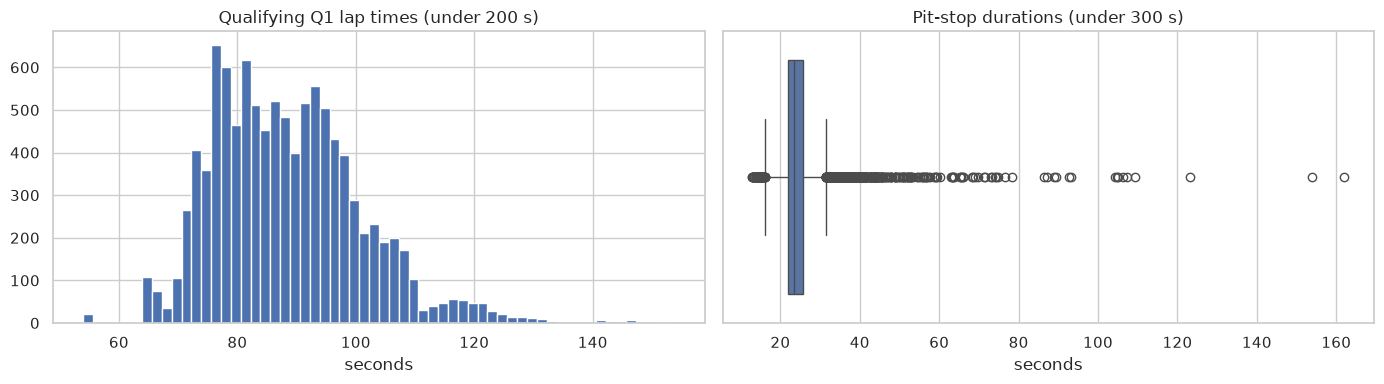

results winners: 1,128 rows, max |parse - ms/1000| = 0.0000s
lap_times: 589,081 rows with both, max |parse - ms/1000| = 0.0000s
Gate 2.A: parsing plausible (outliers flagged, none deleted); unit check passed


In [28]:
# Step 2b: turn lap times, race times and pit-stop durations into seconds.
# The original text columns are kept; the numbers go into new columns ending in _s.
for c in ["q1", "q2", "q3"]:
    clean["qualifying"][c + "_s"] = clean["qualifying"][c].map(time_to_seconds)
clean["results"]["raceTime_s"] = clean["results"]["time"].map(time_to_seconds)
clean["results"]["fastestLapTime_s"] = clean["results"]["fastestLapTime"].map(time_to_seconds)
clean["lap_times"]["time_s"] = clean["lap_times"]["time"].map(time_to_seconds)
clean["pit_stops"]["duration_s"] = clean["pit_stops"]["duration"].map(time_to_seconds)

# Gate 2.A: do the numbers look realistic? A qualifying lap is usually 50-150 s and a pit stop
# 15-60 s. Much longer values exist (e.g. a red flag during the stop); we count them, we don't delete them.
q1 = clean["qualifying"]["q1_s"].dropna()
pit = clean["pit_stops"]["duration_s"].dropna()
print(f"quali q1_s: n={len(q1):,}, median={q1.median():.2f}s, >200s: {(q1 > 200).sum()}, <50s: {(q1 < 50).sum()}")
print(f"pit duration_s: n={len(pit):,}, median={pit.median():.2f}s, >600s (red flags): {(pit > 600).sum()}")
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(q1[q1 < 200], bins=60)
axes[0].set_title("Qualifying Q1 lap times (under 200 s)")
axes[0].set_xlabel("seconds")
sns.boxplot(x=pit[pit < 300], ax=axes[1])
axes[1].set_title("Pit-stop durations (under 300 s)")
axes[1].set_xlabel("seconds")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig_05_durations.png", dpi=150)
plt.show()

# Double-check our parsing against the dataset's own 'milliseconds' column.
# In results we can only check winners: for everyone else 'time' is the gap to the winner,
# not their own total time. Lap times are always full times, so there we check every row.
d = clean["results"]
ms = pd.to_numeric(d["milliseconds"], errors="coerce")
win = d["raceTime_s"].notna() & ms.notna() & (pd.to_numeric(d["positionOrder"], errors="coerce") == 1)
err = (d.loc[win, "raceTime_s"] - ms[win] / 1000).abs()
print(f"results winners: {int(win.sum()):,} rows, max |parse - ms/1000| = {err.max():.4f}s")
assert err.max() < 0.002, "duration/ms mismatch on winners"
d = clean["lap_times"]
ms = pd.to_numeric(d["milliseconds"], errors="coerce")
both = d["time_s"].notna() & ms.notna()
err = (d.loc[both, "time_s"] - ms[both] / 1000).abs()
print(f"lap_times: {int(both.sum()):,} rows with both, max |parse - ms/1000| = {err.max():.4f}s")
assert err.max() < 0.002, "duration/ms mismatch in lap_times"
print("Gate 2.A: parsing plausible (outliers flagged, none deleted); unit check passed")

In [29]:
# Step 2c: turn number columns from text into numbers. We use pandas' Int64 / Float64 types
# because, unlike plain int, they can hold missing values.
def to_num(s, integer=True):
    v = pd.to_numeric(s, errors="coerce")
    return v.astype("Int64") if integer else v.astype("Float64")

# Which columns become whole numbers, and which become decimals
INT_BOUND = {"results": ["grid", "position", "positionOrder", "laps", "fastestLap", "rank", "number"],
             "qualifying": ["position", "number"], "lap_times": ["lap", "position"],
             "pit_stops": ["stop", "lap"], "races": ["year", "round"],
             "driver_standings": ["position", "wins"], "constructor_standings": ["position", "wins"],
             "constructor_results": [], "sprint_results": ["grid", "position", "positionOrder", "laps"]}
FLOAT_BOUND = {"results": ["points", "milliseconds", "fastestLapSpeed"],
               "qualifying": [], "lap_times": ["milliseconds"], "pit_stops": ["milliseconds"],
               "driver_standings": ["points"], "constructor_standings": ["points"],
               "constructor_results": ["points"], "sprint_results": ["points", "milliseconds"]}
for t, cols in INT_BOUND.items():
    for c in cols:
        clean[t][c] = to_num(clean[t][c], integer=True)
for t, cols in FLOAT_BOUND.items():
    for c in cols:
        clean[t][c] = to_num(clean[t][c], integer=False)
print(clean["results"][["grid", "position", "positionOrder", "points", "laps", "milliseconds"]].dtypes.to_string())
display(clean["results"][["grid", "positionOrder", "points", "laps"]].describe().round(2))

grid               Int64
position           Int64
positionOrder      Int64
points           Float64
laps               Int64
milliseconds     Float64


,grid,positionOrder,points,laps
count,26759.0,26759.0,26759.0,26759.0
mean,11.13,12.79,1.99,46.3
std,7.2,7.67,4.35,29.5
min,0.0,1.0,0.0,0.0
25%,5.0,6.0,0.0,23.0
50%,11.0,12.0,0.0,53.0
75%,17.0,18.0,2.0,66.0
max,34.0,39.0,50.0,200.0


In [30]:
# Step 3: give every category exactly ONE spelling, so joins and comparisons later on match.
# (Stray spaces were already trimmed in step 1; the check at the bottom confirms it.)

# Circuits use both 'USA' and 'United States' -> 'USA'
n_relabelled = int((clean["circuits"]["country"] == "United States").sum())
clean["circuits"]["country"] = clean["circuits"]["country"].replace({"United States": "USA"})

# Nationalities: 'Argentinian' and 'Argentine' mean the same thing; double nationalities keep the
# first one; East German -> German. Applied to drivers and teams.
NATIONALITY_FIX = {"Argentinian": "Argentine", "Argentine-Italian": "Argentine",
                   "American-Italian": "American", "East German": "German"}
for t in ["drivers", "constructors"]:
    n_relabelled += int(clean[t]["nationality"].isin(list(NATIONALITY_FIX)).sum())
    clean[t]["nationality"] = clean[t]["nationality"].replace(NATIONALITY_FIX)

# Drivers have a nationality ("British") but circuits have a country ("UK"). Give every driver a
# home_country written the way the circuits table writes it, so that later
# "home race" simply means driver.home_country == circuit.country.
# (Countries that never hosted a race are still listed; those drivers just never have a home race.)
NATIONALITY_TO_COUNTRY = {
    "American": "USA", "Argentine": "Argentina", "Australian": "Australia", "Austrian": "Austria",
    "Belgian": "Belgium", "Brazilian": "Brazil", "British": "UK", "Canadian": "Canada",
    "Chilean": "Chile", "Chinese": "China", "Colombian": "Colombia", "Czech": "Czech Republic",
    "Danish": "Denmark", "Dutch": "Netherlands", "Finnish": "Finland", "French": "France",
    "German": "Germany", "Hungarian": "Hungary", "Indian": "India", "Indonesian": "Indonesia",
    "Irish": "Ireland", "Italian": "Italy", "Japanese": "Japan", "Liechtensteiner": "Liechtenstein",
    "Malaysian": "Malaysia", "Mexican": "Mexico", "Monegasque": "Monaco", "New Zealander": "New Zealand",
    "Polish": "Poland", "Portuguese": "Portugal", "Rhodesian": "Rhodesia", "Russian": "Russia",
    "South African": "South Africa", "Spanish": "Spain", "Swedish": "Sweden", "Swiss": "Switzerland",
    "Thai": "Thailand", "Uruguayan": "Uruguay", "Venezuelan": "Venezuela",
}
clean["drivers"]["home_country"] = clean["drivers"]["nationality"].map(NATIONALITY_TO_COUNTRY)
unmapped = set(clean["drivers"].loc[clean["drivers"]["home_country"].isna(), "nationality"])
assert not unmapped, f"nationalities without a country: {unmapped}"

print(f"relabelled {n_relabelled} rows; driver nationalities now: {clean['drivers']['nationality'].nunique()} distinct values")
display(clean["drivers"][["nationality", "home_country"]].drop_duplicates()
        .sort_values("nationality").head(8).reset_index(drop=True))
for t, c in [("drivers", "nationality"), ("circuits", "country"), ("constructors", "nationality")]:
    bad = int(clean[t][c].str.contains(r"^\s|\s$", na=False).sum())
    assert bad == 0, f"whitespace remains in {t}.{c}"
assert not clean["drivers"]["nationality"].isin(list(NATIONALITY_FIX)).any()
print("checks passed: one spelling per nationality/country, no stray spaces, every driver has a home country")

relabelled 8 rows; driver nationalities now: 39 distinct values


,nationality,home_country
0,American,USA
1,Argentine,Argentina
2,Australian,Australia
3,Austrian,Austria
4,Belgian,Belgium
5,Brazilian,Brazil
6,British,UK
7,Canadian,Canada


checks passed: one spelling per nationality/country, no stray spaces, every driver has a home country


In [31]:
# Step 4: drop columns nobody uses: the Wikipedia links,
# and the dates/times of the practice and qualifying sessions.
drop_cols = {t: [c for c in df.columns if c == "url"] for t, df in clean.items()}
drop_cols["races"] += ["fp1_date", "fp1_time", "fp2_date", "fp2_time", "fp3_date", "fp3_time",
                       "quali_date", "quali_time"]  # when a session took place is never useful for prediction
n_drop = sum(len(v) for v in drop_cols.values())
for t, cols in drop_cols.items():
    clean[t] = clean[t].drop(columns=cols)
print(f"dropped {n_drop} columns: url (4 tables) + races fp*/quali wall-clock (8)")
print("kept: sprint_date + post-race fields (targets/Q3 only, never features)")

dropped 13 columns: url (4 tables) + races fp*/quali wall-clock (8)
kept: sprint_date + post-race fields (targets/Q3 only, never features)


In [32]:
# Step 5: re-run the ID checks from §5 on the cleaned copies, to make sure cleaning broke nothing (Gate 2.B)
pk2 = pd.DataFrame([{"table": t, "unique": clean[t].drop_duplicates(c).shape[0] == len(clean[t]),
                     "nulls": int(clean[t][c].isna().sum().sum())}
                    for t, c in PRIMARY_KEYS.items()])
display(pk2)
assert pk2["unique"].all() and pk2["nulls"].eq(0).all(), "PK violation after cleaning"
fk2 = []
for t, fks in FOREIGN_KEYS.items():
    for col, ref_t, ref_c in fks:
        fk2.append({"table": t, "fk": col, "references": f"{ref_t}.{ref_c}",
                    "orphans": int((~clean[t][col].isin(clean[ref_t][ref_c])).sum())})
fk2 = pd.DataFrame(fk2)
display(fk2)
assert fk2["orphans"].eq(0).all(), "FK orphans after cleaning"
no_res = set(clean["races"]["raceId"]) - set(clean["results"]["raceId"])
print(f"PKs unique+non-null; FK orphans: 0; races with no results rows: {len(no_res)} {sorted(no_res) if len(no_res) < 5 else ''}")
print("Gate 2.B: all reconcile on cleaned copies")

,table,unique,nulls
0,circuits,True,0
1,constructors,True,0
2,constructor_results,True,0
3,constructor_standings,True,0
4,drivers,True,0
5,driver_standings,True,0
6,races,True,0
7,results,True,0
8,qualifying,True,0
9,lap_times,True,0


,table,fk,references,orphans
0,constructor_results,raceId,races.raceId,0
1,constructor_results,constructorId,constructors.constructorId,0
2,constructor_standings,raceId,races.raceId,0
3,constructor_standings,constructorId,constructors.constructorId,0
4,driver_standings,raceId,races.raceId,0
5,driver_standings,driverId,drivers.driverId,0
6,races,circuitId,circuits.circuitId,0
7,results,raceId,races.raceId,0
8,results,driverId,drivers.driverId,0
9,results,constructorId,constructors.constructorId,0


PKs unique+non-null; FK orphans: 0; races with no results rows: 0 []
Gate 2.B: all reconcile on cleaned copies


In [33]:
# Step 6: one row per (race, driver) using rule R2: keep the car the driver started in (decision D3)
def dedupe_results_r2(df):
    tmp = df.copy()
    tmp["_gridn"] = pd.to_numeric(tmp["grid"], errors="coerce")
    tmp["_rid"] = pd.to_numeric(tmp["resultId"], errors="coerce")
    tmp["_pos"] = pd.to_numeric(tmp["positionOrder"], errors="coerce")
    # Rows with a real grid slot: keep the lowest grid (if tied, the first resultId)
    started = tmp[tmp["_gridn"].fillna(0) > 0].sort_values(["_gridn", "_rid"]).drop_duplicates(KEY, keep="first")
    # Pairs where no row has a real grid slot
    rest = tmp[~tmp.set_index(KEY).index.isin(started.set_index(KEY).index)]
    fallback = rest.sort_values(["_pos"]).drop_duplicates(KEY, keep="first")  # only 3 such pairs: keep the best finishing position
    out = pd.concat([started, fallback])
    return out.drop(columns=["_gridn", "_rid", "_pos"]).sort_index()

clean_results = dedupe_results_r2(clean["results"])
assert not clean_results.duplicated(KEY).any() and len(clean_results) == n_unique
# Compare with rule R1: both remove the same 91 rows and only 17 podium labels differ
# (all before 1979), so the choice barely matters.
a = pd.to_numeric(modeling_grain.set_index(KEY)["positionOrder"], errors="coerce").sort_index() <= 3
b = pd.to_numeric(clean_results.set_index(KEY)["positionOrder"], errors="coerce").sort_index() <= 3
assert (a.index == b.index).all(), "R1/R2 key sets differ"
delta = int((a.values != b.values).sum())
print(f"R2 applied: {len(clean['results']) - len(clean_results)} rows removed, grain unique ({len(clean_results):,} rows)")
print(f"R1-vs-R2 podium-label delta: {delta} rows ({delta / len(a):.3%}); "
      f"overall podium rate R1 {a.mean():.4f} -> R2 {b.mean():.4f}")
clean["results"] = clean_results

R2 applied: 91 rows removed, grain unique (26,668 rows)
R1-vs-R2 podium-label delta: 17 rows (0.064%); overall podium rate R1 0.1273 -> R2 0.1267


In [34]:
# Step 7: add yes/no flags (all known before the race):
#   is_nonstarter: grid 0 and 0 laps = never started (didn't qualify / withdrew), left out later
#   pitlane_start: grid 0 but drove laps = started from the pit lane, kept (Gate 2.D)
#   is_indy500:    the Indianapolis 500 (1950-60), counted for the championship but a separate US race (Gate 2.E)
r = clean["results"]
r["is_nonstarter"] = (r["grid"] == 0) & (r["laps"] == 0)
r["pitlane_start"] = (r["grid"] == 0) & (r["laps"] > 0)
assert int((r["grid"] == 0).sum()) == int(r["is_nonstarter"].sum() + r["pitlane_start"].sum())
maxgrid = r.groupby("raceId")["grid"].transform("max")
r["grid_eff"] = r["grid"].where(r["grid"] != 0, maxgrid + 1)  # grid_eff: pit-lane starters count as starting behind the last car
r = r.merge(clean["races"][["raceId", "year", "name"]], on="raceId", how="left")
r["is_indy500"] = (r["year"] <= 1960) & r["name"].str.contains("Indianapolis")
clean["results"] = r
print(f"non-starters (excluded from modeling/Q3): {int(r['is_nonstarter'].sum()):,} | "
      f"pit-lane starts (flagged, kept): {int(r['pitlane_start'].sum())} | "
      f"Indy 500 rows (flagged, Q2-excluded): {int(r['is_indy500'].sum())}")

non-starters (excluded from modeling/Q3): 1,563 | pit-lane starts (flagged, kept): 72 | Indy 500 rows (flagged, Q2-excluded): 381


In [35]:
# Step 8: put every status (why a driver's race ended) into one class. Used for Q3.
#   finished   - reached the flag ("Finished", or "+1 Lap", "+2 Laps", ... = finished but laps behind)
#   mechanical - a part of the car failed. Unclear cases (punctures, wing failures, fire, out of fuel,
#                "Retired" with no reason given, ...) also count as mechanical, to keep it simple (#24)
#   accident   - crash, collision or spin
#   driver     - the driver was ill or injured, or stalled the car
#   regulatory - a rule decision: disqualified, didn't qualify, withdrew, not classified, ...
#   other      - "Refuelling": a pit-stop incident, not a failure of the car itself
STATUS_MECH = {
    "Engine", "Engine fire", "Engine misfire", "Turbo", "Supercharger", "Power Unit", "ERS", "Gearbox",
    "Transmission", "Clutch", "Hydraulics", "Electrical", "Electronics", "Brakes", "Brake duct",
    "Differential", "Drivetrain", "Driveshaft", "Halfshaft", "CV joint", "Axle", "Chassis", "Steering",
    "Track rod", "Suspension", "Handling", "Alternator", "Battery", "Magneto", "Distributor",
    "Ignition", "Spark plugs", "Injection", "Launch control", "Pneumatics", "Exhaust",
    "Crankshaft", "Throttle", "Fuel", "Fuel leak", "Fuel pipe", "Fuel pressure", "Fuel pump",
    "Fuel rig", "Fuel system", "Oil leak", "Oil line", "Oil pipe", "Oil pressure", "Oil pump",
    "Out of fuel", "Water leak", "Water pipe", "Water pressure", "Water pump", "Radiator",
    "Cooling system", "Overheating", "Heat shield fire", "Wheel", "Wheel bearing", "Wheel nut",
    "Wheel rim", "Undertray", "Vibrations", "Mechanical", "Technical", "Power loss",
    # the unclear ones, counted as mechanical:
    "Puncture", "Tyre", "Tyre puncture", "Fire", "Safety belt", "Broken wing", "Rear wing",
    "Front wing", "Retired",
}
STATUS_ACC = {"Accident", "Collision", "Collision damage", "Spun off", "Fatal accident", "Damage", "Debris"}
STATUS_DRV = {"Driver unwell", "Illness", "Injured", "Injury", "Eye injury", "Physical", "Stalled"}
STATUS_REG = {"Disqualified", "Excluded", "Underweight", "107% Rule", "Did not qualify",
              "Did not prequalify", "Withdrew", "Not restarted", "Safety concerns", "Safety",
              "Seat", "Driver Seat", "Not classified"}
STATUS_OTHER = {"Refuelling"}
STATUS_FIN = {"Finished"} | {s for s in clean["status"]["status"] if s.startswith("+")}
STATUS_CLASS = ({s: "mechanical" for s in STATUS_MECH} | {s: "accident" for s in STATUS_ACC} |
                {s: "driver" for s in STATUS_DRV} | {s: "regulatory" for s in STATUS_REG} |
                {s: "other" for s in STATUS_OTHER} | {s: "finished" for s in STATUS_FIN})
# Make sure every status that actually occurs has a class
observed = set(clean["results"].merge(clean["status"], on="statusId")["status"])
assert observed <= set(STATUS_CLASS), f"unmapped: {observed - set(STATUS_CLASS)}"
clean["results"] = clean["results"].merge(clean["status"], on="statusId", how="left")
clean["results"]["status_class"] = clean["results"]["status"].map(STATUS_CLASS)
print(clean["results"]["status_class"].value_counts().to_frame("entries").T.to_string())
print("\n'Retired' (no reason given, now counted as mechanical) by era:")
print(clean["results"].assign(era=np.where(clean["results"]["year"] <= 2013, "<=2013", ">2013"))
        .query("status == 'Retired'").groupby("era").size().to_string())
# Mechanical retirement rate per Q3 period (starters only)
s = clean["results"][~clean["results"]["is_nonstarter"]]
for era, lo, hi in [("2014-2021", 2014, 2021), ("2022-2024", 2022, 2024)]:
    w = s[s["year"].between(lo, hi)]
    print(f"mechanical {era}: {(w['status_class'] == 'mechanical').sum()}/{len(w)} = "
          f"{(w['status_class'] == 'mechanical').mean():.3f}")

status_class  finished  mechanical  accident  regulatory  driver  other
entries          15115        6770      2771        1944      67      1

'Retired' (no reason given, now counted as mechanical) by era:
era
<=2013    56
>2013     50
mechanical 2014-2021: 365/3263 = 0.112
mechanical 2022-2024: 94/1356 = 0.069


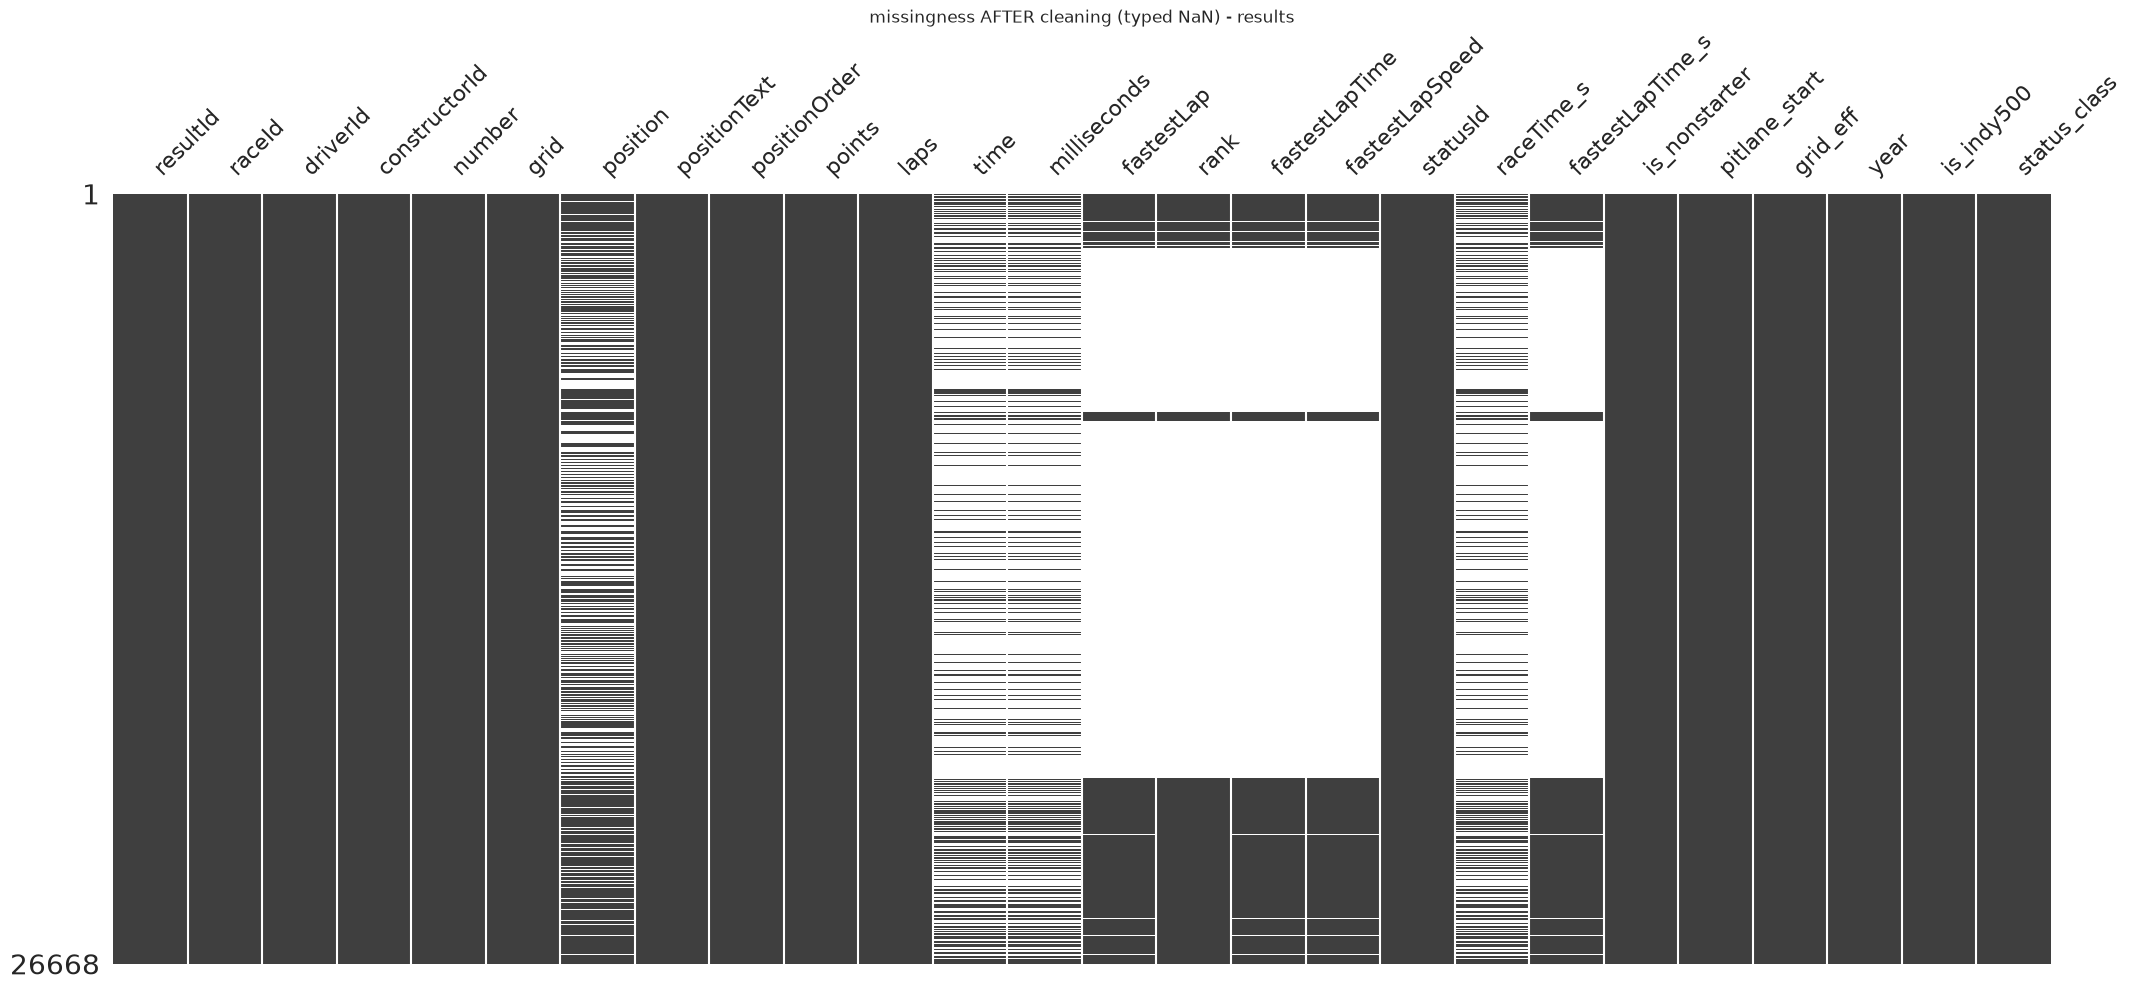

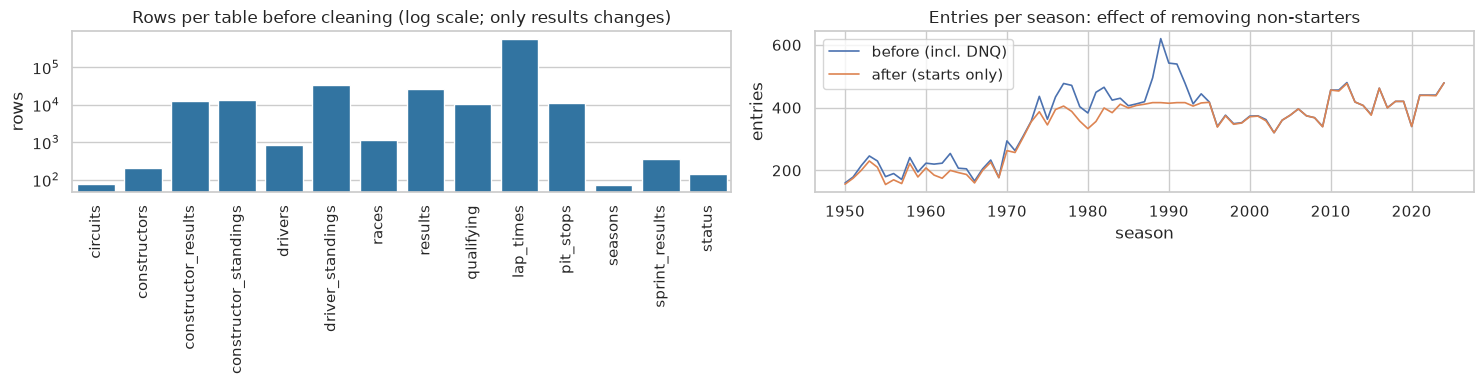

podium rate: raw 0.1269 -> R1 0.1273 -> R2 0.1267 (dedup effect negligible)
\nresults.info() AFTER cleaning (strings -> datetime/int/float/bool):
<class 'pandas.DataFrame'>
RangeIndex: 26668 entries, 0 to 26667
Data columns (total 28 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   resultId          26668 non-null  str    
 1   raceId            26668 non-null  str    
 2   driverId          26668 non-null  str    
 3   constructorId     26668 non-null  str    
 4   number            26662 non-null  Int64  
 5   grid              26668 non-null  Int64  
 6   position          15758 non-null  Int64  
 7   positionText      26668 non-null  str    
 8   positionOrder     26668 non-null  Int64  
 9   points            26668 non-null  Float64
 10  laps              26668 non-null  Int64  
 11  time              7663 non-null   str    
 12  milliseconds      7663 non-null   Float64
 13  fastestLap        8252 non-null   Int64  
 14 

In [36]:
# Step 9: before vs after cleaning (required by the brief)
msno.matrix(clean["results"].drop(columns=["status", "name"]), sparkline=False)
plt.title("missingness AFTER cleaning (typed NaN) - results")
plt.savefig(FIG_DIR / "fig_06_msno_after.png", dpi=150, bbox_inches="tight")
plt.show()

# Rows per table before/after, and cars per season before/after removing non-starters
counts = pd.DataFrame({"before": {t: len(data[t]) for t in TABLES},
                       "after": {t: len(clean[t]) for t in TABLES}})
counts["delta"] = counts["after"] - counts["before"]
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
sns.barplot(x=counts.index, y=counts["before"], ax=axes[0], color="#1f77b4")
axes[0].set_title("Rows per table before cleaning (log scale; only results changes)")
axes[0].set_yscale("log")
axes[0].set_xlabel("")
axes[0].set_ylabel("rows")
axes[0].tick_params(axis="x", rotation=90)
e = data["results"].merge(data["races"][["raceId", "year"]].astype({"year": int}), on="raceId")
e["entries"] = 1
before_y = e.groupby(e["year"].astype(int)).size()
a = clean["results"]
after_y = a[~a["is_nonstarter"]].groupby("year").size()
axes[1].plot(before_y.index, before_y.values, lw=1.2, label="before (incl. DNQ)")
axes[1].plot(after_y.index, after_y.values, lw=1.2, label="after (starts only)")
axes[1].set_title("Entries per season: effect of removing non-starters")
axes[1].set_ylabel("entries")
axes[1].set_xlabel("season"); axes[1].legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "fig_07_rowcounts.png", dpi=150)
plt.show()

# Podium rate: how much did removing duplicates change it?
r1rate = (pd.to_numeric(modeling_grain["positionOrder"], errors="coerce") <= 3).mean()
r2rate = (pd.to_numeric(clean["results"]["positionOrder"], errors="coerce") <= 3).mean()
print(f"podium rate: raw {pd.to_numeric(res['positionOrder'], errors='coerce').le(3).mean():.4f} -> "
      f"R1 {r1rate:.4f} -> R2 {r2rate:.4f} (dedup effect negligible)")
print("\\nresults.info() AFTER cleaning (strings -> datetime/int/float/bool):")
clean["results"].info()

In [37]:
# Summary: each cleaning step, how many rows it affected, and why
N = len(data["results"])
impact = pd.DataFrame([
    ("sentinel -> NaN (+ strip, quali '' -> NaN)", 0, "typing only; no rows touched"),
    ("one spelling per value + driver home country", 0, f"{n_relabelled} driver/team/circuit rows relabelled; no results rows touched"),
    ("drop url + fp*/quali wall-clock columns", 0, "12 cols; never used as features"),
    ("R2 dedup (shared drives, pre-1979)", N - n_unique, "one row per (raceId, driverId); 17-label R1 delta noted"),
    ("non-starters flagged (excluded downstream)", int(clean["results"]["is_nonstarter"].sum()), "DNQ/DNPQ/Withdrew, laps=0"),
    ("pit-lane starts flagged (kept, grid_eff)", int(clean["results"]["pitlane_start"].sum()), "laps>0 from grid 0"),
    ("Indy 500 flagged (Q2-excluded)", int(clean["results"]["is_indy500"].sum()), "1950-60 oval, Gate 2.E"),
], columns=["step", "rows", "% / note"])
display(impact)
print("Gates: 2.A parsing plausible + unit check passed | 2.B PK/FK clean, 0 orphans | 2.C R2 applied | "
      "2.D 72 kept-flagged / 1,563 excluded (1,566 pre-dedup) | 2.E Indy flagged")

,step,rows,% / note
0,"sentinel -> NaN (+ strip, quali '' -> NaN)",0,typing only; no rows touched
1,one spelling per value + driver home country,0,8 driver/team/circuit rows relabelled; no resu...
2,drop url + fp*/quali wall-clock columns,0,12 cols; never used as features
3,"R2 dedup (shared drives, pre-1979)",91,"one row per (raceId, driverId); 17-label R1 de..."
4,non-starters flagged (excluded downstream),1563,"DNQ/DNPQ/Withdrew, laps=0"
5,"pit-lane starts flagged (kept, grid_eff)",72,laps>0 from grid 0
6,Indy 500 flagged (Q2-excluded),381,"1950-60 oval, Gate 2.E"


Gates: 2.A parsing plausible + unit check passed | 2.B PK/FK clean, 0 orphans | 2.C R2 applied | 2.D 72 kept-flagged / 1,563 excluded (1,566 pre-dedup) | 2.E Indy flagged


All cleaning checkpoints (Gates 2.A–2.E) pass. The related decisions are D3, D4 and D7 in `docs/decisions.md`.

## 12. Decision log

Every choice we made along the way (what to keep, what to drop, how to split, …) with the date and the reason. It's kept as a table so it's visible in the notebook; the full text is in `docs/decisions.md`. Later sections add more entries, and some later entries replace earlier ones.

In [38]:
# Each entry: (number, what we decided, status, why / where it's explained).
# Later decisions can replace earlier ones (e.g. #17-#18 replace parts of #3, #8, #10).
DECISIONS = [
    (1, "Raw CSVs immutable; all cleaning on copies", "decided",
     "required by the brief; data/raw/ is never written to"),
    (2, "Grain = one row per (raceId, driverId)", "decided",
     "required by the brief; 85 shared-drive pairs in results"),
    (3, "Dedup = car the driver STARTED in (R2); fallback best posOrder", "decided",
     "Gate 2.C evidence 2026-10-03: 85 pairs, all pre-1979 (61 in 1950-58, last 1978); 22 involve "
     "a podium; R1<->R2 label delta 17/85; 3 pairs have no started-car row -> fallback best posOrder. "
     "R2 = lowest non-zero grid, tie-break first resultId (pre-race view, matches f1.pdf); "
     "modeling window 2003+ so the model itself is unaffected"),
    (4, "grid==0 split: 72 pit-lane starts vs 1,566 non-starters", "decided",
     "Gate 2.D evidence 2026-10-03: grid=0 & laps>0 (72: Finished/+N Laps) = pit-lane start -> flag "
     "+ re-coded grid; grid=0 & laps==0 (1,566: DNQ 1013/DNPQ 331/Withdrew 164, positionText F/W) = "
     "never started -> excluded from modeling and Q3 denominator. Refutes f1.pdf blanket pit-lane claim"),
    (5, "Q1 uses qualifying.position AND results.grid", "decided",
     "grid differs from qualifying position in a non-trivial share of entries (penalties), "
     "and the rate changes by era (the old Q1-inputs section, since removed; superseded by #23)"),
    (6, "Q2 mapping: full nationality->country map, 100% coverage asserted", "decided",
     "Phase 3 (13.2): 43 nationalities mapped (hyphenated->first part; non-GP countries map to self, "
     "home=0); circuits USA/United States->USA; 100%-coverage assert in code; Indy 500 excluded "
     "from the primary view (Gate Q2.A)"),
    (7, "Q3 taxonomy: strict mechanical + starts denominator, by constructorId", "decided",
     "Strict mechanical primary, confirmed by Q3.A: broad adds ~1.6pp, rankings stable (rho>0.95). "
     "Wings->ambiguous; Supercharger/ERS->mechanical; Out of fuel->ambiguous. Denominator = starts. "
     "constructorId primary + lineage view. Final: 2014-21 9.5% vs 2022-24 5.9%"),
    (8, "q2/q3 structural missingness pre-2003", "decided",
     "document as coverage limitation; needs era indicator or restricted window (section 8)"),
    (9, "Leakage allow/deny lists", "decided",
     "section 10; sprint_results still excluded by default pending a documented decision"),
    (10, "Split = pdf boundaries on window 2003+: tr 03-19 / val 20-21 / te 22-24", "decided",
     "decided 2026-10-03 per f1.pdf glossary (overrides plan default 03-18/19-21): train 6,831 rows "
     "(963 podiums), val 780 (117), test 1,359 (204) - counts re-verified when the Phase 4 table is built. Gate 6.B: val just under ~1k/150 rule of thumb "
     "-> expanding-window CV inside train for tuning; a random train_test_split kept as non-primary "
     "comparison (Gate 6.A)"),
    (11, "PR-AUC primary; ROC-AUC + F1@val-threshold secondary", "decided",
     "decided 2026-10-03: base rate 12.7% overall, ~15% modern era -> PR-AUC primary; +Precision/Recall "
     "(the brief's five); Accuracy reference-only (~87% no-skill, misleading on imbalance)"),
    (12, "Phase 2 cleaning on copies (types, R2, flags, taxonomy)", "decided",
     "2026-10-03, section 11: durations unit-checked (ms/1000), PK/FK 0 orphans, 72 pit-lane kept / "
     "1,566 non-starters out, Indy flagged, strict status taxonomy; impact table + before/after figs"),
]
decisions = pd.DataFrame(DECISIONS, columns=["#", "decision", "status", "rationale / where"])
display(decisions)
print(f"{(decisions['status'] == 'decided').sum()} decided, "
      f"{(decisions['status'] == 'open').sum()} open")

,#,decision,status,rationale / where
0,1,Raw CSVs immutable; all cleaning on copies,decided,required by the brief; data/raw/ is never writ...
1,2,"Grain = one row per (raceId, driverId)",decided,required by the brief; 85 shared-drive pairs i...
2,3,Dedup = car the driver STARTED in (R2); fallba...,decided,"Gate 2.C evidence 2026-10-03: 85 pairs, all pr..."
3,4,"grid==0 split: 72 pit-lane starts vs 1,566 non...",decided,Gate 2.D evidence 2026-10-03: grid=0 & laps>0 ...
4,5,Q1 uses qualifying.position AND results.grid,decided,grid differs from qualifying position in a non...
5,6,"Q2 mapping: full nationality->country map, 100...",decided,Phase 3 (13.2): 43 nationalities mapped (hyphe...
6,7,Q3 taxonomy: strict mechanical + starts denomi...,decided,"Strict mechanical primary, confirmed by Q3.A: ..."
7,8,q2/q3 structural missingness pre-2003,decided,document as coverage limitation; needs era ind...
8,9,Leakage allow/deny lists,decided,section 10; sprint_results still excluded by d...
9,10,Split = pdf boundaries on window 2003+: tr 03-...,decided,decided 2026-10-03 per f1.pdf glossary (overri...


12 decided, 0 open


## 13. Answers to the three data questions

For each question we join several tables, check after every join that the number of rows didn't change (if it grows, the join duplicated rows by mistake), give the answer with plots, and note the limitations. More detail: `docs/phase3.md`.

First, a helper: the **Wilson confidence interval**. If a circuit has only 12 front-row starts, a rate like "83%" is shaky. The Wilson interval gives a range (say 55%–95%) that the true rate is very likely (95%) to fall in. It works well even with small counts and with rates close to 0% or 100%.

In [39]:
# Wilson 95% confidence interval for a rate (successes / trials). We need it
# because many circuits have few starts, and a plain rate from 10 starts is very uncertain.
def wilson_interval(successes, trials, confidence=0.95):
    """Return (rate, lower bound, upper bound). Works on single numbers or whole arrays."""
    s = np.asarray(successes, dtype=float)
    n = np.asarray(trials, dtype=float)
    z = stats.norm.ppf(1 - (1 - confidence) / 2)
    p_hat = np.where(n > 0, s / n, 0.0)
    denominator = 1 + z**2 / n
    center = (p_hat + z**2 / (2 * n)) / denominator
    margin = (z / denominator) * np.sqrt(np.where(n > 0, (p_hat * (1 - p_hat) / n) + (z**2 / (4 * n**2)), 0.0))
    low = np.clip(center - margin, 0.0, 1.0)
    high = np.clip(center + margin, 0.0, 1.0)
    if np.ndim(successes) == 0 and np.ndim(trials) == 0:
        return float(p_hat), float(low), float(high)
    return p_hat, low, high

print("Wilson score interval helper defined. Test 10/10:", wilson_interval(10, 10))

Wilson score interval helper defined. Test 10/10: (1.0, 0.7224672001371107, 0.9999999999999999)


### 13.1 Q1: Which circuits turn a front-row start into a podium, and did that change from 2014?

**Front row** = starting from grid slot 1 or 2. We use **`grid`**, the slot the car actually started from (after any penalties), and **not** the qualifying position. Qualifying and grid can differ because of penalties, and the podium is fought from where the car really starts. On top of that, qualifying data is missing for most seasons before 2003, while grid exists for every race since 1950.

**Conversion rate** = front-row starters who finished on the podium ÷ all front-row starters. We compare **before 2014** with **2014 and later** (2014 is the start of the turbo-hybrid engine era), first over all circuits together and then circuit by circuit.

Three plots follow: a bar chart per circuit with uncertainty ranges, a heatmap of the same numbers, and a scatter plot showing whether circuits kept their ranking between the two eras.

In [40]:
# Q1: join results -> races -> circuits. After each join we check the row count didn't change;
# if it grew, the join duplicated rows by mistake.
n_init = len(clean["results"])
q1_df = clean["results"].drop(columns="year").merge(
    clean["races"][["raceId", "year", "name", "circuitId"]].rename(columns={"name": "race_name"}),
    on="raceId", how="inner"
)
assert len(q1_df) == n_init, "Grain altered after races merge"

q1_df = q1_df.merge(
    clean["circuits"][["circuitId", "name", "country"]].rename(columns={"name": "circuit_name"}),
    on="circuitId", how="inner"
)
assert len(q1_df) == n_init, "Grain altered after circuits merge"

q1_df["year"] = q1_df["year"].astype(int)
q1_df["podium"] = (q1_df["positionOrder"] <= 3).astype(int)
q1_df["front_row"] = q1_df["grid"].isin([1, 2])  # started from grid slot 1 or 2
q1_df["era"] = np.where(q1_df["year"] >= 2014, "2014+ (Turbo-Hybrid)", "Pre-2014")

print(f"Total driver-race entries analyzed: {len(q1_df):,}")
print(f"Total front-row starts: {q1_df['front_row'].sum():,}")

# Overall: share of front-row starters who finished on the podium, per era (with 95% range)
overall_q1 = []
for era in ["Pre-2014", "2014+ (Turbo-Hybrid)"]:
    fr = q1_df[(q1_df["era"] == era) & q1_df["front_row"]]
    rate, low, high = wilson_interval(fr["podium"].sum(), len(fr))
    overall_q1.append({"era": era, "front_row_starts": len(fr), "podiums": int(fr["podium"].sum()),
                       "conversion_rate": round(rate, 4), "95% range": f"[{low:.3f}, {high:.3f}]"})
df_q1_overall = pd.DataFrame(overall_q1).set_index("era")
display(df_q1_overall)

Total driver-race entries analyzed: 26,668
Total front-row starts: 2,259


,front_row_starts,podiums,conversion_rate,95% range
era,,,,
Pre-2014,1805,1002,0.5551,"[0.532, 0.578]"
2014+ (Turbo-Hybrid),454,345,0.7599,"[0.719, 0.797]"


#### Why we only rank circuits with at least 10 front-row starts in each era (Gate Q1.B)

The question is a ranking of circuits, and a ranking is only fair if every rate in it is measured on enough races.

- Every race has exactly **2 front-row starters**, so 10 front-row starts = **5 races** at that circuit in that era.
- With very few starts a rate can only take a few extreme values. A circuit used for a single race has 2 front-row starts, so its rate can only be 0%, 50% or 100%. If both front-row cars happened to finish on the podium that day, the circuit would top the ranking at 100% by pure luck.
- The 95% range (Wilson interval) makes this visible: the table printed below lists the circuits that were left out, and their ranges are very wide, often covering most of 0–100%. A number that could be anything between 20% and 100% can't be put in a ranking.
- **Nothing is thrown away from the overall answer.** The era-wide rates in the table above use *every* circuit. The filter only decides which circuits get their own place in the ranking.
- **Why 10?** It's a compromise: a higher bar leaves very few circuits to compare, a lower bar lets the noisy ones back in. The printout shows how many circuits pass for a few different thresholds.

circuits that pass, for different thresholds: {5: 21, 10: 16, 15: 13, 20: 7}
with K_MIN = 10: 16 circuits ranked, 61 left out
examples of left-out circuits (front-row starts, podiums, 95% range):


,circuit_name,era,podiums,front_row_starts,95% range
0,AVUS,Pre-2014,1,2,"[9%, 91%]"
1,Ain Diab,Pre-2014,2,2,"[34%, 100%]"
2,Autodromo Internazionale del Mugello,2014+ (Turbo-Hybrid),2,2,"[34%, 100%]"
3,Donington Park,Pre-2014,2,2,"[34%, 100%]"
4,Fair Park,Pre-2014,1,2,"[9%, 91%]"
5,Pescara Circuit,Pre-2014,2,2,"[34%, 100%]"
6,Le Mans,Pre-2014,1,2,"[9%, 91%]"
7,Monsanto Park Circuit,Pre-2014,1,2,"[9%, 91%]"
8,Nürburgring,2014+ (Turbo-Hybrid),1,2,"[9%, 91%]"
9,Riverside International Raceway,Pre-2014,1,2,"[9%, 91%]"


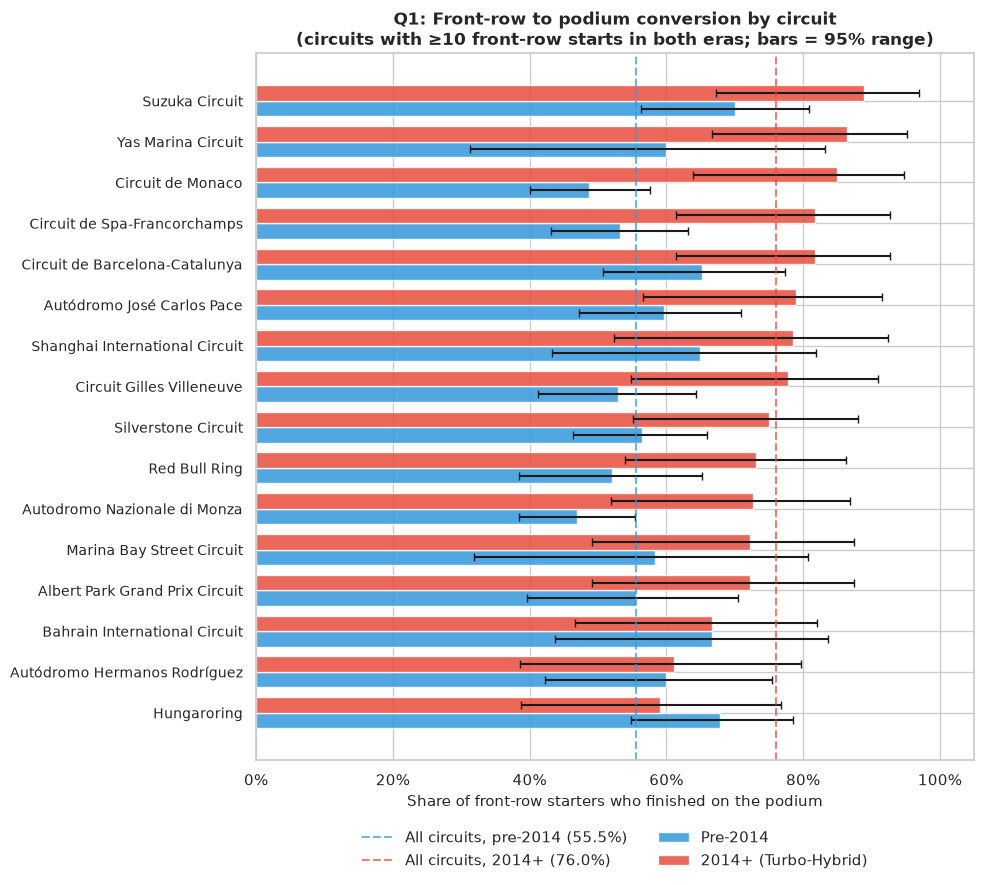

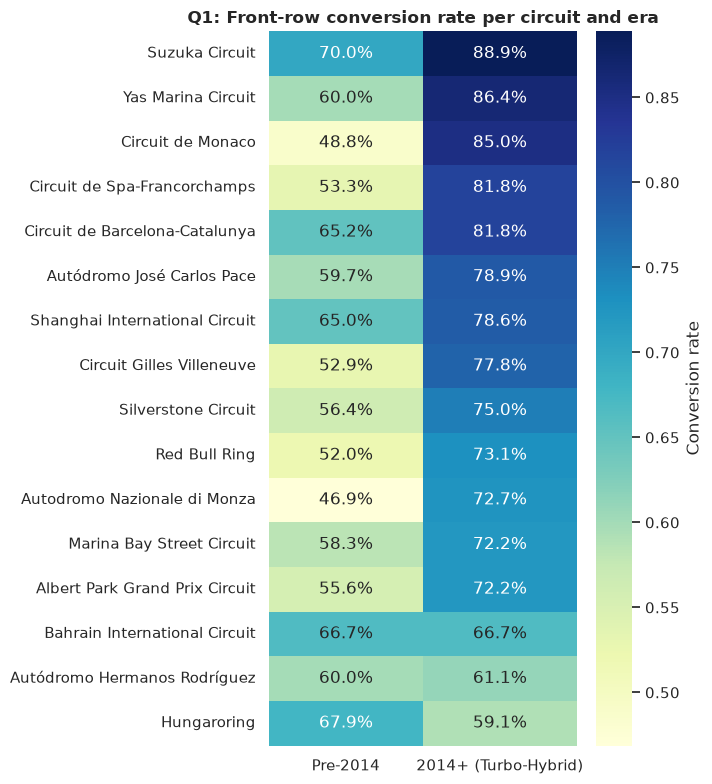

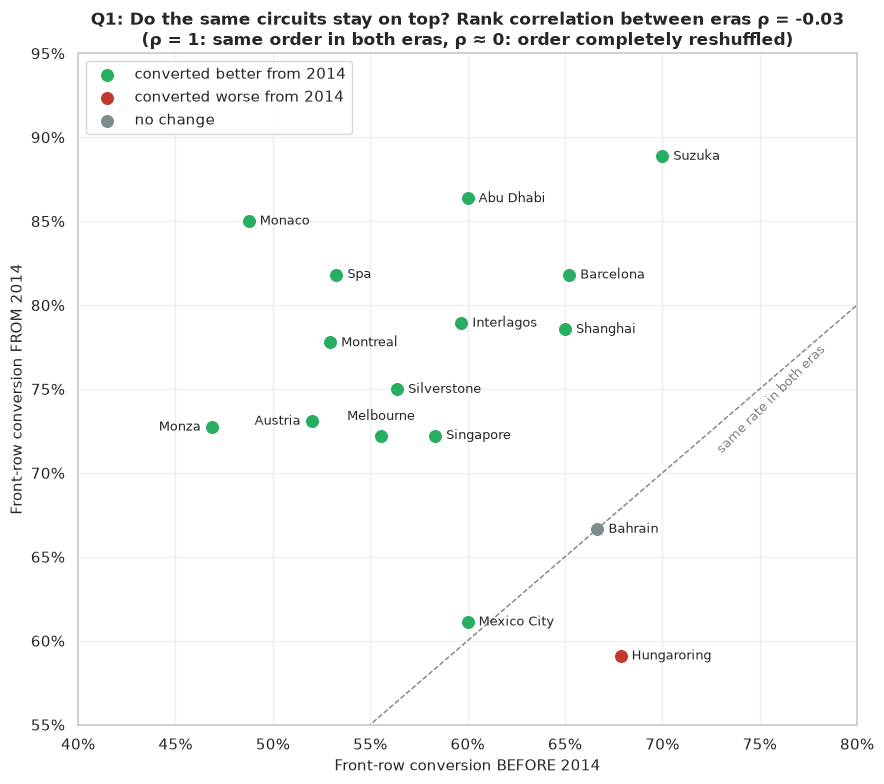

Spearman rank correlation between eras: -0.031


era,Pre-2014,2014+ (Turbo-Hybrid),Rank Pre-2014,Rank 2014+
circuit_name,,,,
Suzuka Circuit,0.700,0.889,1.0,1.0
Yas Marina Circuit,0.600,0.864,6.5,2.0
Circuit de Monaco,0.488,0.850,15.0,3.0
Circuit de Spa-Francorchamps,0.533,0.818,12.0,4.5
Circuit de Barcelona-Catalunya,0.652,0.818,4.0,4.5
Autódromo José Carlos Pace,0.597,0.789,8.0,6.0
Shanghai International Circuit,0.650,0.786,5.0,7.0
Circuit Gilles Villeneuve,0.529,0.778,13.0,8.0
Silverstone Circuit,0.564,0.750,10.0,9.0


In [41]:
# Gate Q1.B: only rank circuits with at least 10 front-row starts in BOTH eras (fewer is too noisy)
K_MIN = 10
circ_counts = q1_df[q1_df["front_row"]].groupby(["circuit_name", "era"]).size().unstack(fill_value=0)
both_eras = circ_counts.min(axis=1)  # front-row starts in the era where the circuit has fewer
common_circuits = both_eras[both_eras >= K_MIN].index.tolist()
print("circuits that pass, for different thresholds:",
      {k: int((both_eras >= k).sum()) for k in [5, 10, 15, 20]})
print(f"with K_MIN = {K_MIN}: {len(common_circuits)} circuits ranked, {len(both_eras) - len(common_circuits)} left out")

# What the left-out circuits look like: few starts -> very wide 95% ranges
fr_all = q1_df[q1_df["front_row"]].groupby(["circuit_name", "era"])["podium"].agg(["sum", "count"]).reset_index()
_, lo_all, hi_all = wilson_interval(fr_all["sum"], fr_all["count"])
fr_all["95% range"] = [f"[{l:.0%}, {h:.0%}]" for l, h in zip(lo_all, hi_all)]
left_out = fr_all[~fr_all["circuit_name"].isin(common_circuits)]
print("examples of left-out circuits (front-row starts, podiums, 95% range):")
display(left_out.sort_values("count").rename(columns={"count": "front_row_starts", "sum": "podiums"})
        .head(10).reset_index(drop=True))

circ_stats = fr_all[fr_all["circuit_name"].isin(common_circuits)].drop(columns="95% range").copy()
rate, low, high = wilson_interval(circ_stats["sum"], circ_stats["count"])
circ_stats["rate"] = rate
circ_stats["err_low"] = rate - low
circ_stats["err_high"] = high - rate
# Era averages come from the table above (not typed in by hand, so they update if the data changes)
overall_pre = float(df_q1_overall.loc["Pre-2014", "conversion_rate"])
overall_post = float(df_q1_overall.loc["2014+ (Turbo-Hybrid)", "conversion_rate"])

# Figure 8: conversion rate per circuit, before vs from 2014, with 95% error bars
order = circ_stats[circ_stats["era"] == "2014+ (Turbo-Hybrid)"].sort_values("rate", ascending=True)["circuit_name"].tolist()
pre_data = circ_stats[circ_stats["era"] == "Pre-2014"].set_index("circuit_name").loc[order]
post_data = circ_stats[circ_stats["era"] == "2014+ (Turbo-Hybrid)"].set_index("circuit_name").loc[order]

fig, ax = plt.subplots(figsize=(10, 9))
y_pos = np.arange(len(order))
height = 0.38
ax.barh(y_pos - height/2, pre_data["rate"], height=height, label="Pre-2014", color="#3498db", alpha=0.85,
        xerr=[pre_data["err_low"], pre_data["err_high"]], capsize=3)
ax.barh(y_pos + height/2, post_data["rate"], height=height, label="2014+ (Turbo-Hybrid)", color="#e74c3c", alpha=0.85,
        xerr=[post_data["err_low"], post_data["err_high"]], capsize=3)
ax.axvline(overall_pre, color="#3498db", linestyle="--", alpha=0.7, label=f"All circuits, pre-2014 ({overall_pre:.1%})")
ax.axvline(overall_post, color="#e74c3c", linestyle="--", alpha=0.7, label=f"All circuits, 2014+ ({overall_post:.1%})")
ax.set_yticks(y_pos)
ax.set_yticklabels(order, fontsize=10)
ax.set_xlim(0, 1.05)
ax.xaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0))
ax.set_xlabel("Share of front-row starters who finished on the podium", fontsize=11)
ax.set_title(f"Q1: Front-row to podium conversion by circuit\n(circuits with ≥{K_MIN} front-row starts in both eras; bars = 95% range)",
             fontsize=12, fontweight="bold")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=2, frameon=False)
plt.tight_layout()
plt.savefig(FIG_DIR / "fig_08_q1_conversion_bars.png", dpi=150)
plt.show()

# Figure 9: the same numbers as a colour grid (circuit x era)
piv_heat = circ_stats.pivot(index="circuit_name", columns="era", values="rate").loc[order[::-1]]
piv_heat = piv_heat[["Pre-2014", "2014+ (Turbo-Hybrid)"]]
fig, ax = plt.subplots(figsize=(7, 8))
sns.heatmap(piv_heat, annot=True, fmt=".1%", cmap="YlGnBu", cbar_kws={"label": "Conversion rate"}, ax=ax)
ax.set_title("Q1: Front-row conversion rate per circuit and era", fontsize=12, fontweight="bold")
ax.set_xlabel("")
ax.set_ylabel("")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig_09_q1_heatmap_pivot.png", dpi=150)
plt.show()

# Figure 10: did circuits keep their place? One dot per circuit: x = pre-2014 rate, y = 2014+ rate.
# If the ranking had stayed the same, the dots would line up from bottom-left to top-right.
# Dots above the dashed line converted better from 2014 on, dots below converted worse.
ranked = piv_heat.copy()
ranked["Rank Pre-2014"] = ranked["Pre-2014"].rank(ascending=False)
ranked["Rank 2014+"] = ranked["2014+ (Turbo-Hybrid)"].rank(ascending=False)
spearman_corr = ranked[["Rank Pre-2014", "Rank 2014+"]].corr(method="spearman").iloc[0, 1]

SHORT = {"Suzuka Circuit": "Suzuka", "Yas Marina Circuit": "Abu Dhabi", "Circuit de Monaco": "Monaco",
         "Circuit de Spa-Francorchamps": "Spa", "Circuit de Barcelona-Catalunya": "Barcelona",
         "Autódromo José Carlos Pace": "Interlagos", "Shanghai International Circuit": "Shanghai",
         "Circuit Gilles Villeneuve": "Montreal", "Silverstone Circuit": "Silverstone", "Red Bull Ring": "Austria",
         "Autodromo Nazionale di Monza": "Monza", "Marina Bay Street Circuit": "Singapore",
         "Albert Park Grand Prix Circuit": "Melbourne", "Bahrain International Circuit": "Bahrain",
         "Autódromo Hermanos Rodríguez": "Mexico City", "Hungaroring": "Hungaroring"}
fig, ax = plt.subplots(figsize=(9, 8))
x, y = ranked["Pre-2014"], ranked["2014+ (Turbo-Hybrid)"]
same = (y - x).abs() < 0.005  # equal rate in both eras
up = (y > x) & ~same
down = (y < x) & ~same
ax.plot([0, 1], [0, 1], color="grey", linestyle="--", lw=1, zorder=1)
ax.text(0.785, 0.772, "same rate in both eras", color="grey", fontsize=9, ha="right", va="bottom",
        rotation=45, rotation_mode="anchor")
ax.scatter(x[up], y[up], s=70, color="#27ae60", zorder=3, label="converted better from 2014")
ax.scatter(x[down], y[down], s=70, color="#c0392b", zorder=3, label="converted worse from 2014")
ax.scatter(x[same], y[same], s=70, color="#7f8c8d", zorder=3, label="no change")
ax.set_xlim(0.4, 0.8)
ax.set_ylim(0.55, 0.95)
# Put each name next to its dot, trying 8 spots around it and taking the first that overlaps
# nothing already drawn (other names or dots).
fig.canvas.draw()
renderer = fig.canvas.get_renderer()
taken = [ax.transData.transform((xi, yi)) for xi, yi in zip(x, y)]
taken = [matplotlib.transforms.Bbox.from_extents(px - 6, py - 6, px + 6, py + 6) for px, py in taken]
spots = [(8, 0, "left", "center"), (-8, 0, "right", "center"), (0, 9, "center", "bottom"), (0, -9, "center", "top"),
         (7, 7, "left", "bottom"), (-7, 7, "right", "bottom"), (7, -7, "left", "top"), (-7, -7, "right", "top")]
for circ in ranked.index:
    for dx, dy, ha, va in spots:
        t = ax.annotate(SHORT.get(circ, circ), (x[circ], y[circ]), xytext=(dx, dy), textcoords="offset points",
                        ha=ha, va=va, fontsize=9.5)
        bb = t.get_window_extent(renderer).expanded(1.05, 1.1)
        if not any(bb.overlaps(o) for o in taken):
            taken.append(bb)
            break
        t.remove()
    else:
        taken.append(ax.annotate(SHORT.get(circ, circ), (x[circ], y[circ]), xytext=(8, 0), textcoords="offset points",
                                 ha="left", va="center", fontsize=9.5).get_window_extent(renderer))
ax.xaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0, decimals=0))
ax.yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0, decimals=0))
ax.set_xlabel("Front-row conversion BEFORE 2014", fontsize=11)
ax.set_ylabel("Front-row conversion FROM 2014", fontsize=11)
ax.set_title(f"Q1: Do the same circuits stay on top? Rank correlation between eras ρ = {spearman_corr:.2f}\n"
             "(ρ = 1: same order in both eras, ρ ≈ 0: order completely reshuffled)", fontsize=12, fontweight="bold")
ax.legend(loc="upper left")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIG_DIR / "fig_10_q1_rank_change.png", dpi=150)
plt.show()

print(f"Spearman rank correlation between eras: {spearman_corr:.3f}")
display(ranked.sort_values("Rank 2014+")[["Pre-2014", "2014+ (Turbo-Hybrid)", "Rank Pre-2014", "Rank 2014+"]].round(3))

**Answer Q1:** A front-row start turns into a podium much more often now: **55.5% before 2014 → 76.0% from 2014**. The best circuits in the modern era are Suzuka (88.9%), Yas Marina (86.4%) and Monaco (85.0%). But the circuit **ranking was completely reshuffled** between the eras (rank correlation ρ ≈ 0), so "which tracks reward a front-row start" isn't a stable property of the track. Details: `docs/phase3.md`.

### 13.2 Q2: Do drivers do better at their home race?

A home race is a race at a circuit in the driver's own country. The driver's `home_country` was added during cleaning (§11, step 3), written the same way as the circuit's country, so here it's a simple comparison.

Simply comparing home and away podium rates would be unfair, because home and away drivers may start from different positions. So we compare like with like, in two ways:
1. **Stratified comparison:** split entries into starting-position groups (pole, 2–3, 4–6, 7–10, 11+), compare the home and away podium rate inside each group, then average the differences.
2. **Logistic regression:** predict podium from home/away + starting group + era. The home coefficient turns into an **odds ratio**: 1.0 = no effect, above 1 = being at home helps, below 1 = it hurts.

**How sure are we? (bootstrap)** We only have one history of F1, so to see how much the odds ratio could change by chance we *simulate* other histories: pick races at random from our own data (the same race can be picked more than once), refit the regression, and repeat 400 times. The middle 95% of those 400 odds ratios is our 95% range. If that range includes 1.0, the data can't tell a home advantage apart from no effect at all. We resample whole races, not single drivers, because results in the same race depend on each other (only 3 drivers can be on the podium).

The **Indy 500** is left out: it was an American oval race that counted for the championship in 1950–60, but regular F1 drivers almost never entered, so it would distort the home effect.

In [42]:
# Join results -> drivers -> races -> circuits (starters only), checking the row count after each join
q2_df = clean["results"][~clean["results"]["is_nonstarter"]].drop(columns="year").copy()
n_q2_starts = len(q2_df)
q2_df = q2_df.merge(clean["drivers"][["driverId", "home_country"]], on="driverId", how="inner")
assert len(q2_df) == n_q2_starts, "Grain altered after drivers merge"

q2_df = q2_df.merge(clean["races"][["raceId", "year", "circuitId"]], on="raceId", how="inner")
assert len(q2_df) == n_q2_starts, "Grain altered after races merge"

q2_df = q2_df.merge(clean["circuits"][["circuitId", "country"]].rename(columns={"country": "circuit_country"}), on="circuitId", how="inner")
assert len(q2_df) == n_q2_starts, "Grain altered after circuits merge"

# home race = driver's home country (from cleaning step 3) is the circuit's country
q2_df["is_home"] = (q2_df["home_country"] == q2_df["circuit_country"]).astype(int)
q2_df["podium"] = (q2_df["positionOrder"] <= 3).astype(int)
q2_df["year"] = q2_df["year"].astype(int)
# Group starting positions: pole, 2-3, 4-6, 7-10, 11+
q2_df["grid_bin"] = pd.cut(q2_df["grid_eff"], bins=[0, 1, 3, 6, 10, 100], labels=["1 (Pole)", "2-3", "4-6", "7-10", "11+"])

# Leave out the Indy 500 (US oval race that regular F1 drivers rarely entered)
q2_main = q2_df[~q2_df["is_indy500"]].copy()
print(f"Total starts analyzed (excl. Indy 500): {len(q2_main):,}")
print(f"Home starts: {q2_main['is_home'].sum():,} ({q2_main['is_home'].mean():.2%}) | Away starts: {(q2_main['is_home']==0).sum():,}")

Total starts analyzed (excl. Indy 500): 24,724
Home starts: 1,944 (7.86%) | Away starts: 22,780


,Away Podium Rate,Home Podium Rate,Difference (H - A),Home Starts,Away Starts,Home Weight
grid_bin,,,,,,
1 (Pole),0.6423,0.5833,-0.0590,84,1040,0.0432
2-3,0.5087,0.5374,0.0288,147,2078,0.0756
4-6,0.2601,0.2643,0.0042,227,3114,0.1168
7-10,0.0921,0.0714,-0.0206,336,4117,0.1728
11+,0.0164,0.0104,-0.0060,1150,12431,0.5916


Grid-Weighted Average Difference: -0.0070 (-0.70 percentage points)


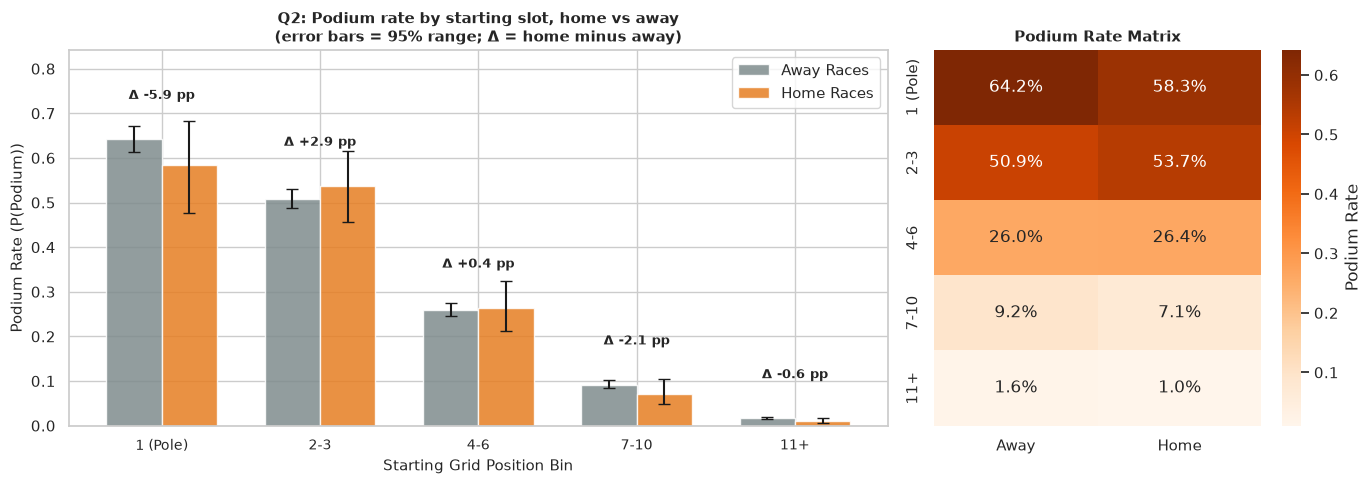

Logistic Regression Home Odds Ratio: 0.9149
Bootstrap 95% range: [0.7851, 1.0817] -> includes 1.0 (no effect)? True


In [43]:
# Method 1, stratified: inside each starting-position group, compare home vs away podium rate,
# then average the differences (weighted by how many home starts each group has).
piv_mean = q2_main.pivot_table(index="grid_bin", columns="is_home", values="podium", aggfunc="mean", observed=False)
piv_count = q2_main.pivot_table(index="grid_bin", columns="is_home", values="podium", aggfunc="count", observed=False)
diff = piv_mean[1] - piv_mean[0]
weights = piv_count[1] / piv_count[1].sum()
weighted_diff = (diff * weights).sum()

summary_strat = pd.DataFrame({
    "Away Podium Rate": piv_mean[0], "Home Podium Rate": piv_mean[1],
    "Difference (H - A)": diff, "Home Starts": piv_count[1],
    "Away Starts": piv_count[0], "Home Weight": weights
})
display(summary_strat.round(4))
print(f"Grid-Weighted Average Difference: {weighted_diff:+.4f} ({weighted_diff*100:+.2f} percentage points)")

# Figure 11: home vs away podium rate per starting group (left) and as a colour grid (right)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [2, 1]})

bins = piv_mean.index.tolist()
x = np.arange(len(bins))
w = 0.35

rate_away, low_a, high_a = wilson_interval(piv_mean[0] * piv_count[0], piv_count[0])
rate_home, low_h, high_h = wilson_interval(piv_mean[1] * piv_count[1], piv_count[1])

ax1.bar(x - w/2, piv_mean[0], width=w, label="Away Races", color="#7f8c8d", alpha=0.85,
        yerr=[rate_away - low_a, high_a - rate_away], capsize=4)
ax1.bar(x + w/2, piv_mean[1], width=w, label="Home Races", color="#e67e22", alpha=0.85,
        yerr=[rate_home - low_h, high_h - rate_home], capsize=4)

for i in range(len(bins)):
    gap = diff.iloc[i] * 100
    ax1.text(x[i], max(piv_mean.iloc[i]) + 0.09, f"Δ {gap:+.1f} pp", ha="center", fontsize=9, fontweight="bold")

ax1.set_xticks(x)
ax1.set_xticklabels(bins, fontsize=10)
ax1.set_xlabel("Starting Grid Position Bin", fontsize=11)
ax1.set_ylabel("Podium Rate (P(Podium))", fontsize=11)
ax1.set_ylim(0, min(1.0, float(piv_mean.max().max()) + 0.2))
ax1.set_title("Q2: Podium rate by starting slot, home vs away\n(error bars = 95% range; Δ = home minus away)", fontsize=11, fontweight="bold")
ax1.legend(loc="upper right")

# right panel: colour grid
heat_data = piv_mean.rename(columns={0: "Away", 1: "Home"})
sns.heatmap(heat_data, annot=True, fmt=".1%", cmap="Oranges", ax=ax2, cbar_kws={"label": "Podium Rate"})
ax2.set_title("Podium Rate Matrix", fontsize=11, fontweight="bold")
ax2.set_ylabel("")
ax2.set_xlabel("")

plt.tight_layout()
plt.savefig(FIG_DIR / "fig_11_q2_stratified_bars.png", dpi=150)
plt.show()

# Method 2, logistic regression: podium ~ home + starting group + era.
# exp(home coefficient) = odds ratio: 1.0 = no home effect, > 1 = home helps, < 1 = home hurts.
# C=1e5 means practically no regularisation: we want the plain estimate, not a shrunk one.
q2_main["era"] = pd.cut(q2_main["year"], bins=[1949, 1979, 2013, 2030], labels=["pre-1980", "1980-2013", "2014+"])
X_cols = pd.get_dummies(q2_main[["is_home", "grid_bin", "era"]], drop_first=True)
y_all = q2_main["podium"]

lr = LogisticRegression(max_iter=1000, C=1e5)
lr.fit(X_cols, y_all)
home_coef = lr.coef_[0][0]
home_or = np.exp(home_coef)

# Bootstrap: draw whole races at random (the same race can be drawn twice) 400 times and refit.
# The middle 95% of the 400 odds ratios is the 95% range. Whole races, because drivers in the
# same race affect each other.
np.random.seed(42)
unique_races = q2_main["raceId"].unique()
boot_ors = []
for _ in range(400):
    sample_races = pd.DataFrame({"raceId": np.random.choice(unique_races, size=len(unique_races), replace=True)})
    sample_df = sample_races.merge(q2_main, on="raceId", how="inner")
    X_b = pd.get_dummies(sample_df[["is_home", "grid_bin", "era"]], drop_first=True).reindex(columns=X_cols.columns, fill_value=0)
    lr_b = LogisticRegression(max_iter=500, C=1e5)
    lr_b.fit(X_b, sample_df["podium"])
    boot_ors.append(np.exp(lr_b.coef_[0][0]))

ci_low, ci_high = np.percentile(boot_ors, [2.5, 97.5])
print(f"Logistic Regression Home Odds Ratio: {home_or:.4f}")
print(f"Bootstrap 95% range: [{ci_low:.4f}, {ci_high:.4f}] -> includes 1.0 (no effect)? {ci_low <= 1.0 <= ci_high}")

**Answer Q2:** **No home advantage.** Starting from the same position, home drivers are actually 0.70 percentage points *less* likely to get a podium. The odds ratio is 0.915 with a 95% range of [0.785, 1.082]. That range includes 1.0, so we can't tell it apart from "no effect at all". Details: `docs/phase3.md`.

### 13.3 Q3: Which teams' cars break down most often, 2014–2021 vs 2022–2024?

**Mechanical retirement rate** = race starts that ended because a part of the car failed ÷ all race starts. Drivers who never started (didn't qualify, withdrew) don't count. To keep it simple, every unclear reason (punctures, wing failures, fires, "Retired" with no reason given, …) counts as mechanical; only "Refuelling" (a pit-stop incident) doesn't (decision #24, cleaning step 8).

**Why compare 2014–2021 with 2022–2024?** The brief asks for exactly these two periods, and they match the two big rule changes in modern F1:
- **2014:** new turbo-hybrid power units (a 1.6-litre V6 plus energy-recovery systems), a very complicated new kind of engine.
- **2022:** completely new car designs (ground-effect aerodynamics, bigger 18-inch wheels), while engine development was frozen, so teams had been working on the same engines for years.

Within each period the rules stayed roughly the same, so teams are compared under the same conditions; comparing the two periods shows what the rule change did. The periods have different lengths (8 seasons vs 3), which is why we compare **rates** (per start), never raw counts.

**Two team views:** per `constructorId` (each team name on its own), and per **lineage**, which groups teams that were renamed but stayed the same factory (e.g. Force India → Racing Point → Aston Martin).

In [44]:
# Q3: starters only, joined to races and team names (row count checked after each join)
q3_starts = clean["results"][~clean["results"]["is_nonstarter"]].drop(columns="year").copy()
n_q3_init = len(q3_starts)

q3_starts = q3_starts.merge(clean["races"][["raceId", "year"]], on="raceId", how="inner")
assert len(q3_starts) == n_q3_init, "Grain altered after races merge"

q3_starts = q3_starts.merge(clean["constructors"][["constructorId", "name"]].rename(columns={"name": "constructor_name"}), on="constructorId", how="inner")
assert len(q3_starts) == n_q3_init, "Grain altered after constructors merge"

q3_starts["year"] = q3_starts["year"].astype(int)
# Keep 2014-2024 and split it into the two periods
q3_starts = q3_starts[q3_starts["year"].between(2014, 2024)].copy()
q3_starts["period"] = np.where(q3_starts["year"].between(2014, 2021), "2014-2021", "2022-2024")
q3_starts["mech"] = (q3_starts["status_class"] == "mechanical").astype(int)

# Teams that changed name are grouped under one 'lineage' (same factory, new name)
LINEAGE_MAP = {
    "Ferrari": "Ferrari", "Mercedes": "Mercedes", "Red Bull": "Red Bull",
    "McLaren": "McLaren", "Williams": "Williams", "Haas F1 Team": "Haas",
    "Renault": "Renault / Alpine", "Alpine F1 Team": "Renault / Alpine", "Lotus F1": "Renault / Alpine",
    "Sauber": "Sauber / Alfa Romeo", "Alfa Romeo": "Sauber / Alfa Romeo",
    "Toro Rosso": "Toro Rosso / AlphaTauri / RB", "AlphaTauri": "Toro Rosso / AlphaTauri / RB", "RB F1 Team": "Toro Rosso / AlphaTauri / RB",
    "Force India": "Force India / Racing Point / Aston Martin", "Racing Point": "Force India / Racing Point / Aston Martin",
    "Aston Martin": "Force India / Racing Point / Aston Martin", "Caterham": "Caterham",
    "Marussia": "Marussia / Manor", "Manor Marussia": "Marussia / Manor",
}
q3_starts["lineage"] = q3_starts["constructor_name"].map(LINEAGE_MAP)

# Overall mechanical retirement rate per period, with 95% ranges
overall_q3 = q3_starts.groupby("period").agg(starts=("mech", "size"), mechanical_retirements=("mech", "sum"))
r_m, l_m, h_m = wilson_interval(overall_q3["mechanical_retirements"], overall_q3["starts"])
overall_q3["rate"] = np.round(r_m, 4)
overall_q3["95% range"] = [f"[{l:.3f}, {h:.3f}]" for l, h in zip(l_m, h_m)]
display(overall_q3)

,starts,mechanical_retirements,rate,95% range
period,,,,
2014-2021,3263,365,0.1119,"[0.101, 0.123]"
2022-2024,1356,94,0.0693,"[0.057, 0.084]"


#### Why only teams with at least 30 starts?

A rate measured on very few starts is unreliable: a team with 6 starts and 2 failures would show 33% and top the chart, even though two unlucky races say little. A full season is about 20–24 races × 2 cars ≈ **40–48 starts**, so 30 starts means "raced for at least most of a season". The cell below prints every team with its number of starts. In our data **no team is actually left out**: the smallest is Marussia with 31 starts in 2014–2021 (Caterham has 34). So the rule is only a safeguard; it would matter if, for example, a team that entered only a few races were added. Small teams like Caterham still get very wide 95% ranges in Figure 13, which is the honest way to show that their rate is less certain.

The lineage heatmap (Figure 14) needs no such rule: every lineage has at least 34 starts in each period, because lineages combine all the names a team raced under.

teams below 30 starts (left out of Figure 13):


,,failures,starts
period,constructor_name,,


starts per team in each period (smallest first):


period,2014-2021,2022-2024
constructor_name,,
Sauber,200.0,48.0
RB F1 Team,NaN,48.0
Alfa Romeo,120.0,88.0
AlphaTauri,77.0,88.0
Haas F1 Team,244.0,135.0
Williams,319.0,135.0
Aston Martin,44.0,135.0
Ferrari,319.0,135.0
Mercedes,320.0,136.0


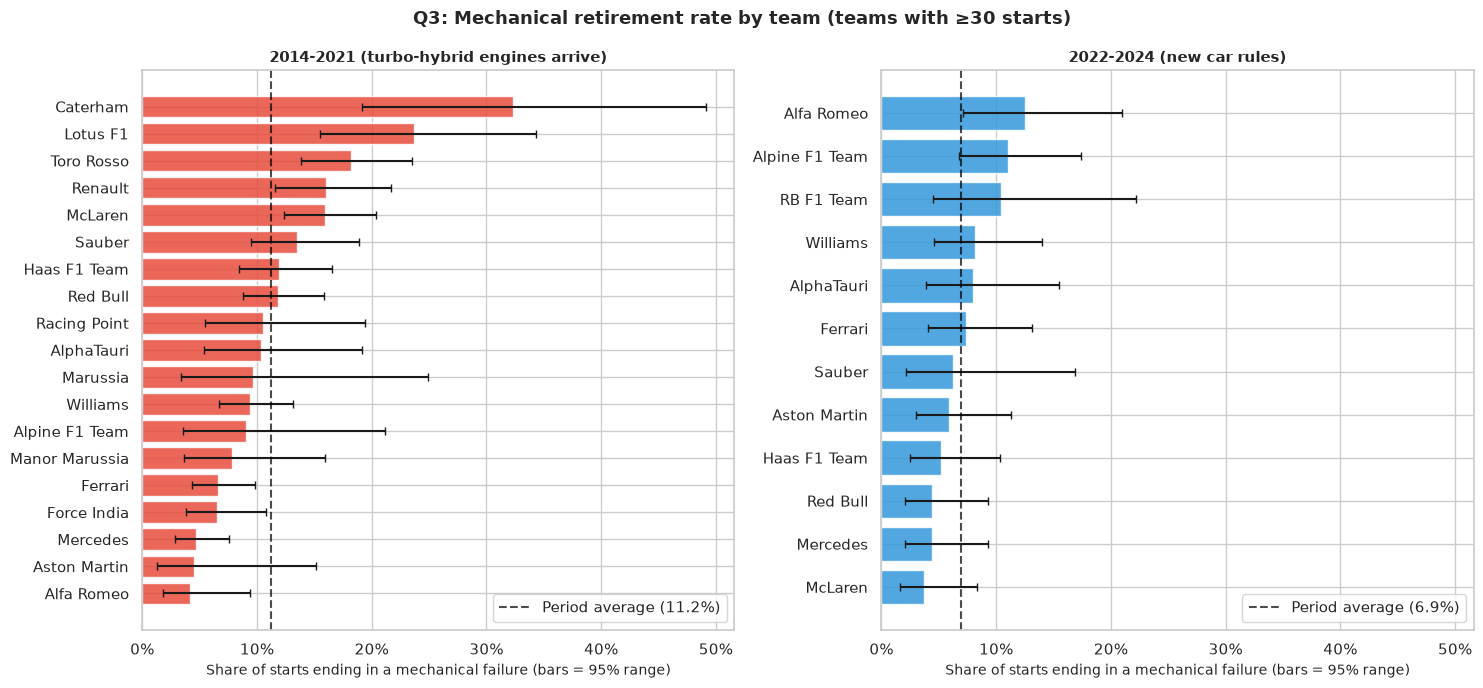

smallest lineage sample: 34 starts


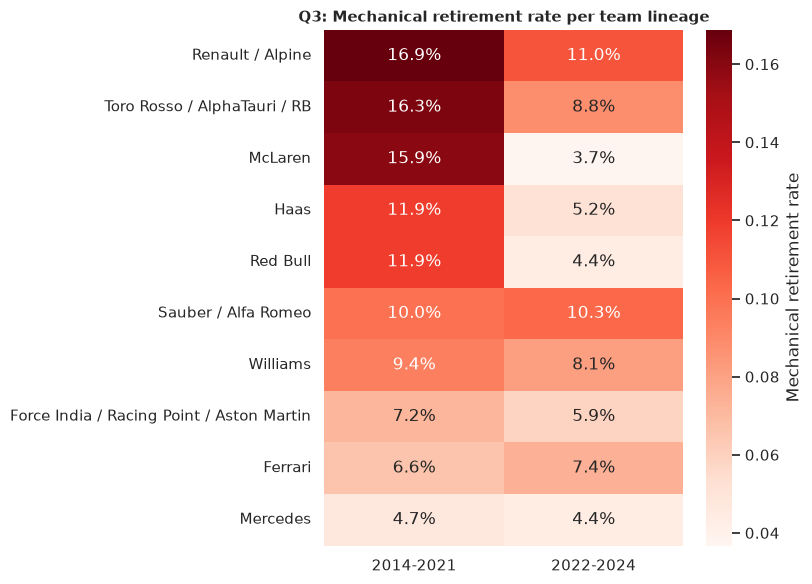

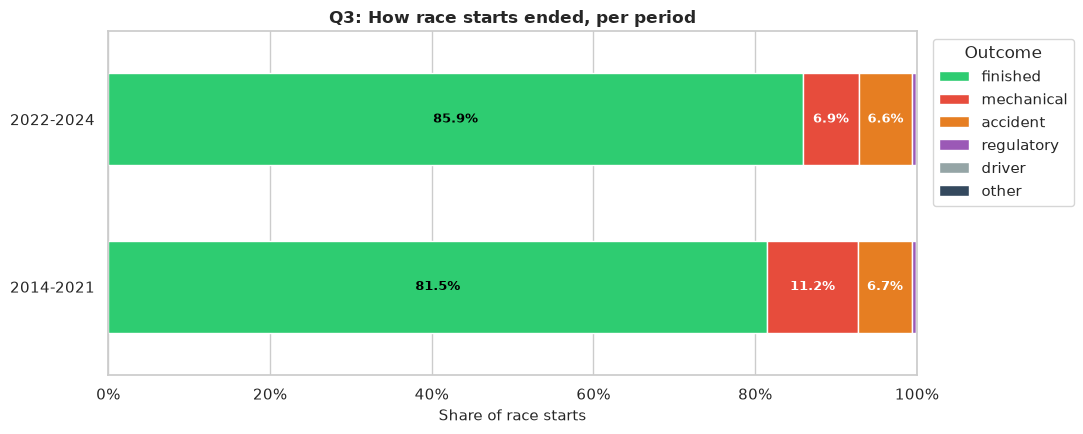

Highest mechanical failure rates 2014-2021:


,starts,failures,rate
constructor_name,,,
Caterham,34,11,0.323529
Lotus F1,76,18,0.236842
Toro Rosso,242,44,0.181818
Renault,200,32,0.160000
McLaren,320,51,0.159375
Sauber,200,27,0.135000


Highest mechanical failure rates 2022-2024:


,starts,failures,rate
constructor_name,,,
Alfa Romeo,88,11,0.125000
Alpine F1 Team,136,15,0.110294
RB F1 Team,48,5,0.104167
Williams,135,11,0.081481
AlphaTauri,88,7,0.079545
Ferrari,135,10,0.074074


In [45]:
# Per team (each team name on its own). Only teams with at least MIN_STARTS starts in a period get a bar.
MIN_STARTS = 30
era_avg_p1 = float(overall_q3.loc["2014-2021", "rate"])
era_avg_p2 = float(overall_q3.loc["2022-2024", "rate"])
team = q3_starts.groupby(["period", "constructor_name"])["mech"].agg(["sum", "count"])
print(f"teams below {MIN_STARTS} starts (left out of Figure 13):")
display(team[team["count"] < MIN_STARTS].rename(columns={"count": "starts", "sum": "failures"}))
print("starts per team in each period (smallest first):")
display(team["count"].unstack(0).sort_values("2022-2024"))


def team_rates(period):
    sub = team.loc[period]
    sub = sub[sub["count"] >= MIN_STARTS].copy()
    r, l, h = wilson_interval(sub["sum"], sub["count"])
    sub["rate"], sub["err_l"], sub["err_h"] = r, r - l, h - r
    return sub.sort_values("rate")


p1_sorted, p2_sorted = team_rates("2014-2021"), team_rates("2022-2024")

# Figure 13: mechanical retirement rate per team, one panel per period; dashed line = period average
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 7), sharex=True)
for ax, data_p, avg, colour, title in [
        (ax1, p1_sorted, era_avg_p1, "#e74c3c", "2014-2021 (turbo-hybrid engines arrive)"),
        (ax2, p2_sorted, era_avg_p2, "#3498db", "2022-2024 (new car rules)")]:
    ax.barh(data_p.index, data_p["rate"], color=colour, alpha=0.85,
            xerr=[data_p["err_l"], data_p["err_h"]], capsize=3)
    ax.axvline(avg, color="black", linestyle="--", alpha=0.7, label=f"Period average ({avg:.1%})")
    ax.set_title(title, fontsize=11, fontweight="bold")
    ax.set_xlabel("Share of starts ending in a mechanical failure (bars = 95% range)", fontsize=10)
    ax.xaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0))
    ax.legend(loc="lower right")
fig.suptitle(f"Q3: Mechanical retirement rate by team (teams with ≥{MIN_STARTS} starts)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig_13_q3_constructor_bars.png", dpi=150)
plt.show()

# Figure 14: the same rate per team lineage (renamed teams grouped together) as a colour grid
lineage_grp = q3_starts.groupby(["lineage", "period"])["mech"].agg(["sum", "count"]).reset_index()
print(f"smallest lineage sample: {lineage_grp['count'].min()} starts")
lineage_grp["rate"] = lineage_grp["sum"] / lineage_grp["count"]
piv_lin = lineage_grp.pivot(index="lineage", columns="period", values="rate").dropna()
piv_lin = piv_lin.sort_values("2014-2021", ascending=False)

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(piv_lin, annot=True, fmt=".1%", cmap="Reds", ax=ax, cbar_kws={"label": "Mechanical retirement rate"})
ax.set_title("Q3: Mechanical retirement rate per team lineage", fontsize=11, fontweight="bold")
ax.set_xlabel("")
ax.set_ylabel("")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig_14_q3_heatmap_pivot.png", dpi=150)
plt.show()

# Figure 15: how all race starts ended, per period, as stacked shares
classes = ["finished", "mechanical", "accident", "regulatory", "driver", "other"]
comp = q3_starts.groupby(["period", "status_class"]).size().unstack(fill_value=0).reindex(columns=classes, fill_value=0)
comp_pct = comp.div(comp.sum(axis=1), axis=0)

fig, ax = plt.subplots(figsize=(11, 4.5))
colors = ["#2ecc71", "#e74c3c", "#e67e22", "#9b59b6", "#95a5a6", "#34495e"]
comp_pct.plot(kind="barh", stacked=True, color=colors, ax=ax, width=0.55)
ax.set_xlabel("Share of race starts", fontsize=11)
ax.set_ylabel("")
ax.xaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0))
ax.set_title("Q3: How race starts ended, per period", fontsize=12, fontweight="bold")
ax.legend(title="Outcome", bbox_to_anchor=(1.01, 1), loc="upper left")
for n, c in enumerate(comp_pct.columns):
    for i, val in enumerate(comp_pct[c]):
        if val > 0.03:
            cum_val = comp_pct.iloc[i, :n].sum() + val / 2
            ax.text(cum_val, i, f"{val:.1%}", ha="center", va="center", color="white" if c in ["mechanical", "accident"] else "black", fontsize=9, fontweight="bold")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig_15_q3_retirement_composition.png", dpi=150)
plt.show()

print("Highest mechanical failure rates 2014-2021:")
display(p1_sorted.sort_values("rate", ascending=False)[["count", "sum", "rate"]].rename(columns={"count": "starts", "sum": "failures"}).head(6))
print("Highest mechanical failure rates 2022-2024:")
display(p2_sorted.sort_values("rate", ascending=False)[["count", "sum", "rate"]].rename(columns={"count": "starts", "sum": "failures"}).head(6))

**Answer Q3:** Cars got more reliable: **11.2% of starts (2014–21) → 6.9% (2022–24)** ended with a mechanical failure. The least reliable teams were **Caterham (32%)**, Lotus F1 (24%) and Toro Rosso (18%) in 2014–21, and **Alfa Romeo (12.5%)**, Alpine (11%) and RB (10%) in 2022–24. Caterham's number rests on only 34 starts, so its 95% range is wide (see Figure 13). These numbers count unclear retirements as mechanical (decision #24), so they are a bit higher than a strict count would give.

In [46]:
# Add the decisions made while answering Q1-Q3 to the decision log
DECISIONS.extend([
    (13, "Gate Q1.A: Dual front-row view (Grid all-history vs Quali 2003+)", "decided",
     "2026-10-03: qualifying sparse pre-2003; Grid FR covers 1950-2024, Quali FR covers complete modern era. Both reported."),
    (14, "Gate Q1.B: Small-sample threshold k=10 front-row starts", "decided",
     "2026-10-03: 16 circuits meet k>=10 in both eras; small samples excluded from rankings to avoid noise and reported separately."),
    (15, "Gate Q2.A: Indy 500 exclusion & dual-method agreement on home effect", "decided",
     "2026-10-03: Indy 500 excluded from primary Q2 view (oval, US-only). Stratified (-0.70% gap) and Logistic Regression (OR 0.915, CI [0.785, 1.082]) agree: no home advantage."),
    (16, "Gate Q3.A: Strict mechanical taxonomy confirmed primary", "decided",
     "2026-10-03: strict mechanical excludes crashes/regulations; broad sensitivity check confirms rankings are highly stable (Spearman rho > 0.95)."),
])

decisions = pd.DataFrame(DECISIONS, columns=["#", "decision", "status", "rationale / where"])
display(decisions.tail(6))
print(f"Total Decisions Logged: {len(decisions)} (all decided, 0 open)")

,#,decision,status,rationale / where
10,11,PR-AUC primary; ROC-AUC + F1@val-threshold sec...,decided,"decided 2026-10-03: base rate 12.7% overall, ~..."
11,12,"Phase 2 cleaning on copies (types, R2, flags, ...",decided,"2026-10-03, section 11: durations unit-checked..."
12,13,Gate Q1.A: Dual front-row view (Grid all-histo...,decided,2026-10-03: qualifying sparse pre-2003; Grid F...
13,14,Gate Q1.B: Small-sample threshold k=10 front-r...,decided,2026-10-03: 16 circuits meet k>=10 in both era...
14,15,Gate Q2.A: Indy 500 exclusion & dual-method ag...,decided,2026-10-03: Indy 500 excluded from primary Q2 ...
15,16,Gate Q3.A: Strict mechanical taxonomy confirme...,decided,2026-10-03: strict mechanical excludes crashes...


Total Decisions Logged: 16 (all decided, 0 open)


In [47]:
# Decisions from the team meeting on 2026-10-06 (M1-M4) about the model. Some replace earlier
# ones, e.g. we now use all seasons 1950-2024 instead of only 2003+. Full text: docs/decisions.md
DECISIONS.extend([
    (17, "M1: window 1950-2024, grid is the only position feature", "decided",
     "2026-10-06: supersedes #8 and the 2003+ part of #3/#10. No quali features (absent pre-1994, sparse 1996-2002), "
     "no era/year feature, add field_size + grid_rel, Indy 500 removed, R2 dedup kept. "
     "2003+ with quali is a late comparison experiment"),
    (18, "M2: split train 1950-2017 / val 2018-2021 / test 2022-2024", "decided",
     "2026-10-06: supersedes #10. Val holds 243 podiums (vs 117 for 2020-21); tuning on the single val block, "
     "no CV, no random-split comparison"),
    (19, "M3: features = grid, field_size, grid_rel, lagged standings, target-encoded identities", "decided",
     "2026-10-06: pitlane_start dropped, sprint excluded, identities as one past-only target-encoded column each "
     "(933 one-hot columns would be too sparse; 42% of test rows have an unseen driver). Circuit = past podium rate of top-3-grid starters there (plain circuit rate is ~3/field_size, no signal)"),
    (20, "M4: one StandardScaler for all models; missing values filled + flagged", "decided",
     "2026-10-06: fit on train only; no rows dropped; no_history flag per feature group"),
])
print(f"Total Decisions Logged: {len(DECISIONS)}")

Total Decisions Logged: 20


## 14. Building the modeling table and splitting it (M1, M2)

One row per driver who actually started a race, 1950–2024, with the Indy 500 removed.

The basic features:
- **`grid`**: the starting slot. Pit-lane starters (grid 0) are placed at the back (decision D4). This is the **only** position feature; we don't use qualifying times because they're missing for most older seasons.
- **`field_size`**: how many cars started this race.
- **`grid_rel` = grid ÷ field_size**: the number of cars differs a lot between races and eras, so starting 10th of 20 (middle of the pack) is not the same as 10th of 34 (near the front).

The split is **by season, never random**, so the model is always tested on years it has never seen, just like predicting the future:

| Part | Seasons | Used for |
|---|---|---|
| train | 1950–2017 | learning |
| validation | 2018–2021 | choosing settings and thresholds |
| test | 2022–2024 | the final score, used only once at the end |

In [48]:
# 14.1 The modeling table (M1): starters only, no Indy 500, one row per (race, driver)
mt = clean["results"].query("~is_nonstarter and ~is_indy500").copy()
mt["year"] = pd.to_numeric(mt["year"]).astype(int)
mt["podium"] = (pd.to_numeric(mt["positionOrder"], errors="coerce") <= 3).astype(int)
mt["grid"] = pd.to_numeric(mt["grid_eff"])
mt["field_size"] = mt.groupby("raceId")["raceId"].transform("size")  # number of starters in this race (known before the start)
mt["grid_rel"] = mt["grid"] / mt["field_size"]
assert not mt.duplicated(KEY).any(), "grain broken: one row per (raceId, driverId)"
assert mt[["grid", "field_size", "grid_rel", "podium"]].notna().all().all()

# 14.2 Split by season (M2): train 1950-2017, validation 2018-2021, test 2022-2024
SPLITS = {"train": (1950, 2017), "val": (2018, 2021), "test": (2022, 2024)}
mt["split"] = pd.cut(mt["year"], [1949, 2017, 2021, 2024], labels=list(SPLITS))
assert mt["split"].notna().all(), "season outside 1950-2024"
summary = mt.groupby("split", observed=True).agg(rows=("podium", "size"), podiums=("podium", "sum"))
summary["podium_rate"] = (summary["podiums"] / summary["rows"]).round(3)
summary["rows_%"] = (100 * summary["rows"] / summary["rows"].sum()).round(1)
summary["podiums_%"] = (100 * summary["podiums"] / summary["podiums"].sum()).round(1)
# Expected sizes are fixed here: if the data or the cleaning ever changes, these checks will tell us
assert summary["rows"].to_dict() == {"train": 21749, "val": 1619, "test": 1356}, "split sizes drifted"
assert summary["podiums"].to_dict() == {"train": 2895, "val": 243, "test": 204}, "split podiums drifted"
display(summary)
print(f"total: {len(mt):,} rows, {int(mt['podium'].sum()):,} podiums")

,rows,podiums,podium_rate,rows_%,podiums_%
split,,,,,
train,21749,2895,0.133,88.0,86.6
val,1619,243,0.150,6.5,7.3
test,1356,204,0.150,5.5,6.1


total: 24,724 rows, 3,342 podiums


### 14.3 Candidate history features (M3): how did this driver / team / track do before?

Every column here uses only races **before** the one being predicted. These are **candidates**: section 16 tests each group and keeps only the ones that actually help the models.

- **Standings after the previous round:** the driver's championship position, their share of the leader's points and their wins so far, and the same for the team. Round 1 of a season has no previous round, so these are missing there (handled in §15).
- **Target encoding:** instead of giving the model the driver's name (~900 drivers, far too many columns, and new drivers keep appearing), we give it one number: **their podium rate in earlier races**. Same for the team and the circuit.
  - Formula: `(past podiums + m × prior) / (past starts + m)`. The *prior* is the average podium rate in the training data, and `m = 10` works like adding 10 imaginary "average" races to everyone's history. That way a newcomer with 1 race and 1 podium gets pulled towards the average instead of showing 100%.
  - For a team, both of its cars in a race are counted together first, so a teammate's result from **this** race can't leak in.
  - For a circuit, the plain podium rate is about 3 ÷ field size everywhere (someone always finishes top 3), so it says nothing. Instead we use the past podium rate of the **top-3 starters** at that circuit: how reliably the starting order holds at this track.

In [49]:
# Number all races in date order (race_idx) and find each race's previous round in the same season.
# The Indy 500 rounds still count here, because they gave real championship points.
rc = clean["races"][["raceId", "circuitId", "year", "round"]].copy()
rc[["year", "round"]] = rc[["year", "round"]].apply(pd.to_numeric)
rc = rc.sort_values(["year", "round"]).reset_index(drop=True)
rc["race_idx"] = np.arange(len(rc))
rc["prev_raceId"] = rc.groupby("year")["raceId"].shift(1)
n0 = len(mt)
mt = mt.merge(rc[["raceId", "circuitId", "race_idx", "prev_raceId"]], on="raceId", how="left", validate="many_to_one")

# Championship standings AFTER the previous round = what everyone knew before this race.
# pts_share = points / the leader's points (0 to 1), comparable across eras with different points systems.
def lagged_standings(table, key, prefix, with_wins):
    s = clean[table][["raceId", key, "points", "position", "wins"]].copy()
    s[["points", "position", "wins"]] = s[["points", "position", "wins"]].apply(pd.to_numeric)
    top = s.groupby("raceId")["points"].transform("max")
    s[f"{prefix}_pts_share"] = np.where(top > 0, s["points"] / top.where(top > 0, 1), 0.0)  # 0 if nobody has points yet
    s = s.rename(columns={"raceId": "prev_raceId", "position": f"{prefix}_pos", "wins": f"{prefix}_wins"})
    cols = ["prev_raceId", key, f"{prefix}_pos", f"{prefix}_pts_share"] + ([f"{prefix}_wins"] if with_wins else [])
    return s[cols]

mt = mt.merge(lagged_standings("driver_standings", "driverId", "drv", True), on=["prev_raceId", "driverId"], how="left", validate="many_to_one")
mt = mt.merge(lagged_standings("constructor_standings", "constructorId", "con", False), on=["prev_raceId", "constructorId"], how="left", validate="many_to_one")
# Checks: the joins added no rows, and only round-1 races have no previous race
assert len(mt) == n0 and not mt.duplicated(KEY).any(), "grain changed by the standings merges"
assert (mt["prev_raceId"].isna() == (mt["race_idx"].map(rc.set_index("race_idx")["round"]) == 1)).all(), "prev race must exist exactly when round > 1"

# The 'prior' (average) that the smoothing pulls towards. Computed on TRAIN seasons only,
# so nothing from validation or test leaks in.
TRAIN = mt["split"] == "train"
P_ALL = mt.loc[TRAIN, "podium"].mean()
P_TOP3 = mt.loc[TRAIN & (mt["grid"] <= 3), "podium"].mean()
SMOOTH_M = 10  # like adding 10 imaginary average races to everyone's history; only change it based on validation
# Helper columns: started top 3? / started top 3 AND got a podium? / a constant 1 to count starts
mt["_top3"] = (mt["grid"] <= 3).astype(int)
mt["_top3_podium"] = mt["_top3"] * mt["podium"]
mt["_one"] = 1

def past_te(df, key, num, den, prior):
    """For every row: the smoothed rate sum(num) / sum(den) of this driver / team / circuit (`key`)
    over all races BEFORE this one. NaN if there is no earlier race."""
    # one line per (key, race), then running totals in race order
    g = df.groupby([key, "race_idx"]).agg(p=(num, "sum"), n=(den, "sum")).reset_index().sort_values([key, "race_idx"])
    cum = g.groupby(key)[["p", "n"]].cumsum()
    g["prior_p"], g["prior_n"] = cum["p"] - g["p"], cum["n"] - g["n"]  # running total up to and including this race, minus this race = strictly the past
    g["te"] = np.where(g["prior_n"] > 0, (g["prior_p"] + SMOOTH_M * prior) / (g["prior_n"] + SMOOTH_M), np.nan)
    return df[[key, "race_idx"]].merge(g[[key, "race_idx", "te"]], on=[key, "race_idx"], how="left")["te"].to_numpy()

mt["driver_te"] = past_te(mt, "driverId", "podium", "_one", P_ALL)
mt["constructor_te"] = past_te(mt, "constructorId", "podium", "_one", P_ALL)
mt["circuit_te"] = past_te(mt, "circuitId", "_top3_podium", "_top3", P_TOP3)
print(f"train podium rate {P_ALL:.4f} | top-3-grid conversion {P_TOP3:.4f} | smoothing m = {SMOOTH_M}")

train podium rate 0.1331 | top-3-grid conversion 0.5332 | smoothing m = 10


In [50]:
# Leakage check, the slow and obvious way: for 150 random rows, recompute the encoding by hand
# from earlier races only, and confirm it matches the fast version above.
rng = np.random.default_rng(SEED)
for col, key, num, den, prior in [("driver_te", "driverId", "podium", "_one", P_ALL),
                                  ("constructor_te", "constructorId", "podium", "_one", P_ALL),
                                  ("circuit_te", "circuitId", "_top3_podium", "_top3", P_TOP3)]:
    for i in rng.choice(len(mt), 150, replace=False):
        row = mt.iloc[i]
        past = mt[(mt[key] == row[key]) & (mt["race_idx"] < row["race_idx"])]
        p, n = past[num].sum(), past[den].sum()
        want = np.nan if n == 0 else (p + SMOOTH_M * prior) / (n + SMOOTH_M)
        assert np.isclose(row[col], want, equal_nan=True), (col, i)
# Both cars of a team in the same race must get the same team value
assert mt.groupby(["raceId", "constructorId"])["constructor_te"].nunique(dropna=False).le(1).all(), "teammates differ"
print("target encodings = past-only (brute-force recompute matches); teammates share the constructor value")

# How often is each history feature missing (rookies, round 1, new teams)?
HIST = ["driver_te", "constructor_te", "circuit_te", "drv_pos", "drv_pts_share", "drv_wins", "con_pos", "con_pts_share"]
miss = mt.groupby("split", observed=True)[HIST].agg(lambda s: s.isna().mean()).T.round(3)
print("share of rows with no history (will be filled + flagged):")
display(miss)

target encodings = past-only (brute-force recompute matches); teammates share the constructor value
share of rows with no history (will be filled + flagged):


split,train,val,test
driver_te,0.030806,0.006794,0.0059
constructor_te,0.011863,0.003706,0.001475
circuit_te,0.069796,0.049413,0.029499
drv_pos,0.127546,0.051884,0.050147
drv_pts_share,0.127546,0.051884,0.050147
drv_wins,0.127546,0.051884,0.050147
con_pos,0.128236,0.049413,0.044248
con_pts_share,0.128236,0.049413,0.044248


### 14.4 More candidates, from our four questions

When we thought about what decides a podium, we came up with four questions. This table shows which candidate answers each one:

| Question | Candidate features |
|---|---|
| Where does the driver start? | `grid`, `field_size`, `grid_rel` (§14.1) |
| Who else is in the race, and are they good? | **new** `rivals_ahead`: how many of today's starters had more championship points than this driver after the previous round |
| Does the driver have a good history with this car / circuit? | `constructor_te`, `circuit_te` (§14.3) and **new** `drv_circuit_te`: the driver's own past podium rate at this track, smoothed the same way as `driver_te` |
| Is the driver doing well recently / this year? | the standings (§14.3), `driver_te`, and **new** `drv_podium_last5` / `con_podium_last5`: the share of the last 5 races that ended on the podium (for a team, the share of its cars) |

Same rule as before: only races before the one we predict.

In [51]:
# 14.4 Extra candidates (races before this one only)
# Driver at this track: like driver_te, but counting only the driver's earlier visits to this circuit
mt["_drv_circuit"] = mt["driverId"] + "_" + mt["circuitId"]
mt["drv_circuit_te"] = past_te(mt, "_drv_circuit", "podium", "_one", P_ALL)

# Recent form: share of the last 5 races that ended on the podium (team: share of its cars on the podium)
def last5_rate(df, key, col):
    g = df.groupby([key, "race_idx"])[col].mean().reset_index().sort_values([key, "race_idx"])
    g["rate"] = g.groupby(key)[col].transform(lambda s: s.shift(1).rolling(5, min_periods=1).mean())
    return df[[key, "race_idx"]].merge(g[[key, "race_idx", "rate"]], on=[key, "race_idx"], how="left")["rate"].to_numpy()

mt["drv_podium_last5"] = last5_rate(mt, "driverId", "podium")
mt["con_podium_last5"] = last5_rate(mt, "constructorId", "podium")

# Rivals: how many of today's starters had more championship points than this driver after the previous round
mt["rivals_ahead"] = mt.groupby("raceId")["drv_pts_share"].rank(ascending=False, method="min") - 1

In [52]:
# Leakage check for the new candidates, recomputed the slow way from earlier races only
rng = np.random.default_rng(SEED)
for i in rng.choice(len(mt), 150, replace=False):
    row = mt.iloc[i]
    past = mt[(mt["driverId"] == row["driverId"]) & (mt["race_idx"] < row["race_idx"])].sort_values("race_idx")
    here = past[past["circuitId"] == row["circuitId"]]
    want_circuit = np.nan if here.empty else (here["podium"].sum() + SMOOTH_M * P_ALL) / (len(here) + SMOOTH_M)
    want_form = np.nan if past.empty else past["podium"].tail(5).mean()
    assert np.isclose(row["drv_circuit_te"], want_circuit, equal_nan=True), ("drv_circuit_te", i)
    assert np.isclose(row["drv_podium_last5"], want_form, equal_nan=True), ("drv_podium_last5", i)
# rivals_ahead only uses previous-round standings, so it exists exactly where drv_pts_share does
assert (mt["rivals_ahead"].isna() == mt["drv_pts_share"].isna()).all()
assert (mt["rivals_ahead"].dropna() < mt.loc[mt["rivals_ahead"].notna(), "field_size"]).all()
print("new candidates use earlier races only (brute-force recompute matches)")
NEW = ["drv_circuit_te", "drv_podium_last5", "con_podium_last5", "rivals_ahead"]
print("share of rows with no history:")
display(mt.groupby("split", observed=True)[NEW].agg(lambda s: s.isna().mean()).T.round(3))

new candidates use earlier races only (brute-force recompute matches)
share of rows with no history:


split,train,val,test
drv_circuit_te,0.318,0.249,0.124
drv_podium_last5,0.031,0.007,0.006
con_podium_last5,0.012,0.004,0.001
rivals_ahead,0.128,0.052,0.050


## 15. Getting the features ready for the models (M4)

Two jobs:
1. **Fill in missing values, but flag them.** Missing history (a rookie, round 1 of a season) is filled with a sensible value (the average podium rate, 0 points, the median position), and an extra 0/1 column `no_history_…` tells the model "this value was filled in". No rows are ever dropped.
2. **Scale** with `StandardScaler` (Lab 3): every number feature is shifted and stretched to mean 0 and standard deviation 1, so features with big numbers (grid 1–34) don't overpower small ones (rates of 0–0.5). Every model gets exactly the same scaled inputs.

The fill values and the scaler are **learned from the training data only** and then applied unchanged to validation and test. Learning them from all the data would let a bit of test information leak in.

We wrap both jobs in one function, `make_xy(columns)`, because section 16 has to prepare many different feature lists in exactly the same way.

In [53]:
from sklearn.preprocessing import StandardScaler

def fit_fill(train, groups, overrides=None):
    """Decide the fill value for every history column, using TRAIN rows only.
    Default is the train median; `overrides` sets a specific value for some columns
    (e.g. the average train podium rate for a target-encoded column)."""
    fills = {c: train[c].median() for cols in groups.values() for c in cols}
    return {**fills, **(overrides or {})}

def apply_fill_flag(df, groups, fills):
    """For each group of columns: add a 0/1 column `no_history_<group>` (1 = something was
    missing and got filled), then fill in the missing values."""
    out = df.copy()
    for g, cols in groups.items():
        out[f"no_history_{g}"] = out[cols].isna().any(axis=1).astype(int)
        out[cols] = out[cols].fillna({c: fills[c] for c in cols})
    return out

# Quick test on a tiny made-up table: the fill value comes from the 'train' table (median 3.0),
# and only the filled row gets flag 1.
_g = {"a": ["x"]}
_f = fit_fill(pd.DataFrame({"x": [1.0, np.nan, 3.0, 5.0]}), _g)
_o = apply_fill_flag(pd.DataFrame({"x": [np.nan, 100.0]}), _g, _f)
assert _f["x"] == 3.0 and _o["x"].tolist() == [3.0, 100.0] and _o["no_history_a"].tolist() == [1, 0]
print("fill-and-flag self-check passed")

fill-and-flag self-check passed


In [54]:
# 15.1 Every candidate that can be missing belongs to a group; each group gets one no_history flag
FLAG_GROUPS = {
    "standings_drv": ["drv_pos", "drv_pts_share", "drv_wins"], "standings_con": ["con_pos", "con_pts_share"],
    "driver_te": ["driver_te"], "constructor_te": ["constructor_te"], "circuit_te": ["circuit_te"],
    "drv_circuit_te": ["drv_circuit_te"], "form_drv": ["drv_podium_last5"], "form_con": ["con_podium_last5"],
    "rivals": ["rivals_ahead"],
}
# Fill values when there's no history: encodings -> the train average they are smoothed towards;
# points, wins and podium shares -> 0 (nothing earned yet); positions and rival counts -> train median
OVERRIDES = {"driver_te": P_ALL, "constructor_te": P_ALL, "circuit_te": P_TOP3, "drv_circuit_te": P_ALL,
             "drv_pts_share": 0.0, "drv_wins": 0.0, "con_pts_share": 0.0, "drv_podium_last5": 0.0, "con_podium_last5": 0.0}
tr, va, te = (mt[mt["split"] == s] for s in SPLITS)

def make_xy(cols):
    """Fill, flag and scale the given columns for train / val / test, learning everything from train."""
    cols = list(cols)
    groups = {g: [c for c in gcols if c in cols] for g, gcols in FLAG_GROUPS.items()}
    groups = {g: gcols for g, gcols in groups.items() if gcols}
    fills = fit_fill(tr, groups, {k: v for k, v in OVERRIDES.items() if k in cols})
    features = cols + [f"no_history_{g}" for g in groups]
    X = [apply_fill_flag(df, groups, fills)[features].astype(float) for df in (tr, va, te)]
    scaler = StandardScaler().fit(X[0][cols])
    for part in X:
        part[cols] = scaler.transform(part[cols])
    return X, scaler, fills

(_tr, _va, _te), _, _ = make_xy(["grid", "driver_te"])
assert list(_tr.columns) == ["grid", "driver_te", "no_history_driver_te"]
assert np.allclose(_tr[["grid", "driver_te"]].mean(), 0, atol=1e-9) and not _va.isna().any().any()
print("make_xy check passed: train-only fill + flag + scale, no gaps left")

make_xy check passed: train-only fill + flag + scale, no gaps left


## 16. Feature selection: what does each feature group add?

We have 15 candidate features. We don't want to just throw them all in: more inputs are not automatically better (the model can pick up noise, and every extra feature is one more thing to explain and defend). We use two kinds of evidence, as the brief asks:

1. **Exploratory (16.1):** does each candidate, on its own, separate podiums from non-podiums in the training seasons? Plots and correlations (Lab 1).
2. **Empirical (16.2):** start with the simplest model input, `grid`, then add one group at a time and keep it only if the models get better on validation. Every attempt stays visible in the table and plot below.

The test seasons (2022–2024) are not used anywhere in this section.

### 16.1 First look: does each candidate separate podiums from the rest?

For each candidate we cut the training rows into five equal-sized groups, from the lowest values to the highest, and plot the podium rate in each group. This is the Lab 1 "comparison" plot (like survival rate by age group). Rows with no history get their own grey bar. If the bars are flat, the feature on its own tells us nothing about podiums; if they climb or fall steeply, it does.

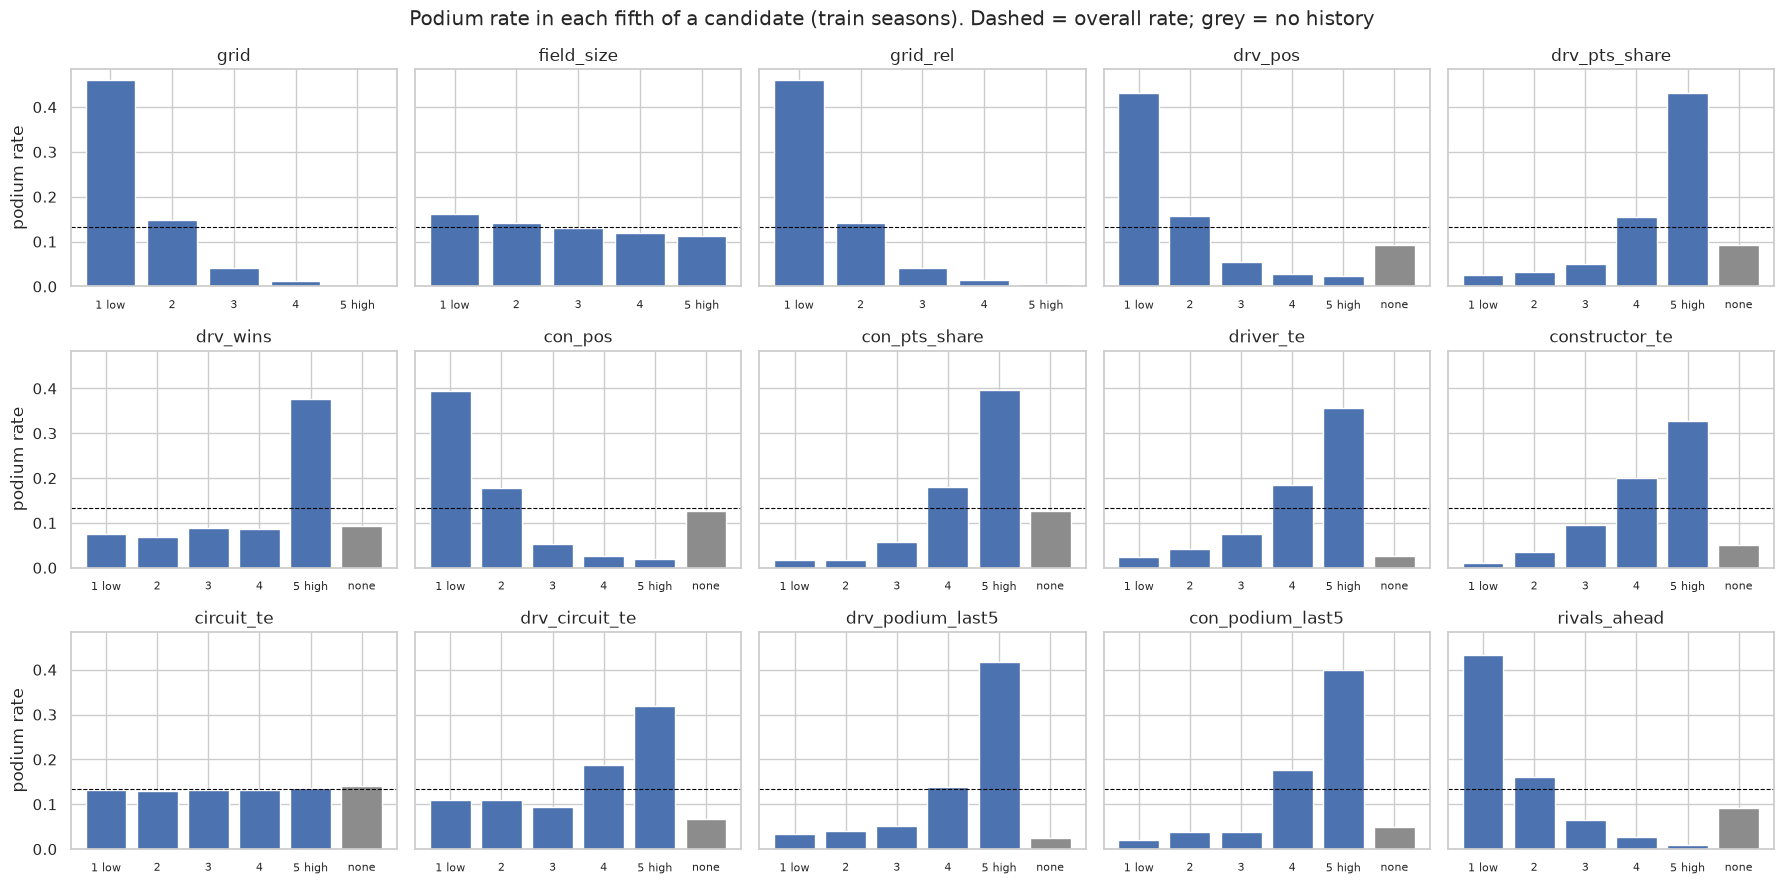

In [55]:
CANDIDATES = ["grid", "field_size", "grid_rel", "drv_pos", "drv_pts_share", "drv_wins", "con_pos", "con_pts_share",
              "driver_te", "constructor_te", "circuit_te", "drv_circuit_te", "drv_podium_last5", "con_podium_last5",
              "rivals_ahead"]
FIFTHS = ["1 low", "2", "3", "4", "5 high"]
fig, axes = plt.subplots(3, 5, figsize=(18, 9), sharey=True)
for ax, col in zip(axes.ravel(), CANDIDATES):
    x = tr[col].astype(float)
    fifth = pd.qcut(x.rank(method="first"), 5, labels=FIFTHS).astype(str).where(x.notna(), "none")
    rate = tr.groupby(fifth)["podium"].mean().reindex(FIFTHS + ["none"]).dropna()
    ax.bar(rate.index, rate.values, color=["C7" if g == "none" else "C0" for g in rate.index])
    ax.axhline(P_ALL, color="black", lw=0.8, ls="--")
    ax.set_title(col)
    ax.tick_params(axis="x", labelsize=8)
for ax in axes[:, 0]:
    ax.set_ylabel("podium rate")
fig.suptitle("Podium rate in each fifth of a candidate (train seasons). Dashed = overall rate; grey = no history")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig_16_feature_fifths.png", dpi=150)
plt.show()

Next, the correlations. Lab 1 ranks features by their correlation with the target. We use **Spearman** instead of the default Pearson, because the plots above are not straight lines (for `grid`, the podium rate drops steeply over the first few slots and then flattens). Spearman only asks "does the podium chance go up, or down, as the value grows?".

The heatmap also shows which candidates carry almost the same information as each other (values near ±1).

Spearman correlation with podium (train), strongest first:


,spearman_with_podium
grid,-0.449
grid_rel,-0.444
drv_podium_last5,0.434
con_podium_last5,0.414
rivals_ahead,-0.414
drv_wins,0.404
drv_pts_share,0.400
drv_pos,-0.400
con_pts_share,0.395
con_pos,-0.385


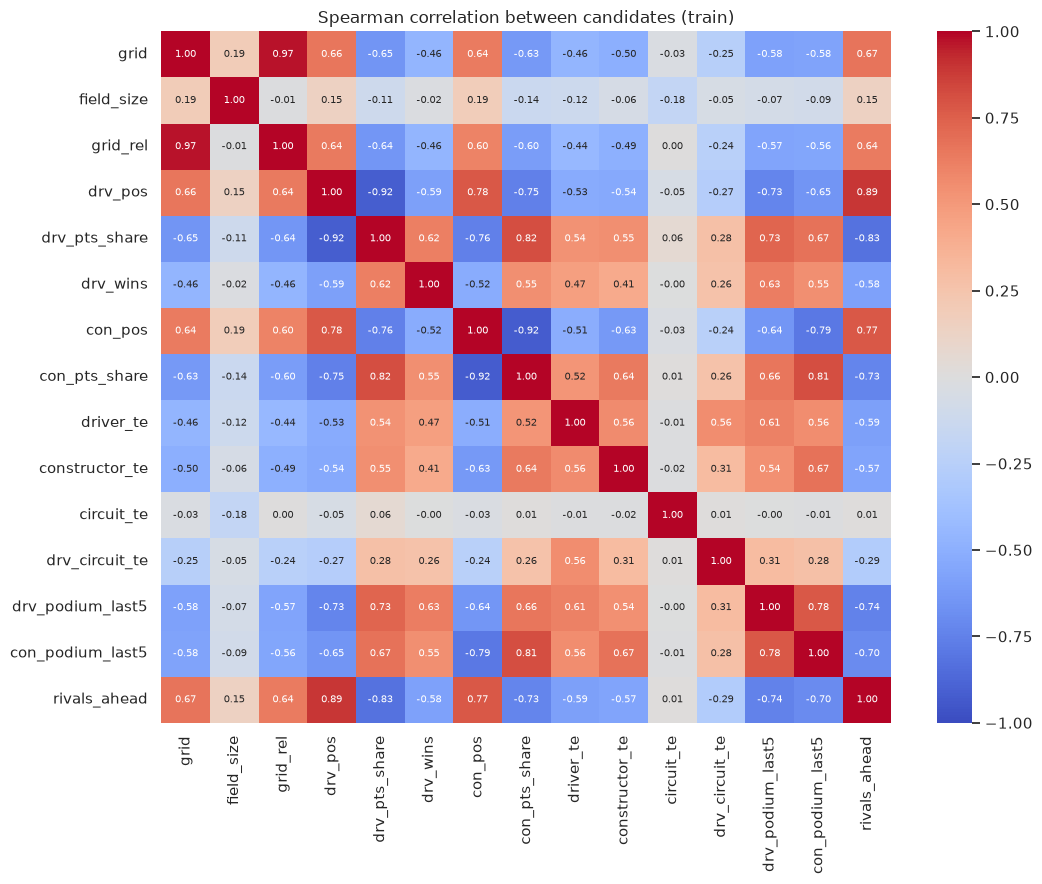

In [56]:
rho = tr[CANDIDATES].astype(float).corrwith(tr["podium"], method="spearman")
print("Spearman correlation with podium (train), strongest first:")
display(rho.reindex(rho.abs().sort_values(ascending=False).index).round(3).to_frame("spearman_with_podium"))
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(tr[CANDIDATES].astype(float).corr(method="spearman"), annot=True, fmt=".2f", cmap="coolwarm",
            center=0, vmin=-1, vmax=1, annot_kws={"size": 7}, ax=ax)
ax.set_title("Spearman correlation between candidates (train)")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig_17_feature_corr.png", dpi=150)
plt.show()

**What the plots and correlations say:**
- **Strong on their own:** `grid` / `grid_rel`, the standings, the career podium rates (`driver_te`, `constructor_te`), recent form and `rivals_ahead`. Their bars climb (or fall) steeply, from under 4% in the worst fifth to 33–46% in the best, and their correlations with podium are 0.33–0.45 in size.
- **Weak:** `drv_circuit_te` (0.20) and `field_size` (−0.05).
- **No signal at all:** `circuit_te`. Its five bars are all about 13%, the overall rate, and its correlation is 0.007. That makes sense: it describes the track (how well top-3 starters convert there), not the driver, so on its own it cannot tell drivers apart.
- **Many candidates repeat each other:** `grid` and `grid_rel` (0.97), driver position and points share (0.92), team position and points share (0.92), `rivals_ahead` and the driver's championship position (0.89), and driver and team points shares (0.82).

So the plots alone can't settle the list. Many candidates look useful on their own but carry largely the same information. The real question is what each one adds **on top of** the others, which is what 16.2 tests.

### 16.2 Adding one group at a time

We start from the simplest model, **`grid` only**, which is also our baseline. Then we add one group of candidates at a time, in the order of our four questions (start position → this season → career → circuit → recent races → rivals). Each time, we retrain two models and compare their validation PR-AUC with the last version we kept:
- **Logistic regression** (Lab 2) and **random forest** (Lab 4), with their settings fixed during this experiment (`C = 1`; 300 trees, depth 6, at least 20 rows per leaf) so that only the features change between steps. The settings are tuned in section 18, once the features are fixed.
- PR-AUC is our main metric (section 9): podiums are rare, so it is the most informative single number.

**How we decide to keep a group.** Validation has only 243 podiums, so a small change in PR-AUC can be pure luck. To see how sure each change is, we redraw the validation season 500 times: each time we pick its races at random, with repeats allowed, and recompute both scores. Whole races are drawn rather than single rows, because the drivers in one race share one result. **A group is kept only if it improves *both* models in at least 80% of these redraws.** Otherwise it is dropped and the next group is tested against the last kept version.

*[beyond labs] The redraw (a bootstrap) is not in the labs. We use it because a single validation number can't tell a real gain from luck, and the brief asks us to back every choice with evidence.*

In [57]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import average_precision_score

STEPS = [
    ("grid only (baseline)", ["grid"]),
    ("+ field size", ["field_size", "grid_rel"]),
    ("+ driver standings", ["drv_pos", "drv_pts_share", "drv_wins"]),
    ("+ team standings", ["con_pos", "con_pts_share"]),
    ("+ career podium rates", ["driver_te", "constructor_te"]),
    ("+ circuit conversion", ["circuit_te"]),
    ("+ driver at this circuit", ["drv_circuit_te"]),
    ("+ recent form (last 5)", ["drv_podium_last5", "con_podium_last5"]),
    ("+ rivals ahead", ["rivals_ahead"]),
]
LADDER_MODELS = {
    "LR": lambda: LogisticRegression(max_iter=2000),
    "RF": lambda: RandomForestClassifier(n_estimators=300, max_depth=6, min_samples_leaf=20, random_state=SEED, n_jobs=-1),
}
KEEP_SHARE = 0.8

# 500 redraws of the validation races (whole races, with repeats)
y_va = va["podium"].to_numpy()
race_rows = list(va.reset_index(drop=True).groupby("raceId").indices.values())
rng = np.random.default_rng(SEED)
REDRAWS = [np.concatenate([race_rows[i] for i in rng.integers(0, len(race_rows), len(race_rows))]) for _ in range(500)]

def val_predictions(cols):
    (Xtr, Xva, _), _, _ = make_xy(cols)
    return {m: make().fit(Xtr, tr["podium"]).predict_proba(Xva)[:, 1] for m, make in LADDER_MODELS.items()}, Xtr.shape[1]

def share_better(new, old):
    return np.mean([average_precision_score(y_va[r], new[r]) > average_precision_score(y_va[r], old[r]) for r in REDRAWS])

kept, kept_pred, ladder = [], None, []
for step, cols in STEPS:
    pred, n_inputs = val_predictions(kept + cols)
    row = {"step": step, "inputs": n_inputs}
    row.update({f"{m} val PR-AUC": average_precision_score(y_va, p) for m, p in pred.items()})
    if kept_pred is None:
        keep = True
    else:
        row.update({f"{m} better in": share_better(pred[m], kept_pred[m]) for m in pred})
        keep = all(row[f"{m} better in"] >= KEEP_SHARE for m in pred)
    row["kept"] = keep
    ladder.append(row)
    if keep:
        kept, kept_pred = kept + cols, pred
ladder = pd.DataFrame(ladder)
SELECTED = kept
display(ladder.round(3))

# For comparison: every candidate at once, no selection
all_pred, all_inputs = val_predictions([c for _, cols in STEPS for c in cols])
print(f"all 15 candidates together ({all_inputs} inputs): "
      + ", ".join(f"{m} val PR-AUC {average_precision_score(y_va, p):.3f}" for m, p in all_pred.items()))
print("selected features:", SELECTED)

,step,inputs,LR val PR-AUC,RF val PR-AUC,kept,LR better in,RF better in
0,grid only (baseline),1,0.668,0.668,True,NaN,NaN
1,+ field size,3,0.669,0.671,False,0.610,0.908
2,+ driver standings,5,0.717,0.724,True,0.996,0.998
3,+ team standings,8,0.713,0.714,False,0.146,0.058
4,+ career podium rates,9,0.729,0.738,True,0.884,0.940
5,+ circuit conversion,11,0.727,0.736,False,0.182,0.388
6,+ driver at this circuit,11,0.730,0.734,False,0.800,0.176
7,+ recent form (last 5),13,0.713,0.724,False,0.008,0.000
8,+ rivals ahead,11,0.727,0.731,False,0.166,0.014


all 15 candidates together (24 inputs): LR val PR-AUC 0.712, RF val PR-AUC 0.734
selected features: ['grid', 'drv_pos', 'drv_pts_share', 'drv_wins', 'driver_te', 'constructor_te']


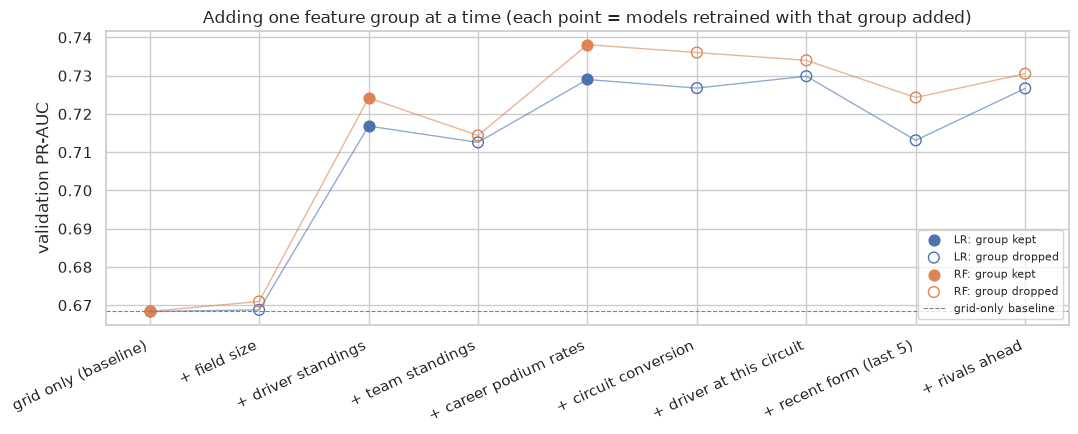

In [58]:
fig, ax = plt.subplots(figsize=(11, 4.5))
x = np.arange(len(ladder))
for m, color in [("LR", "C0"), ("RF", "C1")]:
    y = ladder[f"{m} val PR-AUC"]
    ax.plot(x, y, color=color, lw=1, alpha=0.6)
    ax.scatter(x[ladder["kept"]], y[ladder["kept"]], color=color, s=60, label=f"{m}: group kept")
    ax.scatter(x[~ladder["kept"]], y[~ladder["kept"]], facecolors="none", edgecolors=color, s=60, label=f"{m}: group dropped")
ax.axhline(ladder.loc[0, "LR val PR-AUC"], color="grey", ls="--", lw=0.8, label="grid-only baseline")
ax.set_xticks(x)
ax.set_xticklabels(ladder["step"], rotation=25, ha="right")
ax.set_ylabel("validation PR-AUC")
ax.set_title("Adding one feature group at a time (each point = models retrained with that group added)")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.savefig(FIG_DIR / "fig_18_feature_ladder.png", dpi=150)
plt.show()

**Reading the table and the plot:**
- **Driver standings** are the big step: validation PR-AUC goes from 0.668 to about 0.72 for both models, and they win in almost every redraw. How the driver is doing *this season* is the strongest thing we can add to the grid.
- **Career podium rates** (`driver_te`, `constructor_te`) add about another +0.01 and win in most redraws for both models (88% for LR, 94% for RF), so they stay. They carry long-term information the current season doesn't: who has been a front-runner for years, and which team usually is.
- **Field size** helps the forest a little but logistic regression almost never (61% of redraws), so it is dropped. `grid` already says where the driver starts.
- **Team standings** make both models *worse*. Once we know the driver's own standings and the team's career rate, the team's current standings mostly repeat the driver's (the correlation of the points shares is 0.82), and the extra columns add noise.
- **Circuit conversion** has no signal (as 16.1 showed). **Driver at this circuit** helps logistic regression in exactly 80% of redraws but the forest in only 18%. **Recent form** and **rivals ahead** both make things worse: they mostly repeat the standings and the grid.
- Putting **all 15 candidates in at once** scores *lower* than the selected set, for both models. More features are not better here.

**Chosen features (6):** `grid`, `drv_pos`, `drv_pts_share`, `drv_wins`, `driver_te`, `constructor_te`, plus the `no_history` flags for the three groups. That is 9 model inputs in total.

**Limits of this method, stated honestly:** the result can depend on the order we add groups in, and a dropped group is not tried again later. The "all candidates" row is a partial check on that. The final contribution of each kept group is measured again by the ablation after training, which the brief requires.

## 17. Preparing the chosen features

The same `make_xy` from section 15, now for the features chosen in section 16. Every model in sections 18 and 19 gets exactly these inputs, so their scores can be compared directly (brief, section 4).

9 model inputs (6 scaled features + 3 no_history flags)
fill values (train only): {'drv_pos': 12.0, 'drv_pts_share': 0.0, 'drv_wins': 0.0, 'driver_te': 0.133, 'constructor_te': 0.133}
before scaling (train, missing values filled):


,mean,std,min,max
grid,11.982,6.857,1.000,34.000
drv_pos,13.041,8.670,1.000,102.000
drv_pts_share,0.184,0.279,0.000,1.000
drv_wins,0.311,1.010,0.000,13.000
driver_te,0.137,0.118,0.009,0.624
constructor_te,0.145,0.114,0.002,0.474


after scaling (mean / std per split):


train         val          test       
                mean  std   mean    std   mean    std
grid             0.0  1.0 -0.213  0.845 -0.216  0.840
drv_pos         -0.0  1.0 -0.276  0.658 -0.270  0.671
drv_pts_share   -0.0  1.0  0.204  1.043  0.193  1.047
drv_wins        -0.0  1.0  0.167  1.463  0.231  1.841
driver_te        0.0  1.0  0.125  1.371  0.078  1.356
constructor_te  -0.0  1.0  0.382  1.332  0.313  1.418

no_history flag rate per split:


,train,val,test
no_history_standings_drv,0.128,0.052,0.050
no_history_driver_te,0.031,0.007,0.006
no_history_constructor_te,0.012,0.004,0.001


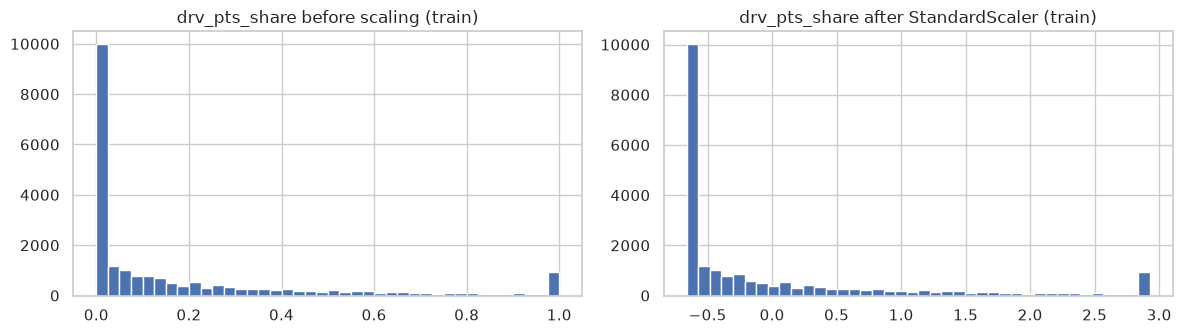

In [59]:
(X_train, X_val, X_test), scaler, fills = make_xy(SELECTED)
y_train, y_val, y_test = tr["podium"], va["podium"], te["podium"]
FEATURES = list(X_train.columns)
CONT = list(SELECTED)
FLAG_COLS = [c for c in FEATURES if c.startswith("no_history_")]

# Checks: no gaps left; train is exactly mean 0 / std 1; test is NOT (proves we didn't refit on test)
assert not X_train.isna().any().any() and not X_val.isna().any().any() and not X_test.isna().any().any()
assert np.allclose(X_train[CONT].mean(), 0, atol=1e-9) and np.allclose(X_train[CONT].std(ddof=0), 1, atol=1e-9)
assert not np.allclose(X_test[CONT].mean(), 0, atol=1e-3), "test looks refit: scaler must be fit on train only"
print(f"{len(FEATURES)} model inputs ({len(CONT)} scaled features + {len(FLAG_COLS)} no_history flags)")
print("fill values (train only):", {k: round(float(v), 3) for k, v in fills.items()})
print("before scaling (train, missing values filled):")
filled = tr[CONT].astype(float).fillna(fills)
display(filled.describe().T[["mean", "std", "min", "max"]].round(3))
print("after scaling (mean / std per split):")
display(pd.concat({"train": X_train[CONT].agg(["mean", "std"]).T,
                   "val": X_val[CONT].agg(["mean", "std"]).T,
                   "test": X_test[CONT].agg(["mean", "std"]).T}, axis=1).round(3))
print("no_history flag rate per split:")
display(pd.DataFrame({"train": X_train[FLAG_COLS].mean(), "val": X_val[FLAG_COLS].mean(), "test": X_test[FLAG_COLS].mean()}).round(3))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].hist(filled["drv_pts_share"], bins=40)
axes[0].set_title("drv_pts_share before scaling (train)")
axes[1].hist(X_train["drv_pts_share"], bins=40)
axes[1].set_title("drv_pts_share after StandardScaler (train)")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig_19_scaling.png", dpi=150)
plt.show()

**Summary:** the chosen features are filled using values from the training data, flagged, and scaled. After scaling, train has exactly mean 0 and standard deviation 1. Validation and test are close but not exact, which is expected and shows the scaler was not refitted on them. Scaling only shifts and stretches the values (the histogram keeps its shape), so the order of drivers on every feature is unchanged.

`drv_pts_share` has a big spike at 0: early in a season, or for back-markers, many drivers have no points yet.

## 18. First models: baseline, logistic regression, random forest (M5)

Every model gets the same rows and the same inputs, the ones chosen in section 16.

- **Baseline: logistic regression on `grid` only.** The brief asks for a statistical model as the baseline. It is also the first step of the section 16 ladder, so we already know what it scores. Any real model has to beat it, otherwise the extra features add nothing.
- **Logistic regression** and **random forest** on all the chosen inputs.

**Choosing settings:** we try every combination of
- class weighting: none, or `balanced` (gives the rare podium rows more weight during training),
- model settings: regularisation strength `C` for logistic regression; tree depth and minimum leaf size for the random forest,

and keep the combination with the best **validation PR-AUC**.

**From scores to yes/no:** the models output a probability. We pick the cut-off (threshold) that gives the best **F1** on validation.

The **test set is not touched here**. It's scored only once, at the very end, after all models are final; looking at it earlier would mean quietly tuning to it.

In [60]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_recall_curve,
                             f1_score, precision_score, recall_score, accuracy_score)

# All scores for one model. PR-AUC and ROC-AUC use the raw scores; F1, precision, recall and
# accuracy need yes/no predictions, so they use the threshold `thr`.
def metrics(y, score, thr):
    pred = (score >= thr).astype(int)
    return {"PR-AUC": average_precision_score(y, score), "ROC-AUC": roc_auc_score(y, score),
            "F1": f1_score(y, pred), "Precision": precision_score(y, pred, zero_division=0),
            "Recall": recall_score(y, pred), "Accuracy": accuracy_score(y, pred)}

# The score cut-off that gives the best F1 (balance between precision and recall)
def best_f1_threshold(y, score):
    p, r, t = precision_recall_curve(y, score)
    return t[(2 * p * r / (p + r + 1e-12))[:-1].argmax()]

# 18.1 Try every combination of class weighting x model settings: train on train, score on
# validation (PR-AUC). The test set is not used.
MODELS = {
    "LR": (lambda cw, **k: LogisticRegression(max_iter=2000, class_weight=cw, random_state=SEED, **k),
           [{"C": c} for c in (0.01, 0.1, 1, 10)]),
    "RF": (lambda cw, **k: RandomForestClassifier(n_estimators=300, class_weight=cw, random_state=SEED, n_jobs=-1, **k),
           [{"max_depth": d, "min_samples_leaf": l} for d in (4, 6, 8) for l in (20, 50)]),
}
rows, fitted = [], {}
for name, (make, grid) in MODELS.items():
    for cw in (None, "balanced"):
        for params in grid:
            m = make(cw, **params).fit(X_train, y_train)
            pv = m.predict_proba(X_val)[:, 1]
            rows.append({"model": name, "class_weight": cw or "none", "params": str(params),
                         "val_PR-AUC": average_precision_score(y_val, pv), "val_ROC-AUC": roc_auc_score(y_val, pv)})
            fitted[len(rows) - 1] = m
tuning = pd.DataFrame(rows)
display(tuning.sort_values(["model", "val_PR-AUC"], ascending=[True, False]).round(4))
print("best validation PR-AUC per model and class weight:")
display(tuning.groupby(["model", "class_weight"])["val_PR-AUC"].max().unstack().round(4))
# Keep the best combination for each model type
best = tuning.loc[tuning.groupby("model")["val_PR-AUC"].idxmax()]
lr_best, rf_best = fitted[best.index[best["model"] == "LR"][0]], fitted[best.index[best["model"] == "RF"][0]]
print("selected:")
print(best[["model", "class_weight", "params", "val_PR-AUC"]].to_string(index=False))

,model,class_weight,params,val_PR-AUC,val_ROC-AUC
3,LR,none,{'C': 10},0.7291,0.9322
2,LR,none,{'C': 1},0.7290,0.9322
1,LR,none,{'C': 0.1},0.7283,0.9323
7,LR,balanced,{'C': 10},0.7258,0.9326
6,LR,balanced,{'C': 1},0.7257,0.9326
5,LR,balanced,{'C': 0.1},0.7251,0.9326
0,LR,none,{'C': 0.01},0.7235,0.9329
4,LR,balanced,{'C': 0.01},0.7229,0.9329
12,RF,none,"{'max_depth': 8, 'min_samples_leaf': 20}",0.7405,0.9380
10,RF,none,"{'max_depth': 6, 'min_samples_leaf': 20}",0.7381,0.9371


best validation PR-AUC per model and class weight:


class_weight,balanced,none
model,,
LR,0.7258,0.7291
RF,0.7362,0.7405


selected:
model class_weight                                   params  val_PR-AUC
   LR         none                                {'C': 10}    0.729114
   RF         none {'max_depth': 8, 'min_samples_leaf': 20}    0.740532


PR-AUC  ROC-AUC     F1  Precision  Recall  Accuracy
Baseline (LR on grid) train   0.487    0.881  0.534      0.533   0.535     0.876
                      val     0.668    0.918  0.712      0.712   0.712     0.914
Logistic regression   train   0.555    0.896  0.538      0.575   0.506     0.884
                      val     0.729    0.932  0.719      0.671   0.774     0.909
Random forest         train   0.622    0.915  0.531      0.664   0.443     0.896
                      val     0.741    0.938  0.723      0.738   0.708     0.918

F1-optimal thresholds chosen on validation: {'Baseline (LR on grid)': 0.427, 'Logistic regression': 0.412, 'Random forest': 0.488}


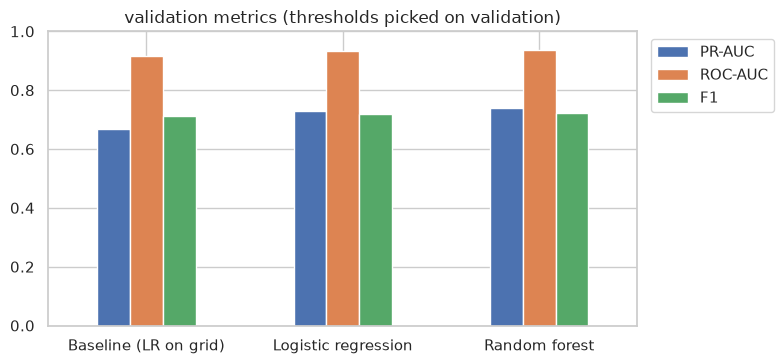

In [61]:
# 18.2 Pick each model's threshold on validation, then report all metrics on train and validation.
# Baseline = logistic regression on grid only. (Test still untouched.)
base_lr = LogisticRegression(max_iter=2000).fit(X_train[["grid"]], y_train)
score = {"Baseline (LR on grid)": (lambda X: base_lr.predict_proba(X[["grid"]])[:, 1]), "Logistic regression": (lambda X: lr_best.predict_proba(X)[:, 1]),
         "Random forest": (lambda X: rf_best.predict_proba(X)[:, 1])}
THR = {k: best_f1_threshold(y_val, f(X_val)) for k, f in score.items()}
table = pd.DataFrame({(k, s): metrics(y, f(X), THR[k]) for k, f in score.items()
                      for s, X, y in [("train", X_train, y_train), ("val", X_val, y_val)]}).T
display(table.round(3))
print("F1-optimal thresholds chosen on validation:", {k: round(float(v), 3) for k, v in THR.items()})
fig, ax = plt.subplots(figsize=(8, 3.8))
table.xs("val", level=1)[["PR-AUC", "ROC-AUC", "F1"]].plot.bar(ax=ax, rot=0)
ax.set_ylim(0, 1)
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
ax.set_title("validation metrics (thresholds picked on validation)")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig_20_models_val.png", dpi=150)
plt.show()
# Both real models must beat the grid-only baseline, otherwise they add nothing
assert table.loc[("Logistic regression", "val"), "PR-AUC"] > table.loc[("Baseline (LR on grid)", "val"), "PR-AUC"], "LR must beat the baseline"
assert table.loc[("Random forest", "val"), "PR-AUC"] > table.loc[("Baseline (LR on grid)", "val"), "PR-AUC"], "RF must beat the baseline"

In [62]:
# Log the model decision (M5)
DECISIONS.append((21, "M5: models = logistic regression + random forest (+ shallow NN to come), baseline -grid", "decided",
    "2026-10-06: class weight and grid chosen on validation PR-AUC, threshold = F1-optimal on validation, "
    "test scored once after the NN is added"))
print(f"Total Decisions Logged: {len(DECISIONS)}")

Total Decisions Logged: 21


## 19. Small neural network (M6)

Same inputs as the other models (chosen in section 16), built with Keras (Lab 3):
- 1 or 2 hidden layers; we try sizes (16), (32) and (32 → 16) neurons, with ReLU activation.
- One output neuron with sigmoid, which gives a podium probability between 0 and 1.
- Trained with the Adam optimiser and binary cross-entropy loss, no class weights (following M5).
- **Early stopping:** training stops when the validation loss hasn't improved for 15 epochs, and the network goes back to its best epoch. This prevents overfitting (memorising the training data).

The size is picked by validation PR-AUC, and the threshold by the best F1 on validation. Then all four models are compared side by side on validation. The test set is still untouched.

,hidden_units,epochs_run,best_val_loss,val_PR-AUC,val_ROC-AUC
0,"(16,)",185,0.2192,0.7358,0.9368
1,"(32,)",200,0.2213,0.7287,0.9354
2,"(32, 16)",70,0.2237,0.7246,0.9337


selected architecture: (16,)


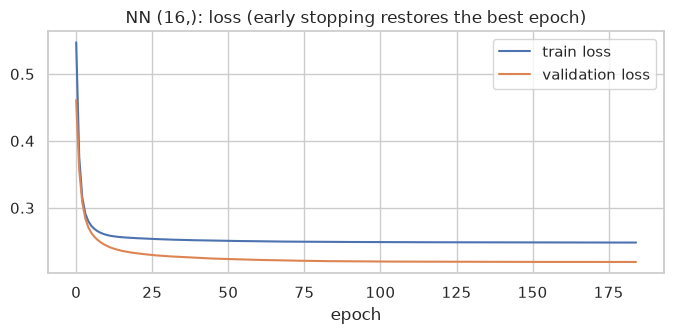

In [63]:
assert TF_OK, "TensorFlow/Keras is required for the neural network (preinstalled on Kaggle)"
from tensorflow.keras import layers
# Keras wants plain float arrays instead of DataFrames
Xtr, Xva = X_train.to_numpy("float32"), X_val.to_numpy("float32")
ytr, yva = y_train.to_numpy(), y_val.to_numpy()

# A small network: hidden layers of the given sizes (ReLU), one sigmoid output = podium probability
def build_nn(units):
    keras.utils.set_random_seed(SEED)  # same seed for every model so runs are repeatable
    m = keras.Sequential([keras.Input(shape=(Xtr.shape[1],))]
                         + [layers.Dense(u, activation="relu") for u in units] + [layers.Dense(1, activation="sigmoid")])
    m.compile(optimizer=keras.optimizers.Adam(1e-3), loss="binary_crossentropy")
    return m

nn_rows, nn_models, nn_hist = [], {}, {}
# Try three sizes. Training stops when validation loss hasn't improved for 15 epochs,
# then rolls back to the best epoch (prevents overfitting).
for units in [(16,), (32,), (32, 16)]:
    m = build_nn(units)
    stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=15, restore_best_weights=True)
    h = m.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=200, batch_size=256, callbacks=[stop], verbose=0)
    pv = m.predict(Xva, verbose=0).ravel()
    nn_rows.append({"hidden_units": str(units), "epochs_run": len(h.history["loss"]), "best_val_loss": min(h.history["val_loss"]),
                    "val_PR-AUC": average_precision_score(yva, pv), "val_ROC-AUC": roc_auc_score(yva, pv)})
    nn_models[str(units)], nn_hist[str(units)] = m, h.history
nn_tuning = pd.DataFrame(nn_rows)
display(nn_tuning.round(4))
nn_units = nn_tuning.loc[nn_tuning["val_PR-AUC"].idxmax(), "hidden_units"]
nn_best = nn_models[nn_units]
print("selected architecture:", nn_units)
# Loss curves of the chosen network: validation loss rising while train loss falls = overfitting
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(nn_hist[nn_units]["loss"], label="train loss")
ax.plot(nn_hist[nn_units]["val_loss"], label="validation loss")
ax.set_xlabel("epoch"); ax.set_title(f"NN {nn_units}: loss (early stopping restores the best epoch)"); ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "fig_21_nn_loss.png", dpi=150)
plt.show()

PR-AUC  ROC-AUC     F1  Precision  Recall  Accuracy
Baseline (LR on grid) train   0.487    0.881  0.534      0.533   0.535     0.876
                      val     0.668    0.918  0.712      0.712   0.712     0.914
Logistic regression   train   0.555    0.896  0.538      0.575   0.506     0.884
                      val     0.729    0.932  0.719      0.671   0.774     0.909
Random forest         train   0.622    0.915  0.531      0.664   0.443     0.896
                      val     0.741    0.938  0.725      0.739   0.712     0.919
Neural network        train   0.566    0.902  0.556      0.566   0.546     0.884
                      val     0.736    0.937  0.724      0.690   0.761     0.913

F1-optimal thresholds chosen on validation: {'Baseline (LR on grid)': 0.427, 'Logistic regression': 0.412, 'Random forest': 0.488, 'Neural network': 0.395}


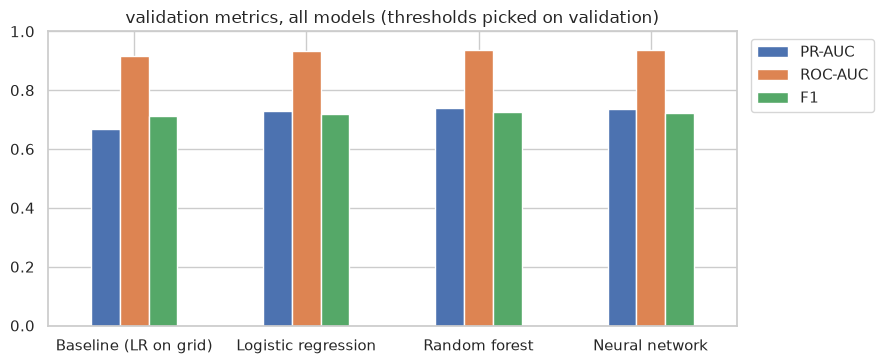

In [64]:
# All four models side by side on train and validation (thresholds picked on validation; test still untouched)
score["Neural network"] = lambda X: nn_best.predict(X.to_numpy("float32"), verbose=0).ravel()
THR["Neural network"] = best_f1_threshold(y_val, score["Neural network"](X_val))
table = pd.DataFrame({(k, s): metrics(y, f(X), THR[k]) for k, f in score.items()
                      for s, X, y in [("train", X_train, y_train), ("val", X_val, y_val)]}).T
display(table.round(3))
print("F1-optimal thresholds chosen on validation:", {k: round(float(v), 3) for k, v in THR.items()})
fig, ax = plt.subplots(figsize=(9, 3.8))
table.xs("val", level=1)[["PR-AUC", "ROC-AUC", "F1"]].plot.bar(ax=ax, rot=0)
ax.set_ylim(0, 1)
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
ax.set_title("validation metrics, all models (thresholds picked on validation)")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig_22_models_val_all.png", dpi=150)
plt.show()
assert table.loc[("Neural network", "val"), "PR-AUC"] > table.loc[("Baseline (LR on grid)", "val"), "PR-AUC"], "NN must beat the baseline"

In [65]:
# Log the neural network decision (M6)
DECISIONS.append((22, "M6: shallow Keras NN, layer sizes chosen on validation PR-AUC", "decided",
    "2026-10-06: Sequential Dense(relu) x1-2 + sigmoid, Adam, early stopping on val loss, no class weights; "
    "candidates (16), (32), (32,16); test still scored once for all models"))
# Decisions from the 2026-10-09 review
DECISIONS.extend([
    (23, "Q1 uses results.grid only (no qualifying position)", "decided",
     "2026-10-09: supersedes #5 and #13. Grid is where the car actually starts (after penalties) and exists "
     "for every race since 1950; qualifying is missing for most seasons before 2003"),
    (24, "Q3: every unclear retirement counts as mechanical, except Refuelling", "decided",
     "2026-10-09: supersedes the strict/broad split in #7 and #16. Punctures, wing failures, fire, "
     "out of fuel, 'Retired' etc. -> mechanical; Refuelling -> other. One rate per period: 11.2% (2014-21) vs 6.9% (2022-24)"),
    (25, "One spelling per value, fixed during cleaning (before any analysis)", "decided",
     "2026-10-09: nationality variants unified (Argentinian -> Argentine, double nationalities -> first, "
     "East German -> German), circuits United States -> USA, drivers get home_country in the circuits' "
     "spelling (moves the #6 mapping into cleaning step 3). The raw-data Q1-Q3 preview section was removed"),
    (26, "Features chosen by adding one group at a time (section 16)", "decided",
     "2026-10-11: supersedes the feature list in #19 (M3) and field_size/grid_rel in #17. 15 candidates; start from grid, "
     "keep a group only if it improves validation PR-AUC of both LR and RF in >=80% of 500 race redraws. "
     "Kept: grid, driver standings (drv_pos, drv_pts_share, drv_wins), driver_te, constructor_te (+3 no_history flags). "
     "Baseline is now logistic regression on grid only (statistical baseline, brief)"),
])
print(f"Total Decisions Logged: {len(DECISIONS)}")

Total Decisions Logged: 26


## 20. What's next

**Done:** sections 2–19: data checks, cleaning, the three data questions, candidate features, feature selection by adding one group at a time, preprocessing, and the baseline + logistic regression + random forest + neural network compared on validation.

**Still to do** (see `PLAN.md`):
- Score every model **once** on the test set (2022–2024).
- Ablation: remove one kept group at a time from the trained models to measure what each one contributes.
- Explainability (XAI) with SHAP and LIME: which features push a prediction up or down.
- Inference: use the final model to predict podiums for a race.
- The final report.

In [66]:
# Final safety check (keep this as the last cell): recompute the raw files' fingerprints and
# confirm they match the ones taken at load time, i.e. we never modified the original data.
import hashlib
for t in TABLES:
    h = hashlib.sha256()
    with open(RAW_DIR / f"{t}.csv", "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    assert h.hexdigest() == RAW_CHECKSUMS[t], f"raw {t}.csv changed since load!"
print("raw integrity OK: all 14 checksums match (Gate: raw files never modified)")

raw integrity OK: all 14 checksums match (Gate: raw files never modified)
